# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [102]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

*Sua resposta aqui*

| Frente | Pergunta de negócio | Colunas usadas | Granularidade |
|---|---|---|---|
| Operação | Em quais combinações de dia da semana e horário se concentram mais pedidos e entregas mais demoradas? | `data_hora`, `pedido_id`, `tempo_entrega_min` | Dia da semana × hora |
| Clientes | Pedidos que demoram mais para chegar tendem a receber notas mais baixas? | `tempo_entrega_min`, `avaliacao` | Pedido |
| Operação e clientes | Os tipos de cozinha com entregas mais rápidas também têm as melhores avaliações? | `tipo_cozinha`, `tempo_entrega_min`, `avaliacao` | Tipo de cozinha |
| Alavancas | Qual é a diferença no valor médio entre pedidos com e sem cupom para clientes novos e para os demais? | `cupom`, `valor_pedido`, `cliente_novo` | Pedido, com comparação por perfil de cliente |
| Clientes | Pedidos com taxa de entrega mais alta tendem a receber notas mais baixas? | `taxa_entrega`, `avaliacao` | Pedido |

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

*Sua resposta aqui*

| Hipótese de negócio | H₀ — Hipótese nula | H₁ — Hipótese alternativa | Teste e justificativa |
|---|---|---|---|
| **H1 — Chuva e tempo de entrega** | A distribuição dos tempos de entrega é igual nos pedidos com e sem chuva. | Os tempos de entrega tendem a ser maiores nos pedidos com chuva. | **Mann–Whitney unilateral.** Compara os tempos de dois grupos pela ordem dos valores. A hipótese indica uma direção. |
| **H2 — Cupom e valor do pedido** | A distribuição do valor dos pedidos é igual nos grupos com e sem cupom. | Os valores dos pedidos tendem a ser maiores em um dos dois grupos. | **Mann–Whitney bilateral.** Compara os valores dos pedidos entre dois grupos e considera diferenças nos dois sentidos. |
| **H3 — Tempo de entrega e avaliação** | A correlação de Spearman entre tempo e avaliação é zero. | A correlação é negativa. Pedidos mais demorados tendem a receber notas menores. | **Spearman unilateral.** O tempo é numérico, e as notas têm uma ordem. |
| **H4 — Tipo de cozinha e valor do pedido** | A distribuição do valor dos pedidos é igual em todos os tipos de cozinha. | Em pelo menos um tipo de cozinha, os valores tendem a ser maiores ou menores do que em outro. | **Kruskal–Wallis.** Compara os valores dos pedidos pela ordem dos valores entre mais de dois grupos. |
| **H5 — Cidade e forma de pagamento** | Cidade e forma de pagamento são independentes. | Existe associação entre cidade e forma de pagamento. | **Qui-quadrado de independência.** As duas variáveis são categóricas, então o teste compara as contagens observadas com as esperadas. |
| **H6 — Taxa de entrega e avaliação** | A correlação de Spearman entre taxa de entrega e avaliação é zero. | A correlação é negativa. Pedidos com taxas maiores tendem a receber notas menores. | **Spearman unilateral.** A taxa é numérica, e as notas têm uma ordem. |

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [103]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [104]:
# Sua solução aqui
display(bruto.head())
print("Linhas e colunas:", bruto.shape)
bruto.info(memory_usage="deep")

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


Linhas e colunas: (8058, 18)
<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais  

A base original tem 8.058 linhas e 18 colunas. Cada linha representa
um pedido. Usei `head()` para mostrar os cinco primeiros pedidos e
`info()` para conferir a estrutura da base, que ocupa 5,4 MB de memória.

Três colunas têm valores faltantes. São 153 em `plataforma`,
315 em `distancia_km` e 1.342 em `avaliacao`.

O pandas leu 11 colunas como texto, 2 como números inteiros,
3 como números decimais e 2 como booleanas. Entre as colunas
lidas como texto estão `data_hora` e `valor_pedido`, que serão
verificadas na próxima tarefa.

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [105]:
# Sua solução aqui
print(bruto[["data_hora", "cupom", "valor_pedido"]].dtypes)

valores = bruto["valor_pedido"]
teste = pd.to_numeric(valores, errors="coerce")
falhas = valores.notna() & teste.isna()

print("\nValores preenchidos que falharam na conversão:", falhas.sum())
print(valores[falhas].head())

data_hora       str
cupom           str
valor_pedido    str
dtype: object

Valores preenchidos que falharam na conversão: 720
0      R$ 44,02
18     R$ 36,08
28     R$ 35,49
33     R$ 60,70
39    R$ 105,27
Name: valor_pedido, dtype: str


*Sua resposta aqui*

As colunas `data_hora`, `cupom` e `valor_pedido` vieram como texto.
`data_hora` representa a data e o horário do pedido. `cupom` indica
se houve uso de cupom (`Sim` ou `Não`). `valor_pedido` representa
um valor em dinheiro.

Na tentativa de converter `valor_pedido` diretamente para número,
720 valores preenchidos falharam. Um exemplo é `R$ 44,02`.
As conversões serão feitas na etapa de limpeza dos dados.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [106]:
# Sua solução aqui
print("Quantidade de valores distintos por coluna")
print(bruto.nunique())

print("\nValores de cidade")
print(bruto["cidade"].unique().tolist())

print("\nValores de forma de pagamento")
print(bruto["forma_pagamento"].unique().tolist())

Quantidade de valores distintos por coluna
pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64

Valores de cidade
['São Paulo', 'Rio', 'Rio de Janeiro', 'Belo Horizonte', 'BH', 'SÃO PAULO', 'sao paulo', 'rio de janeiro', 'SP', 'São Paulo ', 'B. Horizonte', 'belo horizonte', 'RJ']

Valores de forma de pagamento
['Pix', 'cartao credito', 'Cartão de crédito', 'Vale-refeição', 'Dinheiro', 'dinheiro', 'PIX', 'VR']


*Sua resposta aqui*

A contagem de valores distintos mostrou diferenças na escrita de
algumas categorias.

A coluna `cidade` apresentou 13 grafias para as três cidades.
Por exemplo, `SP` e `São Paulo` aparecem como valores diferentes,
apesar de representarem a mesma cidade.

A coluna `forma_pagamento` apresentou oito grafias para quatro
formas de pagamento. Por exemplo, `Pix` e `PIX` aparecem como
categorias diferentes.

Essas diferenças podem separar pedidos que deveriam ser contados
juntos. A padronização será feita na Etapa 3, de limpeza dos dados.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [107]:
# Sua solução aqui
quantidade = bruto.isna().sum()

tabela_faltantes = pd.DataFrame({
    "Quantidade": quantidade,
    "Percentual (%)": (quantidade / len(bruto) * 100).round(2)
})

tabela_faltantes = tabela_faltantes[tabela_faltantes["Quantidade"] > 0]
tabela_faltantes.sort_values("Quantidade", ascending=False)

,Quantidade,Percentual (%)
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


Encontrei valores faltantes em três colunas. A coluna `avaliacao`
teve o maior percentual, com 1.342 pedidos sem nota (16,65%).
Em seguida vieram `distancia_km`, com 315 valores faltantes (3,91%),
e `plataforma`, com 153 (1,90%).

Os percentuais foram calculados sobre os 8.058 pedidos da base original.
Na limpeza dos dados, vou avaliar como tratar os faltantes de cada coluna.

### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [108]:
# Sua solução aqui
display(bruto.select_dtypes(include="number").describe().T)

tempo = bruto["tempo_entrega_min"]
distancia = bruto["distancia_km"]

print("Tempos negativos:", (tempo < 0).sum())
print("Tempos iguais a 999 minutos:", (tempo == 999).sum())
print("Distâncias negativas:", (distancia < 0).sum())
print("Maior distância registrada (km):", distancia.max())

,count,mean,std,min,25%,50%,75%,max
pedido_id,8058.0,504028.500000,2326.288568,500000.00,502014.25,504028.50,506042.7500,508057.00
distancia_km,7743.0,3.797731,9.409026,0.08,1.77,3.03,4.7700,399.65
tempo_entrega_min,8058.0,38.848349,54.728561,-33.00,28.00,35.00,43.0000,999.00
taxa_entrega,8058.0,7.268727,3.285336,0.00,6.16,7.42,9.0775,26.94
avaliacao,6716.0,4.348868,0.685299,1.00,4.00,4.00,5.0000,5.00


Tempos negativos: 8
Tempos iguais a 999 minutos: 25
Distâncias negativas: 0
Maior distância registrada (km): 399.65


*Sua resposta aqui*

Encontrei 8 tempos de entrega negativos, que são impossíveis.
Também encontrei 25 registros com exatamente 999 minutos.
A repetição desse valor sugere que ele pode ser um código específico.
Ao todo, sinalizei 33 registros na coluna `tempo_entrega_min`.

Em `distancia_km`, não encontrei valores negativos. A maior
distância foi de 399,65 km, bem acima da mediana de 3,03 km.
Vou investigar esse valor na etapa de outliers antes de decidir
se precisa de correção.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [109]:
# Sua solução aqui
linhas_duplicadas = bruto.duplicated().sum()
ids_repetidos = bruto["pedido_id"].duplicated().sum()

print("Linhas totalmente duplicadas:", linhas_duplicadas)
print("Registros com pedido_id repetido:", ids_repetidos)

Linhas totalmente duplicadas: 0
Registros com pedido_id repetido: 0


*Sua resposta aqui*

Na base original, encontrei 0 linhas totalmente duplicadas e
0 registros com `pedido_id` repetido. Os 8.058 registros têm
8.058 identificadores distintos, então não será necessário
remover linhas por duplicidade na etapa de limpeza.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

*Sua resposta aqui*

| Problema | Coluna | Linhas afetadas | Decisão planejada |
|---|---|---:|---|
| Data e hora em texto | `data_hora` | 8.058 | Converter para data e hora. |
| Cupom em texto | `cupom` | 8.058 | Converter `Sim` para `True` e `Não` para `False`. |
| Valores em formatos diferentes | `valor_pedido` | 720 | Padronizar os valores e converter a coluna para número. |
| Nomes de cidades escritos de formas diferentes | `cidade` | 997 | Usar um nome padrão para cada uma das três cidades. |
| Formas de pagamento escritas de formas diferentes | `forma_pagamento` | 666 | Usar um nome padrão para cada uma das quatro formas de pagamento. |
| Colunas com um único valor | `pais` e `moeda` | 8.058 em cada coluna | Retirar essas colunas da cópia usada na análise. |
| Nota faltando | `avaliacao` | 1.342 | Verificar se as notas faltam mais em certos grupos e manter os valores ausentes (`NaN`). |
| Distância faltando | `distancia_km` | 315 | Manter como valor ausente (`NaN`). |
| Plataforma faltando | `plataforma` | 153 | Agrupar esses pedidos como `Não informada` nos resumos por plataforma. |
| Tempos negativos ou iguais a 999 minutos | `tempo_entrega_min` | 33 (8 negativos e 25 iguais a 999) | Marcar esses tempos como ausentes (`NaN`) e sinalizar os pedidos na coluna `tempo_invalido`. |
| Distâncias muito altas | `distancia_km` | A verificar na Etapa 4 | Investigar os casos, incluindo a distância de 399,65 km, antes de decidir se precisam de correção. |
| Linhas duplicadas ou IDs repetidos | Todas as colunas e `pedido_id` | 0 | Manter todos os pedidos. |

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [110]:
# Sua solução aqui
valores_distintos = bruto.nunique(dropna=False)
colunas_constantes = valores_distintos[valores_distintos == 1].index

df = bruto.drop(columns=colunas_constantes).copy()

print("Colunas constantes:", colunas_constantes.tolist())
print("Base original:", bruto.shape)
print("Cópia para limpeza:", df.shape)

Colunas constantes: ['pais', 'moeda']
Base original: (8058, 18)
Cópia para limpeza: (8058, 16)


Usei `nunique()` para identificar as colunas com um único valor.
O código encontrou `pais` e `moeda`. Retirei essas duas colunas
da cópia `df` porque elas têm o mesmo valor em todos os pedidos.

A cópia ficou com 8.058 linhas e 16 colunas. A base original
`bruto` continua com 8.058 linhas e 18 colunas.

### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [111]:
# Sua solução aqui
df["data_hora"] = pd.to_datetime(df["data_hora"], format="%Y-%m-%d %H:%M")

df["data"] = df["data_hora"].dt.date
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour

dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
nomes_dias = dict(enumerate(dias))

df["dia_semana"] = pd.Categorical(
    df["data_hora"].dt.dayofweek.map(nomes_dias),
    categories=dias,
    ordered=True
)

display(df[["data_hora", "data", "mes", "hora", "dia_semana"]].head())

inicio = df["data_hora"].min()
fim = df["data_hora"].max()
print(f"Período coberto: {inicio:%d/%m/%Y %H:%M} a {fim:%d/%m/%Y %H:%M}")

,data_hora,data,mes,hora,dia_semana
0,2024-01-01 11:21:00,2024-01-01,1,11,Seg
1,2024-01-01 20:09:00,2024-01-01,1,20,Seg
2,2024-01-01 11:20:00,2024-01-01,1,11,Seg
3,2024-01-01 22:14:00,2024-01-01,1,22,Seg
4,2024-01-01 12:50:00,2024-01-01,1,12,Seg


Período coberto: 01/01/2024 11:11 a 31/12/2024 23:38


Converti `data_hora` para o tipo data e hora na cópia `df`.
A partir dela, criei `data` com a data sem o horário, `mes` com
o número do mês, `hora` com a hora do pedido e `dia_semana`
como categoria ordenada de segunda a domingo.

Os pedidos vão de 01/01/2024 às 11:11 até 31/12/2024 às 23:38.
Essas colunas vão ajudar a analisar os pedidos por mês, dia da
semana e horário.

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [112]:
# Sua solução aqui
mapa_cidades = {
    "são paulo": "São Paulo",
    "sao paulo": "São Paulo",
    "sp": "São Paulo",
    "rio": "Rio de Janeiro",
    "rio de janeiro": "Rio de Janeiro",
    "rj": "Rio de Janeiro",
    "belo horizonte": "Belo Horizonte",
    "b. horizonte": "Belo Horizonte",
    "bh": "Belo Horizonte",
}

cidades = bruto["cidade"].str.strip().str.lower()
df["cidade"] = cidades.map(mapa_cidades)

print("Pedidos por cidade:")
print(df["cidade"].value_counts())

print("\nCidades distintas:", df["cidade"].nunique())
print("Pedidos sem cidade:", df["cidade"].isna().sum())

Pedidos por cidade:
cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

Cidades distintas: 3
Pedidos sem cidade: 0


*Sua resposta aqui*

Padronizei os nomes da coluna `cidade` na cópia `df`. Retirei
espaços extras e reuni as grafias e siglas que representavam a
mesma cidade. Por exemplo, `SP` e `SÃO PAULO` ficaram como `São Paulo`.

A coluna passou de 13 grafias para três cidades: São Paulo,
Rio de Janeiro e Belo Horizonte. A conferência mostrou que
nenhum pedido ficou sem cidade.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [113]:
# Sua solução aqui
mapa_pagamentos = {
    "pix": "Pix",
    "cartao credito": "Cartão de crédito",
    "cartão de crédito": "Cartão de crédito",
    "vale-refeição": "Vale-refeição",
    "vr": "Vale-refeição",
    "dinheiro": "Dinheiro",
}

pagamentos = bruto["forma_pagamento"].str.strip().str.lower()
df["forma_pagamento"] = pagamentos.map(mapa_pagamentos)

print(df["forma_pagamento"].value_counts())
print("\nFormas de pagamento distintas:", df["forma_pagamento"].nunique())
print("Pedidos sem forma de pagamento:", df["forma_pagamento"].isna().sum())

forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64

Formas de pagamento distintas: 4
Pedidos sem forma de pagamento: 0


Padronizei a coluna `forma_pagamento` na cópia `df`. Por exemplo,
`Pix` e `PIX` ficaram como `Pix`, e `VR` ficou como `Vale-refeição`.

A coluna passou de oito grafias para quatro formas de pagamento.
A conferência mostrou que nenhum pedido ficou sem essa informação.

### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [114]:
# Sua solução aqui
valor = bruto["valor_pedido"].str.replace("R$", "", regex=False).str.strip()

# Ajusta os valores escritos com vírgula decimal
tem_virgula = valor.str.contains(",", regex=False, na=False)
valor.loc[tem_virgula] = (
    valor.loc[tem_virgula]
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

valor_numerico = pd.to_numeric(valor, errors="coerce")
faltantes = valor_numerico.isna()

print("Valores ausentes após a conversão:", faltantes.sum())

if faltantes.any():
    print("Exemplos de valores que precisam de revisão:")
    print(bruto.loc[faltantes, "valor_pedido"].head())
    raise ValueError("Revise os valores antes de atualizar df.")

df["valor_pedido"] = valor_numerico
print("Tipo final:", df["valor_pedido"].dtype)

Valores ausentes após a conversão: 0
Tipo final: float64


*Sua resposta aqui*

Padronizei os formatos da coluna `valor_pedido` e converti os
valores para número na cópia `df`. Por exemplo, `R$ 44,02`
foi convertido para `44.02`.

A conversão direta tinha falhado em 720 valores. Depois da
padronização, os 8.058 valores foram convertidos e nenhum
ficou ausente (`NaN`).

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [115]:
# Sua solução aqui
cupom_texto = bruto["cupom"].str.strip().str.lower()
cupom_booleano = cupom_texto.map({"sim": True, "não": False})

if cupom_booleano.isna().any():
    print(bruto.loc[cupom_booleano.isna(), "cupom"].unique())
    raise ValueError("Confira os valores de cupom antes de atualizar df.")

df["cupom"] = cupom_booleano.astype(bool)

print("Tipo final:", df["cupom"].dtype)
print(df["cupom"].value_counts(dropna=False))
contagem_cupom = df["cupom"].value_counts(dropna=False)
print("Total de pedidos:", contagem_cupom.sum())

Tipo final: bool
cupom
False    6349
True     1709
Name: count, dtype: int64
Total de pedidos: 8058


Converti a coluna `cupom` para o tipo booleano na cópia `df`.
Usei `True` para pedidos com cupom e `False` para pedidos sem cupom.
A conferência mostrou que os 8.058 pedidos ficaram com um desses
dois valores.

### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [116]:
# Sua solução aqui
sem_nota = df["avaliacao"].isna()

# Separa os tempos em faixas, deixando os tempos inválidos fora da comparação.
tempo = df["tempo_entrega_min"]
tempo_valido = tempo.where((tempo > 0) & (tempo != 999))

faixa_tempo = pd.cut(
    tempo_valido,
    bins=[0, 35, 50, float("inf")],
    labels=["Até 35 min", "36 a 50 min", "Acima de 50 min"]
)

grupos = {
    "Cidade": df["cidade"],
    "Tipo de cozinha": df["tipo_cozinha"],
    "Faixa de tempo": faixa_tempo
}

for nome, grupo in grupos.items():
    resumo = sem_nota.groupby(grupo, observed=True).agg(
        pedidos="size",
        sem_avaliacao="sum"
    )
    resumo["percentual_sem_avaliacao"] = (
        resumo["sem_avaliacao"] / resumo["pedidos"] * 100
    ).round(2)

    print(nome)
    display(resumo)

# Cria uma categoria para os pedidos sem plataforma registrada.
df["plataforma"] = df["plataforma"].fillna("Não informada")

print("Pedidos com plataforma 'Não informada':",
      df["plataforma"].eq("Não informada").sum())

print("\nValores que continuam ausentes:")
print(df[["avaliacao", "distancia_km"]].isna().sum())

Cidade


,pedidos,sem_avaliacao,percentual_sem_avaliacao
cidade,,,
Belo Horizonte,1632,277,16.97
Rio de Janeiro,2371,401,16.91
São Paulo,4055,664,16.37


Tipo de cozinha


,pedidos,sem_avaliacao,percentual_sem_avaliacao
tipo_cozinha,,,
Brasileira,1561,248,15.89
Doces,814,145,17.81
Hambúrguer,1921,327,17.02
Japonesa,1116,183,16.40
Pizza,1786,287,16.07
Saudável,860,152,17.67


Faixa de tempo


,pedidos,sem_avaliacao,percentual_sem_avaliacao
tempo_entrega_min,,,
Até 35 min,4117,691,16.78
36 a 50 min,3112,519,16.68
Acima de 50 min,796,130,16.33


Pedidos com plataforma 'Não informada': 153

Valores que continuam ausentes:
avaliacao       1342
distancia_km     315
dtype: int64


*Sua resposta aqui*

Comparei o percentual de pedidos sem avaliação por cidade, tipo de
cozinha e faixa de tempo de entrega. As taxas foram próximas nos
grupos analisados. Por exemplo, por cidade, ficaram entre 16,37%
e 16,97%. Não encontrei uma concentração clara de notas faltantes
nesses grupos.

- `plataforma`: marquei os 153 casos faltantes como `Não informada`.
  Assim, esses pedidos aparecem na contagem por plataforma sem
  atribuir a eles uma plataforma que eu desconheço.
- `avaliacao`: mantive os 1.342 valores ausentes. Nas análises de
  nota, vou usar os pedidos que foram avaliados, pois preencher
  uma nota mudaria o resultado.
- `distancia_km`: mantive os 315 valores ausentes. Vou usar as
  distâncias registradas nas análises dessa medida, pois não
  tenho informação para recuperar as distâncias que faltam.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [117]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


O checkpoint da limpeza passou. A base `df` ficou com 8.058 pedidos
e 20 colunas. Retirei duas colunas constantes e criei quatro colunas
a partir de `data_hora`. Todos os pedidos foram mantidos.

---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

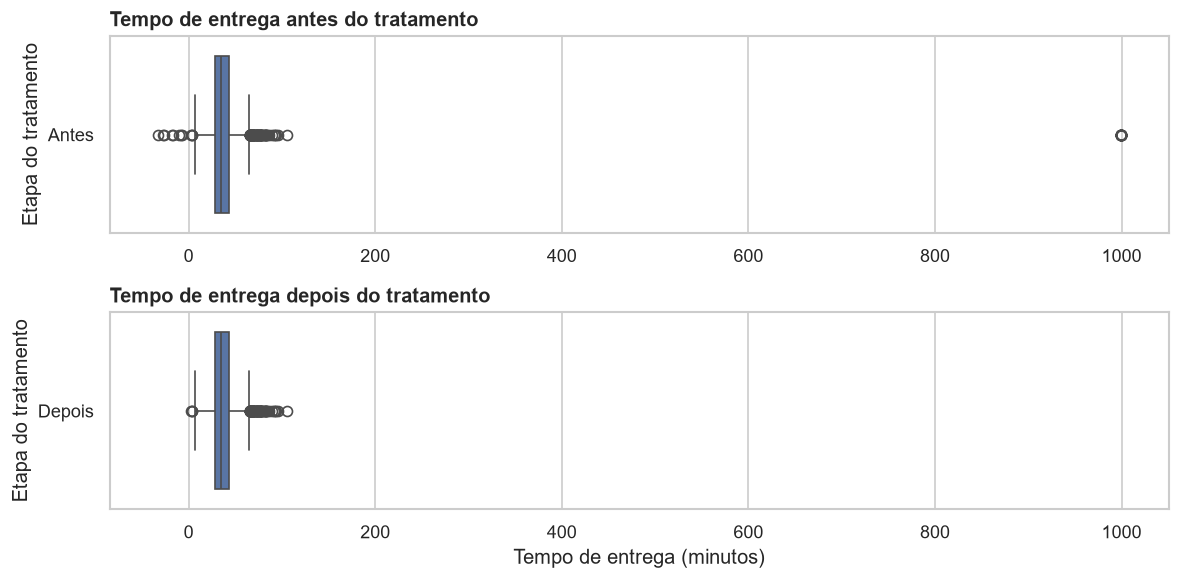

Tempos negativos: 8
Tempos iguais a 999 minutos: 25
Pedidos marcados como tempo inválido: 33
Pedidos com tempo válido: 8025
Total de pedidos: 8058


In [118]:
# Sua solução aqui
tempo_original = bruto["tempo_entrega_min"]

# Marca os tempos inválidos e substitui apenas esses valores por NaN.
df["tempo_invalido"] = (tempo_original < 0) | (tempo_original == 999)
df["tempo_entrega_min"] = tempo_original.mask(df["tempo_invalido"])

# Usa a mesma escala horizontal nos dois gráficos.
fig, eixos = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

sns.boxplot(x=tempo_original, ax=eixos[0])
eixos[0].set_title("Tempo de entrega antes do tratamento")
eixos[0].set_xlabel("Tempo de entrega (minutos)")
eixos[0].set_ylabel("Etapa do tratamento")
eixos[0].set_yticks([0], labels=["Antes"])
eixos[0].tick_params(axis="x", labelbottom=True)

sns.boxplot(x=df["tempo_entrega_min"].dropna(), ax=eixos[1])
eixos[1].set_title("Tempo de entrega depois do tratamento")
eixos[1].set_xlabel("Tempo de entrega (minutos)")
eixos[1].set_ylabel("Etapa do tratamento")
eixos[1].set_yticks([0], labels=["Depois"])

plt.tight_layout()
plt.show()

print("Tempos negativos:", (tempo_original < 0).sum())
print("Tempos iguais a 999 minutos:", (tempo_original == 999).sum())
print("Pedidos marcados como tempo inválido:", df["tempo_invalido"].sum())
print("Pedidos com tempo válido:", df["tempo_entrega_min"].notna().sum())
print("Total de pedidos:", len(df))

*Sua resposta aqui*

Comparei os tempos de entrega antes e depois do tratamento usando
dois boxplots na mesma escala.

Encontrei 33 tempos inválidos, sendo 8 negativos e 25 iguais a
999 minutos. Substituí esses tempos por `NaN` e marquei os pedidos
afetados com `True` na coluna `tempo_invalido`.

Mantive os 8.058 pedidos na base. Depois do tratamento, 8.025
pedidos ficaram com tempo de entrega válido.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [119]:
# Sua solução aqui
distancia = bruto["distancia_km"]

# Z-score: distância em relação à média, em desvios padrão
media = distancia.mean()
desvio = distancia.std(ddof=0)
z_score = (distancia - media) / desvio
fora_z = z_score > 3

# IQR: amplitude da metade central das distâncias
q1 = distancia.quantile(0.25)
q3 = distancia.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

fora_iqr = (distancia < limite_inferior) | (distancia > limite_superior)

print(f"Corte do z-score: {media + 3 * desvio:.2f} km")
print("Pedidos sinalizados pelo z-score:", fora_z.sum())
print(f"Limites do IQR: {limite_inferior:.2f} a {limite_superior:.2f} km")
print("Pedidos sinalizados pelo IQR:", fora_iqr.sum())

print("\nDez maiores distâncias:")
display(
    bruto[["pedido_id", "distancia_km"]].nlargest(10, "distancia_km")
)

# Trata as distâncias acima do corte escolhido para esta base.
df["distancia_invalida"] = distancia > 100
df["distancia_km"] = distancia.mask(df["distancia_invalida"])

print("Distâncias marcadas como inválidas:", df["distancia_invalida"].sum())
print("Distâncias ausentes antes:", distancia.isna().sum())
print("Distâncias ausentes depois:", df["distancia_km"].isna().sum())
print("Total de pedidos:", len(df))

Corte do z-score: 32.02 km
Pedidos sinalizados pelo z-score: 7
Limites do IQR: -2.73 a 9.27 km
Pedidos sinalizados pelo IQR: 194

Dez maiores distâncias:


,pedido_id,distancia_km
3242,503242,399.65
706,500706,391.89
3926,503926,369.22
1539,501539,300.21
5826,505826,252.99
5749,505749,163.23
7133,507133,160.26
5200,505200,24.39
6687,506687,18.58
8003,508003,18.30


Distâncias marcadas como inválidas: 7
Distâncias ausentes antes: 315
Distâncias ausentes depois: 322
Total de pedidos: 8058


*Sua resposta aqui*

O z-score acima de 3 sinalizou 7 pedidos. O critério de 1,5 × IQR
sinalizou 194 pedidos, todos com distância acima de 9,27 km.

Ao ordenar as maiores distâncias, observei um salto de 24,39 km para
160,26 km. Dessa forma, distâncias de mais de 100 km são incompatíveis com entregas com o cenário de entregas urbanas. Mantive as distâncias longas até
24,39 km e marquei os 7 casos acima de 100 km em `distancia_invalida`.

Troquei essas 7 distâncias por `NaN`. A coluna passou de 315 para
322 valores ausentes, e os 8.058 pedidos foram mantidos na base.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [120]:
# Sua solução aqui
valor = df["valor_pedido"]
cozinha = df["tipo_cozinha"]

# 1. IQR da base inteira: os mesmos limites para todos os pedidos
q1 = valor.quantile(0.25)
q3 = valor.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
fora_iqr_geral = (valor < limite_inferior) | (valor > limite_superior)

# 2. IQR por cozinha: cada pedido usa os limites da sua categoria
valores_por_cozinha = valor.groupby(cozinha)
q1_cozinha = valores_por_cozinha.transform("quantile", 0.25)
q3_cozinha = valores_por_cozinha.transform("quantile", 0.75)
iqr_cozinha = q3_cozinha - q1_cozinha

fora_iqr_cozinha = (
    (valor < q1_cozinha - 1.5 * iqr_cozinha)
    | (valor > q3_cozinha + 1.5 * iqr_cozinha)
)

# 3. Z-score da base inteira: mais de 3 desvios padrão acima da média
z_score = (valor - valor.mean()) / valor.std(ddof=0)
fora_z_score = z_score > 3

sinalizados = pd.DataFrame({
    "IQR geral": fora_iqr_geral,
    "IQR por cozinha": fora_iqr_cozinha,
    "Z-score > 3 (geral)": fora_z_score
})

resumo = sinalizados.groupby(cozinha).sum()
resumo.loc["Total"] = resumo.sum()

print(f"Limite superior do IQR geral: R$ {limite_superior:.2f}")
display(resumo)

Limite superior do IQR geral: R$ 144.97


,IQR geral,IQR por cozinha,Z-score > 3 (geral)
tipo_cozinha,,,
Brasileira,6,38,5
Doces,3,18,2
Hambúrguer,19,43,4
Japonesa,246,24,12
Pizza,70,60,4
Saudável,8,31,4
Total,352,214,31


*Sua resposta aqui*

#### O que mudou entre os critérios?

Primeiro, apliquei o IQR na base inteira. O limite superior foi de
R$ 144,97 para todas as cozinhas. Com essa regra, foram sinalizados
352 pedidos, sendo 246 da cozinha japonesa.

Depois, calculei o IQR separadamente para cada cozinha. Assim, cada
pedido foi comparado com os da sua própria categoria. Na cozinha
japonesa, a contagem caiu de 246 para 24. Na brasileira, subiu de 6
para 38. Isso mostra que um valor alto para o aplicativo como um
todo pode ser comum dentro de uma cozinha, e o contrário também
pode acontecer.

Por exemplo, um pedido japonês de R$ 150 seria sinalizado pelo IQR
geral, pois passa de R$ 144,97. No IQR por cozinha, o resultado
depende do limite calculado só para os pedidos japoneses.

Por fim, o z-score calculado na base inteira sinalizou 31 pedidos,
sendo 12 da cozinha japonesa. Essa regra marca valores que ficam
mais de três desvios padrão acima da média geral.

Um mesmo pedido pode ser sinalizado por mais de um critério.
Usei essas regras para identificar valores que merecem investigação
antes de decidir se precisam de correção.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [121]:
# Sua solução aqui
mediana_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
razao_valor = df["valor_pedido"] / mediana_cozinha

maiores_razoes = pd.DataFrame({
    "tipo_cozinha": df["tipo_cozinha"],
    "valor_pedido": df["valor_pedido"],
    "mediana_cozinha": mediana_cozinha,
    "razao_valor": razao_valor
}).sort_values("razao_valor", ascending=False)

display(maiores_razoes.head(30).round(2))

,tipo_cozinha,valor_pedido,mediana_cozinha,razao_valor
6904,Pizza,2299.10,74.31,30.94
3553,Japonesa,2207.79,107.97,20.45
4023,Pizza,1441.97,74.31,19.41
6787,Hambúrguer,1071.77,61.67,17.38
491,Pizza,1035.26,74.31,13.93
3246,Doces,505.64,38.42,13.16
1035,Japonesa,1394.73,107.97,12.92
1263,Brasileira,614.31,47.82,12.85
1736,Hambúrguer,700.91,61.67,11.37
4045,Hambúrguer,625.71,61.67,10.15


In [122]:
df["pedido_grande"] = razao_valor > 4

colunas = [
    "pedido_id", "cidade", "data_hora", "tipo_cozinha", "valor_pedido",
    "distancia_km", "taxa_entrega", "tempo_entrega_min"
]

pedidos_grandes = (
    df.loc[df["pedido_grande"], colunas]
    .assign(razao_valor=razao_valor[df["pedido_grande"]])
    .sort_values("razao_valor", ascending=False)
)

display(pedidos_grandes.round({
    "valor_pedido": 2,
    "distancia_km": 2,
    "taxa_entrega": 2,
    "razao_valor": 2
}))
print("Pedidos marcados como grandes:", df["pedido_grande"].sum())
print("Total de pedidos na base:", len(df))

,pedido_id,cidade,data_hora,tipo_cozinha,valor_pedido,distancia_km,taxa_entrega,tempo_entrega_min,razao_valor
6904,506904,Rio de Janeiro,2024-11-17 11:07:00,Pizza,2299.10,2.03,6.82,25.0,30.94
3553,503553,São Paulo,2024-06-24 19:48:00,Japonesa,2207.79,0.89,5.79,18.0,20.45
4023,504023,São Paulo,2024-07-14 12:46:00,Pizza,1441.97,0.76,0.00,27.0,19.41
6787,506787,Rio de Janeiro,2024-11-12 17:33:00,Hambúrguer,1071.77,2.60,7.33,24.0,17.38
491,500491,São Paulo,2024-01-24 20:59:00,Pizza,1035.26,2.13,6.91,34.0,13.93
3246,503246,São Paulo,2024-06-09 20:38:00,Doces,505.64,1.30,0.00,29.0,13.16
1035,501035,São Paulo,2024-02-23 19:48:00,Japonesa,1394.73,2.35,7.10,39.0,12.92
1263,501263,São Paulo,2024-03-04 12:43:00,Brasileira,614.31,4.75,9.27,51.0,12.85
1736,501736,Rio de Janeiro,2024-03-27 14:45:00,Hambúrguer,700.91,11.92,15.72,59.0,11.37
4045,504045,São Paulo,2024-07-15 12:21:00,Hambúrguer,625.71,1.04,5.93,24.0,10.15


Pedidos marcados como grandes: 26
Total de pedidos na base: 8058


*Sua resposta aqui*

Dividi o valor de cada pedido pela mediana do seu tipo de cozinha.
Ao ordenar as razões, observei uma queda de 4,28 para 3,35 entre
o 26º e o 27º pedido. Usei 4 vezes a mediana como corte e marquei
26 pedidos com `True` na coluna `pedido_grande`.

Os pedidos marcados aparecem em cidades, datas e cozinhas diferentes.
Por exemplo, um pedido de pizza de R$ 2.299,10 teve distância de
2,03 km, taxa de R$ 6,82 e tempo de entrega de 25 minutos.

Como vários registros têm informações de entrega plausíveis,
mantive os valores e sinalizei os pedidos como grandes. A base
não tem informação suficiente para confirmar se eram corporativos.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [123]:
# Sua solução aqui
sem_grandes = df.loc[~df["pedido_grande"]]

# Comparação na base toda
resumo_geral = pd.DataFrame({
    "Com pedidos grandes": df["valor_pedido"].agg(["mean", "median"]),
    "Sem pedidos grandes": sem_grandes["valor_pedido"].agg(["mean", "median"])
}).rename(index={"mean": "Média", "median": "Mediana"})

print("Ticket na base toda (R$)")
display(resumo_geral.round(2))

# Comparação por tipo de cozinha
com_por_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].agg(
    media_com="mean",
    mediana_com="median"
)

sem_por_cozinha = sem_grandes.groupby("tipo_cozinha")["valor_pedido"].agg(
    media_sem="mean",
    mediana_sem="median"
)

print("Ticket por tipo de cozinha (R$)")
display(com_por_cozinha.join(sem_por_cozinha).round(2))

Ticket na base toda (R$)


,Com pedidos grandes,Sem pedidos grandes
Média,71.55,69.37
Mediana,61.61,61.48


Ticket por tipo de cozinha (R$)


,media_com,mediana_com,media_sem,mediana_sem
tipo_cozinha,,,,
Brasileira,51.17,47.82,49.94,47.75
Doces,41.79,38.42,40.64,38.40
Hambúrguer,67.65,61.67,66.25,61.61
Japonesa,120.37,107.97,115.38,107.73
Pizza,82.79,74.31,79.91,74.28
Saudável,58.77,53.74,57.22,53.46


*Sua resposta aqui*

Comparei o ticket com todos os pedidos e depois filtrei os 26 pedidos
marcados como grandes para medir o impacto deles. Na base toda, a
média caiu de R$ 71,55 para R$ 69,37. A mediana mudou de R$ 61,61
para R$ 61,48.

Na cozinha japonesa, a média caiu de R$ 120,37 para R$ 115,38,
enquanto a mediana mudou de R$ 107,97 para R$ 107,73.

Vou usar a mediana para representar o ticket típico, pois ela variou
menos com a presença dos pedidos grandes. Mantive esses pedidos na
base e usei o filtro apenas para esta comparação.

In [124]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


O checkpoint de outliers passou. Marquei 33 tempos de entrega e
7 distâncias como inválidos e substituí esses valores por `NaN`.
Mantive os 26 pedidos grandes na base e usei `pedido_grande` para
identificá-los. A base continua com 8.058 pedidos.

Vou usar a mediana como ticket típico, pois ela mudou menos que
a média quando comparei os resultados com e sem os pedidos grandes.

---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [125]:
# Sua solução aqui
colunas = [
    "valor_pedido",
    "taxa_entrega",
    "distancia_km",
    "tempo_entrega_min",
    "avaliacao"
]

dados = df[colunas]
resumo = dados.describe().T

resumo["IQR"] = resumo["75%"] - resumo["25%"]
resumo["CV (%)"] = 100 * resumo["std"] / resumo["mean"]
resumo["Assimetria"] = dados.skew()

# Se houver empate, mostra todos os valores mais frequentes.
resumo["Moda"] = [
    ", ".join(f"{valor:g}" for valor in dados[coluna].mode())
    for coluna in colunas
]

resumo = resumo.rename(columns={
    "count": "Preenchidos",
    "mean": "Média",
    "std": "Desvio padrão",
    "min": "Mínimo",
    "50%": "Mediana",
    "max": "Máximo"
})

resumo["Preenchidos"] = resumo["Preenchidos"].astype(int)
display(resumo.round(2))

,Preenchidos,Média,Desvio padrão,Mínimo,25%,Mediana,75%,Máximo,IQR,CV (%),Assimetria,Moda
valor_pedido,8058,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,"48.52, 104.62"
taxa_entrega,8058,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0
distancia_km,7736,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.7
tempo_entrega_min,8025,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34
avaliacao,6716,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5


Resumi as cinco variáveis numéricas usando a base tratada. A tabela
mostra quantos valores estavam preenchidos, onde os valores se
concentram e quanto eles variam.

Usei o IQR para medir a largura da faixa central dos valores e o
coeficiente de variação para comparar a dispersão em relação à média.
A assimetria ajuda a ver se há uma cauda de valores altos ou baixos,
e a moda mostra quais valores aparecem com maior frequência.

No valor do pedido, a média ficou em R$ 71,55 e a mediana em R$ 61,61.
Vou usar a mediana como referência de ticket típico, pois na Tarefa 4.5
ela variou menos com a presença dos pedidos grandes.

### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

*Sua resposta aqui*

**(a) Variável mais assimétrica.** O `valor_pedido` teve a maior
assimetria em valor absoluto (17,52). A assimetria positiva indica
uma cauda à direita, formada pelos pedidos de valor muito alto.
Esses pedidos puxam a média para R$ 71,55, acima da mediana de
R$ 61,61. Por isso, vou usar a mediana como ticket típico.

**(b) Maior variabilidade relativa.** O `valor_pedido` também teve
o maior coeficiente de variação (84,22%). Isso significa que o
desvio padrão equivale a cerca de 84% da média. Entre as cinco
variáveis, o valor do pedido foi o que mais variou em relação
à própria média.

**(c) Moda da taxa de entrega.** A moda foi R$ 0,00, registrada
em 900 pedidos. Isso mostra que a taxa zero foi o valor mais
frequente. Como a mediana foi R$ 7,42, a taxa zero foi a mais
comum entre os valores individuais, mas esteve longe de ser
a taxa da maioria dos pedidos.

**(d) Avaliação média.** A média foi de 4,35 em uma escala de
1 a 5, então é alta. Esse resultado considera os 6.716 pedidos
com nota. Os 1.342 pedidos sem avaliação ficaram fora do cálculo.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [126]:
# Sua solução aqui
colunas_categoricas = ["cidade", "tipo_cozinha", "forma_pagamento", "plataforma"]

for coluna in colunas_categoricas:
    contagem = df[coluna].value_counts(dropna=False)
    percentual = 100 * contagem / contagem.sum()
    modas = contagem[contagem == contagem.max()].index.tolist()

    tabela = pd.DataFrame({
        "Quantidade de pedidos": contagem,
        "Percentual (%)": percentual.round(2)
    }).rename_axis(coluna)

    print(f"\n{coluna}")
    print("Moda:", ", ".join(map(str, modas)))
    display(tabela)


cidade
Moda: São Paulo


,Quantidade de pedidos,Percentual (%)
cidade,,
São Paulo,4055,50.32
Rio de Janeiro,2371,29.42
Belo Horizonte,1632,20.25



tipo_cozinha
Moda: Hambúrguer


,Quantidade de pedidos,Percentual (%)
tipo_cozinha,,
Hambúrguer,1921,23.84
Pizza,1786,22.16
Brasileira,1561,19.37
Japonesa,1116,13.85
Saudável,860,10.67
Doces,814,10.10



forma_pagamento
Moda: Cartão de crédito


,Quantidade de pedidos,Percentual (%)
forma_pagamento,,
Cartão de crédito,3642,45.20
Pix,2633,32.68
Vale-refeição,1222,15.17
Dinheiro,561,6.96



plataforma
Moda: Android


,Quantidade de pedidos,Percentual (%)
plataforma,,
Android,4449,55.21
iOS,2574,31.94
Web,882,10.95
Não informada,153,1.90


*Sua resposta aqui*

Calculei a distribuição percentual de cidade, tipo de cozinha,
forma de pagamento e plataforma. Em cada tabela, a moda é a
categoria com a maior quantidade de pedidos.

- **Cidade:** [moda], com [percentual]% dos pedidos.
- **Tipo de cozinha:** [moda], com [percentual]% dos pedidos.
- **Forma de pagamento:** [moda], com [percentual]% dos pedidos.
- **Plataforma:** [moda], com [percentual]% dos pedidos.

Na distribuição por plataforma, 153 pedidos (1,90%) ficaram
na categoria `Não informada`, pois o registro original não
indicava por onde o pedido foi feito.

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [127]:
# Sua solução aqui
tempos = df["tempo_entrega_min"].dropna()

percentis = tempos.quantile([0.50, 0.75, 0.90, 0.95])
percentis.index = ["P50", "P75", "P90", "P95"]

display(percentis.to_frame("Tempo de entrega (min)"))

limites = [35, 45]
quantidades = [(tempos > limite).sum() for limite in limites]

resumo_prazos = pd.DataFrame({
    "Acima de (min)": limites,
    "Quantidade de pedidos": quantidades,
    "Percentual (%)": [round(100 * n / len(tempos), 2) for n in quantidades]
})

print("Pedidos com tempo válido:", len(tempos))
display(resumo_prazos)

,Tempo de entrega (min)
P50,35.0
P75,43.0
P90,50.0
P95,55.0


Pedidos com tempo válido: 8025


,Acima de (min),Quantidade de pedidos,Percentual (%)
0,35,3908,48.70
1,45,1476,18.39


*Sua resposta aqui*

O tempo mediano de entrega foi de 35 minutos. Os percentis 75, 90
e 95 foram de 43, 50 e 55 minutos, respectivamente. Isso significa,
por exemplo, que cerca de 90% dos pedidos com tempo válido chegaram
em até 50 minutos.

Dos 8.025 pedidos com tempo válido, 3.908 (48,70%) passaram de
35 minutos. Se o prazo prometido fosse de até 45 minutos, 1.476
pedidos (18,39%) teriam ultrapassado esse prazo em 2024.

Os 33 pedidos com tempo inválido ficaram fora dessa comparação.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [128]:
# Sua solução aqui
# Selecionar os pedidos de 2024
pedidos_2024 = df.loc[df["data_hora"].dt.year == 2024]

# Considerar apenas os tempos válidos nos indicadores de entrega
tempos_validos = pedidos_2024["tempo_entrega_min"].dropna()

kpis = pd.Series({
    "Número de pedidos": len(pedidos_2024),
    "Faturamento em itens (R$)": pedidos_2024["valor_pedido"].sum(),
    "Receita de taxa de entrega (R$)": pedidos_2024["taxa_entrega"].sum(),
    "Ticket médio (R$)": pedidos_2024["valor_pedido"].mean(),
    "Ticket mediano (R$)": pedidos_2024["valor_pedido"].median(),
    "Pedidos com cupom (%)": pedidos_2024["cupom"].mean() * 100,
    "Clientes novos (%)": pedidos_2024["cliente_novo"].mean() * 100,
    "Pedidos com frete grátis (%)": (
        pedidos_2024["taxa_entrega"].eq(0).mean() * 100
    ),
    "Tempo médio de entrega (min)": tempos_validos.mean(),
    "Entregas acima de 45 min (%)": tempos_validos.gt(45).mean() * 100,
    "Avaliação média": pedidos_2024["avaliacao"].mean(),
    "Pedidos avaliados (%)": (
        pedidos_2024["avaliacao"].notna().mean() * 100
    )
}, name="KPIs de 2024")

display(kpis.round(2))

Número de pedidos                    8058.00
Faturamento em itens (R$)          576584.75
Receita de taxa de entrega (R$)     58571.40
Ticket médio (R$)                      71.55
Ticket mediano (R$)                    61.61
Pedidos com cupom (%)                  21.21
Clientes novos (%)                     17.37
Pedidos com frete grátis (%)           11.17
Tempo médio de entrega (min)           35.91
Entregas acima de 45 min (%)           18.39
Avaliação média                         4.35
Pedidos avaliados (%)                  83.35
Name: KPIs de 2024, dtype: float64

O painel reúne os principais indicadores dos pedidos de 2024.

O faturamento em itens corresponde à soma de `valor_pedido`.
As taxas de entrega foram somadas separadamente. O ticket médio
representa a média do valor dos pedidos, enquanto o ticket mediano
representa o valor central e sofre menos influência dos pedidos grandes.

Em 2024, foram registrados 8.058 pedidos, com faturamento em itens
de R$ 576.584,75 e receita de taxas de entrega de R$ 58.571,40.

O ticket médio foi de R$ 71,55 e o ticket mediano foi de R$ 61,61.
A média ficou acima da mediana porque os pedidos de maior valor
puxam a média para cima.

Dos pedidos do ano, 21,21% usaram cupom, 17,37% foram marcados
como de clientes novos e 11,17% tiveram frete grátis.

Os indicadores de tempo consideram apenas os pedidos com tempo de
entrega válido. A avaliação média considera somente as notas preenchidas,
e o percentual de pedidos avaliados mostra quantos pedidos receberam nota.

O tempo médio de entrega foi de 35,91 minutos. Entre os pedidos
com tempo válido, 18,39% ultrapassaram 45 minutos. Os 33 tempos
inválidos ficaram fora desses dois cálculos.

A avaliação média foi de 4,35 em uma escala de 1 a 5.
Ao todo, 83,35% dos pedidos receberam avaliação.

O percentual de clientes novos foi calculado pela coluna `cliente_novo`,
considerando a participação desses pedidos no total de pedidos do ano.

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [129]:
# Sua solução aqui
# Indicadores calculados por pedido, agrupados por cidade
resumo_cidades = pedidos_2024.groupby("cidade").agg(
    pedidos=("pedido_id", "size"),
    faturamento=("valor_pedido", "sum"),
    ticket_mediano=("valor_pedido", "median"),
    tempo_medio_entrega=("tempo_entrega_min", "mean"),
    avaliacao_media=("avaliacao", "mean"),
    percentual_cupom=("cupom", lambda valores: valores.mean() * 100)
)

# Participação de cada cidade no total de pedidos
resumo_cidades["participacao_pct"] = (
    resumo_cidades["pedidos"] / len(pedidos_2024) * 100
)

# Identificar os dias com chuva em cada cidade
chuva_por_dia = pedidos_2024.groupby(["cidade", "data"]).agg(
    dia_com_chuva=("chuva", "any")
)

# Calcular o percentual entre os dias com pedidos registrados
percentual_dias_chuva = chuva_por_dia.groupby("cidade").agg(
    percentual_dias_chuva=("dia_com_chuva", lambda dias: dias.mean() * 100)
)

resumo_cidades = resumo_cidades.join(percentual_dias_chuva)

# Organizar as colunas e ordenar pela quantidade de pedidos
resumo_cidades = resumo_cidades[[
    "pedidos",
    "participacao_pct",
    "faturamento",
    "ticket_mediano",
    "tempo_medio_entrega",
    "avaliacao_media",
    "percentual_cupom",
    "percentual_dias_chuva"
]].sort_values("pedidos", ascending=False)

display(resumo_cidades.round(2))

,pedidos,participacao_pct,faturamento,ticket_mediano,tempo_medio_entrega,avaliacao_media,percentual_cupom,percentual_dias_chuva
cidade,,,,,,,,
São Paulo,4055,50.32,289275.55,61.54,35.86,4.35,21.60,25.21
Rio de Janeiro,2371,29.42,172029.24,61.43,35.71,4.36,20.75,24.45
Belo Horizonte,1632,20.25,115279.96,62.04,36.34,4.34,20.89,26.39


*Sua resposta aqui*

A tabela compara as cidades pela quantidade de pedidos, participação
no total, faturamento, ticket mediano, tempo médio de entrega,
avaliação média e uso de cupons.

A participação foi calculada dividindo os pedidos de cada cidade
pelo total de pedidos de 2024.

Para calcular o percentual de dias com chuva, os pedidos foram agrupados
por cidade e dia. Foi considerado chuvoso o dia com pelo menos um
pedido marcado com chuva. O percentual considera os dias com pedidos
registrados em cada cidade.

As médias de tempo e avaliação consideram apenas os valores preenchidos.
A tabela foi ordenada da cidade com mais pedidos para a cidade com menos.

São Paulo concentrou o maior volume, com 4.055 pedidos,
representando 50,32% do total. Também apresentou o maior
faturamento, de R$ 289.275,55.

O Rio de Janeiro teve 2.371 pedidos, participação de 29,42%
e faturamento de R$ 172.029,24. Belo Horizonte teve 1.632 pedidos,
participação de 20,25% e faturamento de R$ 115.279,96.

O ticket mediano foi parecido nas três cidades. Belo Horizonte
apresentou R$ 62,04, São Paulo R$ 61,54 e Rio de Janeiro R$ 61,43.

O tempo médio de entrega também foi próximo entre as cidades.
Belo Horizonte teve a maior média, com 36,34 minutos, seguida
de São Paulo, com 35,86, e Rio de Janeiro, com 35,71 minutos.
As avaliações médias ficaram entre 4,34 e 4,36.

O uso de cupons ficou próximo de 21% nas três cidades.

O percentual de dias com chuva foi de 26,39% em Belo Horizonte,
25,21% em São Paulo e 24,45% no Rio de Janeiro. Para esse cálculo,
cada dia foi contado uma vez por cidade e considerado chuvoso
quando apresentou pelo menos um pedido marcado com chuva.
Foram considerados os dias com pedidos registrados.

A principal diferença entre as cidades foi o volume de pedidos,
com maior concentração em São Paulo.

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [130]:
# Sua solução aqui
resumo_cozinhas = pedidos_2024.groupby("tipo_cozinha").agg(
    pedidos=("pedido_id", "size"),
    ticket_medio=("valor_pedido", "mean"),
    ticket_mediano=("valor_pedido", "median"),
    faturamento=("valor_pedido", "sum")
)

resumo_cozinhas["participacao_faturamento_pct"] = (
    resumo_cozinhas["faturamento"]
    / resumo_cozinhas["faturamento"].sum()
    * 100
)

# Mostrar a tabela ordenada pelo volume de pedidos
resumo_cozinhas = resumo_cozinhas.sort_values(
    "pedidos", ascending=False
)

display(resumo_cozinhas.round(2))

# Usar a mediana para comparar o ticket típico
print("Maior ticket mediano:", resumo_cozinhas["ticket_mediano"].idxmax())
print("Menor ticket mediano:", resumo_cozinhas["ticket_mediano"].idxmin())

# Mostrar também os extremos pela média
print("\nMaior ticket médio:", resumo_cozinhas["ticket_medio"].idxmax())
print("Menor ticket médio:", resumo_cozinhas["ticket_medio"].idxmin())

# Comparar as duas classificações
ordem_volume = resumo_cozinhas.index.tolist()

ordem_faturamento = (
    resumo_cozinhas.sort_values("faturamento", ascending=False)
    .index.tolist()
)

print("\nOrdem por volume:", " → ".join(ordem_volume))
print("Ordem por faturamento:", " → ".join(ordem_faturamento))
print("As ordens são iguais?", ordem_volume == ordem_faturamento)

,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento_pct
tipo_cozinha,,,,,
Hambúrguer,1921,67.65,61.67,129963.40,22.54
Pizza,1786,82.79,74.31,147857.26,25.64
Brasileira,1561,51.17,47.82,79871.60,13.85
Japonesa,1116,120.37,107.97,134328.26,23.30
Saudável,860,58.77,53.74,50544.31,8.77
Doces,814,41.79,38.42,34019.92,5.90


Maior ticket mediano: Japonesa
Menor ticket mediano: Doces

Maior ticket médio: Japonesa
Menor ticket médio: Doces

Ordem por volume: Hambúrguer → Pizza → Brasileira → Japonesa → Saudável → Doces
Ordem por faturamento: Pizza → Japonesa → Hambúrguer → Brasileira → Saudável → Doces
As ordens são iguais? False


*Sua resposta aqui*

A tabela compara a quantidade de pedidos e os valores vendidos por
tipo de cozinha. A participação no faturamento mostra quanto cada
cozinha representa no valor total dos itens vendidos em 2024.

O ticket médio considera todos os valores e pode ser elevado pelos
pedidos grandes. O ticket mediano representa o valor central e foi
usado para comparar o pedido típico de cada cozinha.

A comparação das classificações por volume e faturamento permite
verificar se as cozinhas com mais pedidos também são as que mais
faturam.

A cozinha Japonesa apresentou o maior ticket, tanto pela média
(R$ 120,37) quanto pela mediana (R$ 107,97). Doces apresentou
o menor ticket médio (R$ 41,79) e mediano (R$ 38,42).

A ordem por volume de pedidos foi:
Hambúrguer, Pizza, Brasileira, Japonesa, Saudável e Doces.

A ordem por faturamento foi:
Pizza, Japonesa, Hambúrguer, Brasileira, Saudável e Doces.

Portanto, as duas ordens foram diferentes. Hambúrguer teve
o maior volume, com 1.921 pedidos, mas Pizza teve o maior
faturamento, com R$ 147.857,26 e 25,64% do total.

A cozinha Japonesa ficou em quarto lugar em volume, com
1.116 pedidos, mas em segundo lugar em faturamento, com
R$ 134.328,26. Seu ticket mais alto explica essa diferença.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [131]:
# Sua solução aqui
# (a) Ticket mediano e avaliação média por plataforma
resumo_plataformas = pedidos_2024.groupby("plataforma").agg(
    ticket_mediano=("valor_pedido", "median"),
    avaliacao_media=("avaliacao", "mean")
)

print("Indicadores por plataforma")
display(resumo_plataformas.round(2))

# (b) Formas de pagamento em percentual por cidade
pagamento_por_cidade = pd.crosstab(
    pedidos_2024["cidade"],
    pedidos_2024["forma_pagamento"],
    normalize="index"
) * 100

print("\nFormas de pagamento por cidade (%)")
display(pagamento_por_cidade.round(2))

Indicadores por plataforma


,ticket_mediano,avaliacao_media
plataforma,,
Android,61.67,4.35
Não informada,62.44,4.39
Web,62.96,4.33
iOS,60.76,4.35



Formas de pagamento por cidade (%)


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26,6.86,32.60,14.28
Rio de Janeiro,45.47,6.87,33.11,14.55
São Paulo,44.61,7.05,32.45,15.88


*Sua resposta aqui*

O ticket mediano mostra o valor típico dos pedidos de cada plataforma.
A avaliação média considera somente os pedidos que receberam nota.
A categoria “Não informado”, reúne os pedidos cuja
plataforma estava ausente na base.

A tabela cruzada mostra a distribuição das formas de pagamento
dentro de cada cidade. Cada linha soma aproximadamente 100%,
permitindo comparar as preferências mesmo quando as cidades têm
quantidades diferentes de pedidos.

Entre as plataformas identificadas, a Web apresentou o maior
ticket mediano, de R$ 62,96, seguida de Android, com R$ 61,67,
e iOS, com R$ 60,76.

As avaliações médias foram próximas. Android e iOS tiveram
média de 4,35, enquanto a Web teve 4,33.

Os pedidos com plataforma “Não informada” apresentaram ticket
mediano de R$ 62,44 e avaliação média de 4,39. 

As cidades apresentaram pequenas diferenças nas proporções
das formas de pagamento, mas o padrão geral foi semelhante.

O cartão de crédito foi o mais usado nas três cidades,
representando 46,26% dos pedidos de Belo Horizonte, 45,47%
do Rio de Janeiro e 44,61% de São Paulo.

O Pix ficou em segundo lugar, com participação entre 32,45%
e 33,11%. São Paulo apresentou maior participação de
vale-refeição, com 15,88%, contra 14,55% no Rio de Janeiro
e 14,28% em Belo Horizonte.

Dinheiro foi a forma menos utilizada nas três cidades,
com aproximadamente 7% dos pedidos.

Assim, existem diferenças nos percentuais, mas a ordem de
preferência foi a mesma nas três cidades.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

Pedidos por dia


,pedidos
data_hora,
2024-01-01,18
2024-01-02,23
2024-01-03,27
2024-01-04,13
2024-01-05,19
...,...
2024-12-27,33
2024-12-28,33
2024-12-29,24



Pedidos por semana


,inicio,fim,dias_na_base,pedidos,semana_completa
0,01/01/2024,07/01/2024,7,141,True
1,08/01/2024,14/01/2024,7,152,True
2,15/01/2024,21/01/2024,7,150,True
3,22/01/2024,28/01/2024,7,128,True
4,29/01/2024,04/02/2024,7,129,True
5,05/02/2024,11/02/2024,7,125,True
6,12/02/2024,18/02/2024,7,129,True
7,19/02/2024,25/02/2024,7,133,True
8,26/02/2024,03/03/2024,7,169,True
9,04/03/2024,10/03/2024,7,132,True



Pedidos por mês


,pedidos,dias_no_mes,media_pedidos_por_dia
mes,,,
Jan,618,31,19.94
Fev,559,29,19.28
Mar,647,31,20.87
Abr,580,30,19.33
Mai,660,31,21.29
Jun,630,30,21.00
Jul,822,31,26.52
Ago,662,31,21.35
Set,664,30,22.13



Cinco dias com menos pedidos


,pedidos
data_hora,
2024-08-14,1
2024-11-06,8
2024-03-20,10
2024-04-09,10
2024-06-24,10



Semanas incompletas


,inicio,fim,dias_na_base,pedidos,semana_completa
52,30/12/2024,31/12/2024,2,49,False


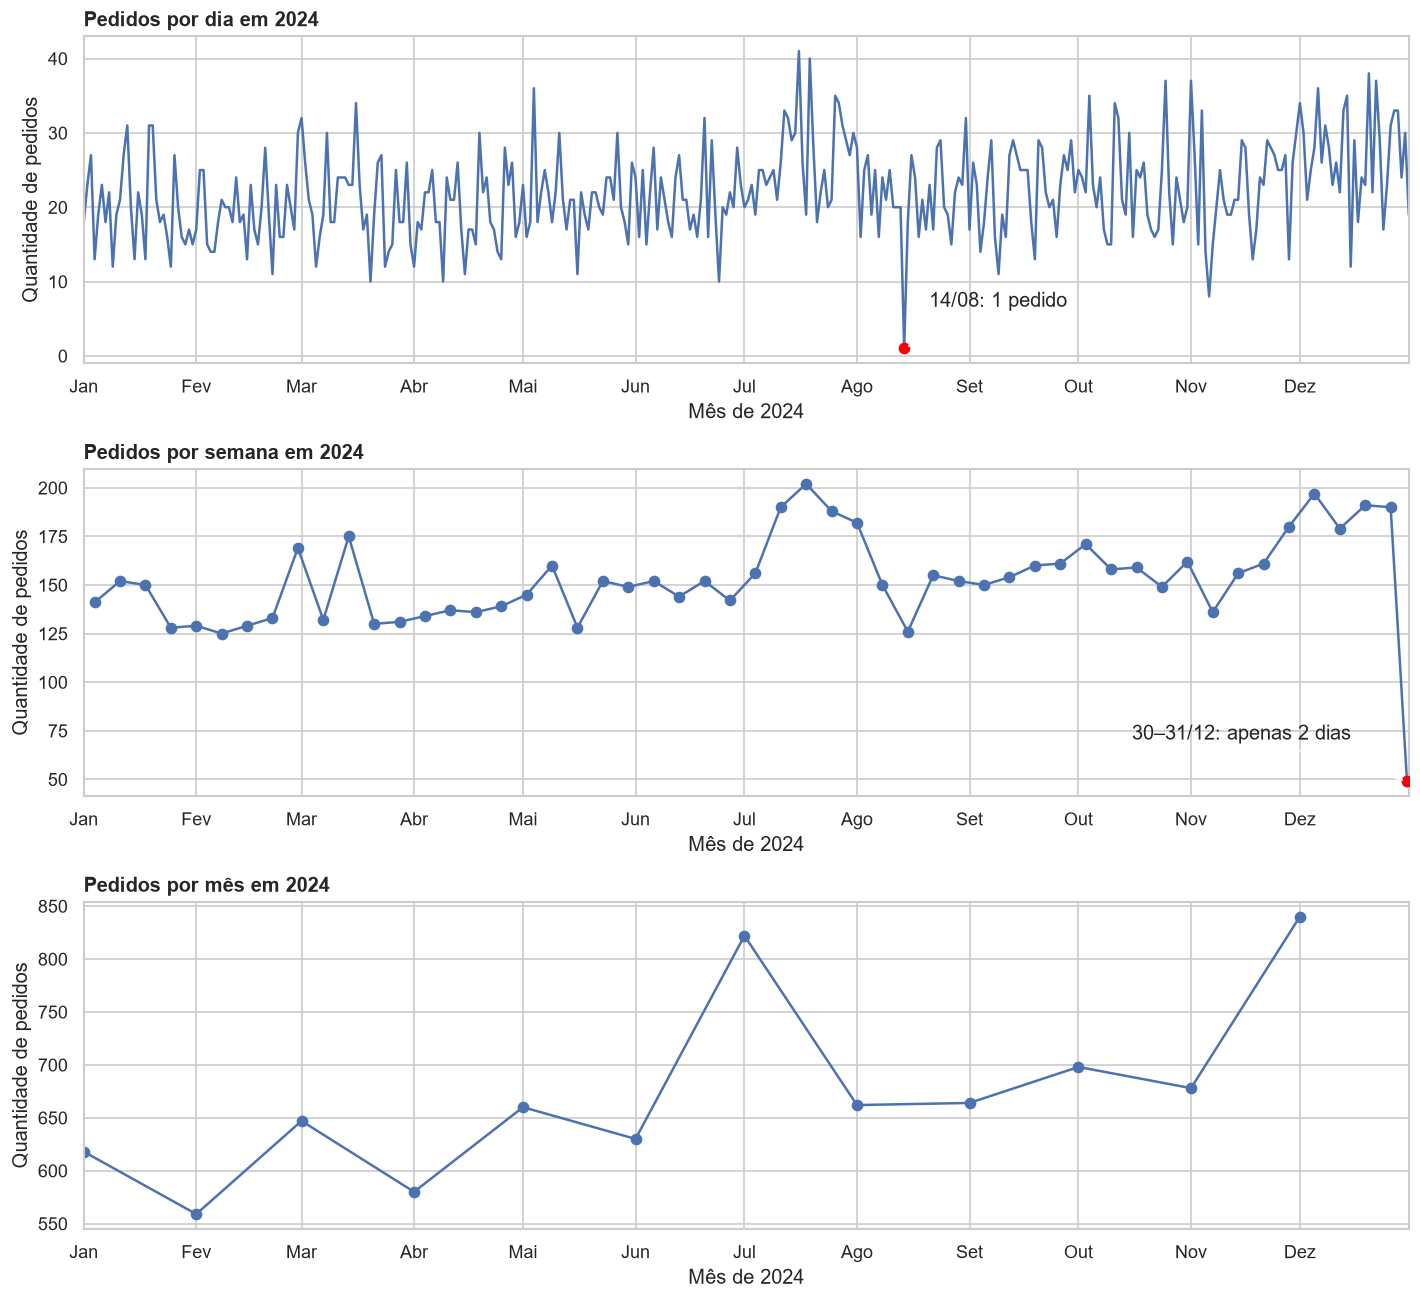

In [132]:
# Sua solução aqui
pedidos_tempo = pedidos_2024.set_index("data_hora").sort_index()

# Séries de pedidos
pedidos_dia = pedidos_tempo.resample("D").size().rename("pedidos")
pedidos_semana = pedidos_tempo.resample("W-SUN").size().rename("pedidos")
pedidos_mes = pedidos_tempo.resample("MS").size().rename("pedidos")

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

# Tabela diária
print("Pedidos por dia")
display(pedidos_dia.to_frame())

# Tabela semanal
inicio_base = pedidos_dia.index.min()
fim_base = pedidos_dia.index.max()

tabela_semanal = pedidos_semana.to_frame()

tabela_semanal["inicio"] = (
    tabela_semanal.index - pd.Timedelta(days=6)
)
tabela_semanal["fim"] = tabela_semanal.index

# Limitar os intervalos ao período coberto pela base
tabela_semanal["inicio"] = tabela_semanal["inicio"].clip(
    lower=inicio_base
)
tabela_semanal["fim"] = tabela_semanal["fim"].clip(
    upper=fim_base
)

tabela_semanal["dias_na_base"] = (
    tabela_semanal["fim"] - tabela_semanal["inicio"]
).dt.days + 1

tabela_semanal["semana_completa"] = (
    tabela_semanal["dias_na_base"] == 7
)

tabela_semanal = tabela_semanal[[
    "inicio", "fim", "dias_na_base", "pedidos", "semana_completa"
]].reset_index(drop=True)

# Formatar as datas apenas para exibição
tabela_semanal_exibicao = tabela_semanal.copy()

for coluna in ["inicio", "fim"]:
    tabela_semanal_exibicao[coluna] = (
        tabela_semanal_exibicao[coluna].dt.strftime("%d/%m/%Y")
    )

print("\nPedidos por semana")
display(tabela_semanal_exibicao)

# Tabela mensal
tabela_mensal = pedidos_mes.to_frame()
tabela_mensal["mes"] = [
    meses[data.month - 1] for data in tabela_mensal.index
]
tabela_mensal["dias_no_mes"] = tabela_mensal.index.days_in_month
tabela_mensal["media_pedidos_por_dia"] = (
    tabela_mensal["pedidos"] / tabela_mensal["dias_no_mes"]
)

tabela_mensal = tabela_mensal.set_index("mes")

print("\nPedidos por mês")
display(tabela_mensal.round(2))

print("\nCinco dias com menos pedidos")
display(pedidos_dia.nsmallest(5).to_frame())

print("\nSemanas incompletas")
display(
    tabela_semanal_exibicao.loc[
        ~tabela_semanal_exibicao["semana_completa"]
    ]
)

# Gráficos com os meses no eixo horizontal
marcas_meses = pd.date_range(
    start="2024-01-01", periods=12, freq="MS"
)

# Posicionar cada total semanal no meio do intervalo observado
datas_semanas = (
    tabela_semanal["inicio"]
    + (tabela_semanal["fim"] - tabela_semanal["inicio"]) / 2
)

fig, eixos = plt.subplots(3, 1, figsize=(12, 11))

eixos[0].plot(pedidos_dia.index, pedidos_dia.values)
eixos[0].set_title("Pedidos por dia em 2024")

eixos[1].plot(
    datas_semanas, tabela_semanal["pedidos"], marker="o"
)
eixos[1].set_title("Pedidos por semana em 2024")

eixos[2].plot(
    pedidos_mes.index, pedidos_mes.values, marker="o"
)
eixos[2].set_title("Pedidos por mês em 2024")

for eixo in eixos:
    eixo.set_xlabel("Mês de 2024")
    eixo.set_ylabel("Quantidade de pedidos")
    eixo.set_xticks(marcas_meses)
    eixo.set_xticklabels(meses)
    eixo.set_xlim(
        pd.Timestamp("2024-01-01"),
        pd.Timestamp("2024-12-31")
    )

# Destacar o dia anômalo
dia_anomalo = pedidos_dia.idxmin()

eixos[0].scatter(
    dia_anomalo, pedidos_dia.loc[dia_anomalo],
    color="red", zorder=3
)
eixos[0].annotate(
    "14/08: 1 pedido",
    xy=(dia_anomalo, pedidos_dia.loc[dia_anomalo]),
    xytext=(15, 25),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

# Destacar a semana incompleta
eixos[1].scatter(
    datas_semanas.iloc[-1],
    tabela_semanal["pedidos"].iloc[-1],
    color="red",
    zorder=3
)
eixos[1].annotate(
    "30–31/12: apenas 2 dias",
    xy=(
        datas_semanas.iloc[-1],
        tabela_semanal["pedidos"].iloc[-1]
    ),
    xytext=(-165, 25),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

plt.tight_layout()
plt.show()

*Sua resposta aqui*

Os pedidos de 2024 foram agrupados por dia, semana e mês usando
`resample`. As semanas foram definidas de segunda a domingo.
Também foram calculados os dias cobertos por semana e a média
diária de pedidos em cada mês. Nos três gráficos, o eixo horizontal
mostra os meses do ano.

**Visão diária**

Mostra as oscilações entre os dias e permite identificar picos
e quedas que ficam escondidos nos totais semanais e mensais.

O dia 14/08/2024 foi anômalo, com apenas 1 pedido, enquanto
a média diária foi de aproximadamente 22 pedidos. É necessário
investigar se houve queda real no movimento ou falha no registro.
O maior volume diário ocorreu em 16/07, com 41 pedidos.

**Visão semanal**

Mostra o movimento entre semanas, reduzindo as oscilações diárias.
Porém, pode esconder um dia com quantidade muito baixa ou alta
de pedidos dentro de uma semana.

A última semana contém somente os dias 30 e 31/12/2024,
com 49 pedidos. Como cobre apenas dois dias, seu total não deve
ser comparado diretamente com o das semanas completas.
A primeira semana, de 01 a 07/01, está completa.

**Visão mensal**

Mostra os períodos de maior e menor movimento ao longo do ano,
mas esconde as diferenças entre dias e semanas.

Dezembro apresentou o maior total, com 840 pedidos, seguido
de julho, com 822. Fevereiro teve o menor total, com 559 pedidos.
A média diária também foi incluída na tabela para considerar
que os meses têm quantidades diferentes de dias.

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [133]:
# Sua solução aqui
# (a) Quantidade de pedidos por hora e dia da semana
dias_semana = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

pedidos_hora_dia = pedidos_2024.pivot_table(
    index="hora",
    columns="dia_semana",
    values="pedido_id",
    aggfunc="count",
    fill_value=0,
    observed=True
)

# Mostrar todas as horas e ordenar os dias da semana
pedidos_hora_dia = pedidos_hora_dia.reindex(
    index=range(24),
    columns=dias_semana,
    fill_value=0
)

print("Quantidade de pedidos por hora e dia da semana")
display(pedidos_hora_dia)

# (b) Contar pedidos em cada dia do ano, incluindo dias sem pedidos
calendario_2024 = pd.date_range(
    "2024-01-01", "2024-12-31", freq="D"
)

pedidos_diarios = (
    pedidos_2024.set_index("data_hora")
    .resample("D")
    .size()
    .reindex(calendario_2024, fill_value=0)
)

resumo_dias_semana = (
    pedidos_diarios.groupby(pedidos_diarios.index.dayofweek)
    .agg(
        total_pedidos="sum",
        quantidade_dias="size",
        media_pedidos_por_dia="mean"
    )
)

resumo_dias_semana.index = dias_semana
resumo_dias_semana.index.name = "dia_semana"

print("\nMédia de pedidos por dia da semana")
display(resumo_dias_semana.round(2))

Quantidade de pedidos por hora e dia da semana


dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13



Média de pedidos por dia da semana


,total_pedidos,quantidade_dias,media_pedidos_por_dia
dia_semana,,,
Seg,1107,53,20.89
Ter,1064,53,20.08
Qua,1020,52,19.62
Qui,1049,52,20.17
Sex,1379,52,26.52
Sáb,1365,52,26.25
Dom,1074,52,20.65


*Sua resposta aqui*

Foi criada uma tabela dinâmica com `pivot_table`, colocando as
horas nas linhas e os dias da semana nas colunas. Cada célula
mostra a quantidade de pedidos daquela combinação durante 2024.
As combinações sem pedidos foram preenchidas com zero.

Os pedidos se concentraram nos horários de almoço e jantar.
Somando todos os dias da semana, o horário das 20h apresentou
o maior volume, com 1.241 pedidos, seguido das 12h, com 1.138,
e das 19h, com 1.066. A linha das 20h representa os pedidos
feitos entre 20h e 20h59.

Na combinação entre hora e dia da semana, o maior total ocorreu
às sextas-feiras, entre 20h e 20h59, com 212 pedidos no ano.
Esses horários merecem atenção no planejamento da equipe por
concentrarem maior demanda.

Depois, foi calculada a média de pedidos por dia da semana.
Sexta-feira apresentou a maior média, com 26,52 pedidos por dia,
seguida de sábado, com 26,25. Quarta-feira apresentou a menor
média, com 19,62.

A média é mais justa do que comparar apenas os totais porque
2024 teve 53 segundas e 53 terças, enquanto os outros dias
ocorreram 52 vezes. Dividir os pedidos pela quantidade de dias
permite comparar o movimento de um dia típico de cada grupo.

A tabela por hora mostra o volume acumulado no ano. Para comparar
a intensidade dos horários entre diferentes dias da semana,
também é necessário considerar essa diferença no calendário.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [134]:
# Sua solução aqui
# (a) Comparar pedidos com e sem cupom
resumo_cupom = pedidos_2024.groupby("cupom").agg(
    pedidos=("pedido_id", "size"),
    ticket_mediano=("valor_pedido", "median"),
    clientes_novos_pct=(
        "cliente_novo", lambda valores: valores.mean() * 100
    ),
    frete_gratis_pct=(
        "taxa_entrega", lambda valores: valores.eq(0).mean() * 100
    ),
    avaliacao_media=("avaliacao", "mean")
)

resumo_cupom.index = resumo_cupom.index.map({
    False: "Sem cupom",
    True: "Com cupom"
})

print("Comparação dos pedidos com e sem cupom")
display(resumo_cupom.round(2))

# (b) Uso de cupom e média diária de pedidos por mês
cupom_mensal = (
    pedidos_2024.set_index("data_hora")
    .resample("MS")
    .agg(
        pedidos=("pedido_id", "size"),
        taxa_uso_cupom_pct=(
            "cupom", lambda valores: valores.mean() * 100
        )
    )
)

cupom_mensal["dias_no_mes"] = cupom_mensal.index.days_in_month
cupom_mensal["media_pedidos_por_dia"] = (
    cupom_mensal["pedidos"] / cupom_mensal["dias_no_mes"]
)

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

cupom_mensal.index = [
    meses[data.month - 1] for data in cupom_mensal.index
]
cupom_mensal.index.name = "mes"

print("\nUso de cupom e média diária por mês")
display(cupom_mensal.round(2))

Comparação dos pedidos com e sem cupom


,pedidos,ticket_mediano,clientes_novos_pct,frete_gratis_pct,avaliacao_media
cupom,,,,,
Sem cupom,6349,62.82,12.81,0.00,4.36
Com cupom,1709,57.22,34.35,52.66,4.31



Uso de cupom e média diária por mês


,pedidos,taxa_uso_cupom_pct,dias_no_mes,media_pedidos_por_dia
mes,,,,
Jan,618,16.18,31,19.94
Fev,559,23.61,29,19.28
Mar,647,19.94,31,20.87
Abr,580,16.55,30,19.33
Mai,660,18.64,31,21.29
Jun,630,19.52,30,21.00
Jul,822,45.62,31,26.52
Ago,662,21.15,31,21.35
Set,664,18.83,30,22.13


*Sua resposta aqui*

Os pedidos foram separados em dois grupos, com e sem cupom.
Para cada grupo, foram calculados o ticket mediano, o percentual
de pedidos de clientes novos, o percentual com frete grátis
e a avaliação média.

Foram registrados 1.709 pedidos com cupom e 6.349 sem cupom.
O ticket mediano foi menor no grupo com cupom, de R$ 57,22,
contra R$ 62,82 no grupo sem cupom. Assim, nesta comparação,
os pedidos com cupom não apresentaram maior valor típico.

A participação de clientes novos foi maior entre os pedidos
com cupom, com 34,35%, contra 12,81% nos pedidos sem cupom.
O frete grátis apareceu em 52,66% dos pedidos com cupom e
em nenhum pedido sem cupom.

A avaliação média foi de 4,31 nos pedidos com cupom e 4,36
nos pedidos sem cupom, considerando somente as notas preenchidas.

Na análise mensal, a taxa de uso de cupom foi calculada dividindo
os pedidos com cupom pelo total de pedidos de cada mês.
A média diária foi calculada dividindo o total mensal pela
quantidade de dias do mês.

Julho se destacou pela maior taxa de uso de cupom, de 45,62%.
Nos demais meses, as taxas ficaram entre 14,16% e 23,61%.

Julho também apresentou aumento no movimento, com 822 pedidos
e média de 26,52 por dia. Em junho, a média foi de 21 pedidos
por dia, e em agosto, de 21,35.

Esse resultado é compatível com uma campanha promocional em julho,
quando o uso de cupons e o volume diário aumentaram juntos.
Porém, essa comparação sozinha não permite afirmar que os cupons
causaram o aumento dos pedidos.

Dezembro apresentou média diária ainda maior, de 27,10 pedidos,
com uso de cupom de 18,69%, mostrando que outros fatores também
podem estar relacionados ao movimento.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [135]:
# Sua solução aqui
# (a) Tempo médio de entrega com e sem chuva
tempo_por_chuva = pedidos_2024.groupby("chuva").agg(
    pedidos_com_tempo_valido=("tempo_entrega_min", "count"),
    tempo_medio_entrega=("tempo_entrega_min", "mean")
)

tempo_por_chuva.index = tempo_por_chuva.index.map({
    False: "Sem chuva",
    True: "Com chuva"
})

print("Tempo médio de entrega com e sem chuva")
display(tempo_por_chuva.round(2))

# (b) Contar pedidos por cidade e dia
cidade_dia = pedidos_2024.groupby(["cidade", "data"]).agg(
    pedidos=("pedido_id", "size"),
    chuva=("chuva", "first")
)

# Comparar a média de pedidos por cidade-dia
resumo_chuva_cidade = cidade_dia.groupby(["cidade", "chuva"]).agg(
    quantidade_dias=("pedidos", "size"),
    total_pedidos=("pedidos", "sum"),
    media_pedidos_por_cidade_dia=("pedidos", "mean")
).reset_index()

resumo_chuva_cidade["chuva"] = resumo_chuva_cidade["chuva"].map({
    False: "Sem chuva",
    True: "Com chuva"
})

print("\nMédia de pedidos por cidade-dia")
display(resumo_chuva_cidade.round(2))

Tempo médio de entrega com e sem chuva


,pedidos_com_tempo_valido,tempo_medio_entrega
chuva,,
Sem chuva,5667,33.23
Com chuva,2358,42.36



Média de pedidos por cidade-dia


,cidade,chuva,quantidade_dias,total_pedidos,media_pedidos_por_cidade_dia
0,Belo Horizonte,Sem chuva,265,1128,4.26
1,Belo Horizonte,Com chuva,95,504,5.31
2,Rio de Janeiro,Sem chuva,275,1724,6.27
3,Rio de Janeiro,Com chuva,89,647,7.27
4,São Paulo,Sem chuva,273,2839,10.40
5,São Paulo,Com chuva,92,1216,13.22


*Sua resposta aqui*

Primeiro, os pedidos foram separados entre com e sem chuva para
calcular o tempo médio de entrega. Foram considerados somente
os tempos válidos.

O tempo médio foi de 42,36 minutos com chuva e de 33,23 minutos
sem chuva. Portanto, nos pedidos registrados com chuva, a entrega
demorou em média 9,13 minutos a mais.

Depois, os dados foram agrupados por cidade e data, criando uma
linha para cada cidade-dia. Foram contados os pedidos de cada
combinação e calculada a média diária com e sem chuva por cidade.

| Cidade | Sem chuva | Com chuva |
|---|---:|---:|
| Belo Horizonte | 4,26 pedidos/dia | 5,31 pedidos/dia |
| Rio de Janeiro | 6,27 pedidos/dia | 7,27 pedidos/dia |
| São Paulo | 10,40 pedidos/dia | 13,22 pedidos/dia |

Nas três cidades, os dias com chuva apresentaram maior média
de pedidos por cidade-dia.

Comparar apenas o total de pedidos seria inadequado porque
as quantidades de dias com e sem chuva são diferentes.
Em São Paulo, por exemplo, foram registrados 273 dias sem
chuva e 92 com chuva. Os totais foram de 2.839 e 1.216 pedidos,
respectivamente. Apesar do menor total com chuva, a média
diária foi maior nesses dias.

A média por cidade-dia considera essa diferença na quantidade
de dias e permite uma comparação mais justa.

O cálculo considera os cidade-dias com pedidos registrados.
Para datas sem pedidos em determinada cidade, a base não
informa se houve chuva. Os resultados mostram uma associação
entre chuva, maior movimento diário e maior tempo de entrega.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

,Trimestre,Total de pedidos,Quantidade de dias,Média de pedidos por dia
0,1º trimestre,1824,91,20.04
1,4º trimestre,2216,92,24.09


Crescimento entre os trimestres: 20.17%

Inclinação da reta: 0.01627
Pedidos/dia estimados em 01/01: 19.11
Pedidos/dia estimados em 31/12: 25.04
Crescimento estimado pela reta: 31.07%


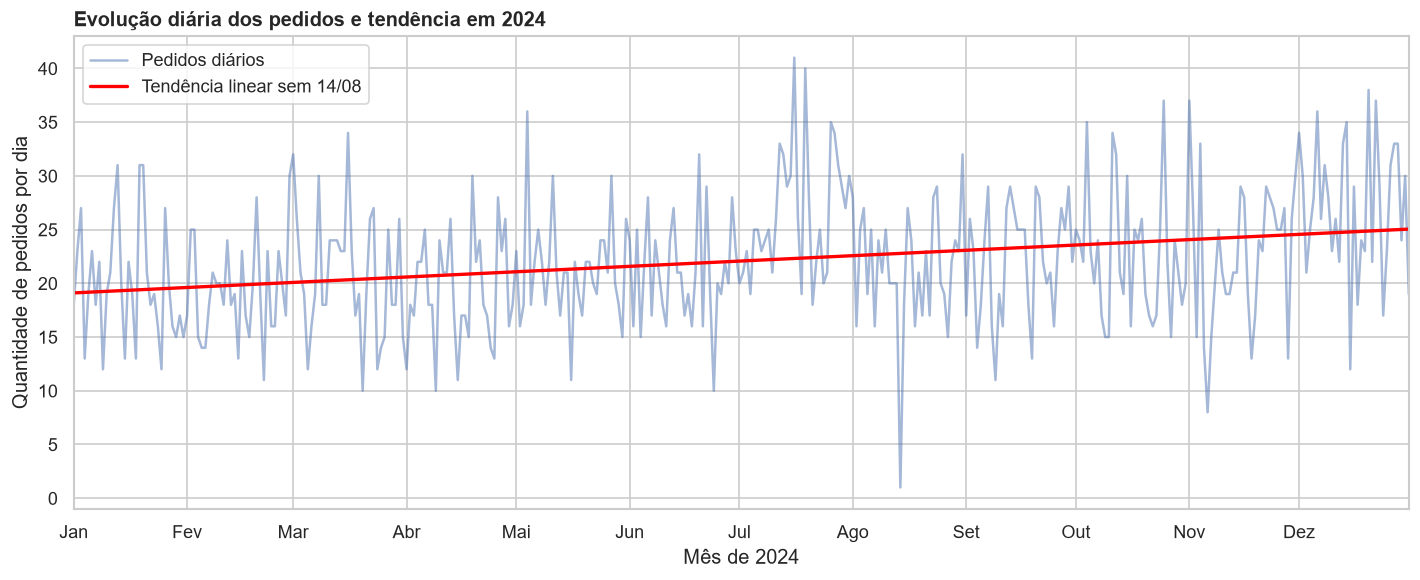

In [136]:
# Sua solução aqui
# Contar os pedidos de cada dia de 2024
calendario = pd.date_range("2024-01-01", "2024-12-31", freq="D")

serie_diaria = (
    pedidos_2024.set_index("data_hora")
    .resample("D")
    .size()
    .reindex(calendario, fill_value=0)
)

# (a) Comparar o primeiro e o quarto trimestre
primeiro_trimestre = serie_diaria.loc["2024-01-01":"2024-03-31"]
quarto_trimestre = serie_diaria.loc["2024-10-01":"2024-12-31"]

media_t1 = primeiro_trimestre.mean()
media_t4 = quarto_trimestre.mean()

crescimento_trimestres = (media_t4 / media_t1 - 1) * 100

resumo_trimestres = pd.DataFrame({
    "Trimestre": ["1º trimestre", "4º trimestre"],
    "Total de pedidos": [
        primeiro_trimestre.sum(),
        quarto_trimestre.sum()
    ],
    "Quantidade de dias": [
        len(primeiro_trimestre),
        len(quarto_trimestre)
    ],
    "Média de pedidos por dia": [media_t1, media_t4]
})

display(resumo_trimestres.round(2))
print(f"Crescimento entre os trimestres: {crescimento_trimestres:.2f}%")

# (b) Ajustar a reta sem o dia anômalo
serie_ajuste = serie_diaria.drop(pd.Timestamp("2024-08-14"))

# Dias transcorridos desde 01/01, preservando o intervalo de 14/08
x = (serie_ajuste.index - calendario[0]).days.to_numpy()
y = serie_ajuste.to_numpy()

inclinacao, intercepto = np.polyfit(x, y, 1)

# Valores da reta no início e no fim do ano
dias_ano = (calendario - calendario[0]).days.to_numpy()
tendencia = inclinacao * dias_ano + intercepto

estimativa_inicio = tendencia[0]
estimativa_fim = tendencia[-1]

crescimento_reta = (
    (estimativa_fim / estimativa_inicio) - 1
) * 100

print(f"\nInclinação da reta: {inclinacao:.5f}")
print(f"Pedidos/dia estimados em 01/01: {estimativa_inicio:.2f}")
print(f"Pedidos/dia estimados em 31/12: {estimativa_fim:.2f}")
print(f"Crescimento estimado pela reta: {crescimento_reta:.2f}%")

# Mostrar a série e a tendência
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    serie_diaria.index,
    serie_diaria.values,
    alpha=0.5,
    label="Pedidos diários"
)
ax.plot(
    calendario,
    tendencia,
    color="red",
    linewidth=2,
    label="Tendência linear sem 14/08"
)

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]
marcas_meses = pd.date_range("2024-01-01", periods=12, freq="MS")

ax.set_xticks(marcas_meses)
ax.set_xticklabels(meses)
ax.set_xlim(calendario[0], calendario[-1])
ax.set_title("Evolução diária dos pedidos e tendência em 2024")
ax.set_xlabel("Mês de 2024")
ax.set_ylabel("Quantidade de pedidos por dia")
ax.legend()

plt.tight_layout()
plt.show()

*Sua resposta aqui*

O crescimento foi avaliado de duas formas, usando a série diária
de pedidos de 2024.

Na primeira comparação, a média passou de 20,04 pedidos por dia
no primeiro trimestre para 24,09 no quarto trimestre. Isso representa
um crescimento de 20,17%, ou aproximadamente 4 pedidos a mais por dia.

Na segunda comparação, foi ajustada uma reta à série diária com
`np.polyfit`, excluindo o dia anômalo 14/08 somente desse ajuste.
As datas mantiveram sua posição original no calendário.

A inclinação foi positiva, de aproximadamente 0,01627. Isso significa
que, a cada dia transcorrido, a reta aumenta sua estimativa de volume
diário em cerca de 0,016 pedido.

Pela reta, o volume estimado passou de 19,11 pedidos por dia em
01/01 para 25,04 em 31/12, um crescimento de 31,07%.

As duas formas indicam crescimento ao longo de 2024. Os percentuais
diferem porque a primeira compara as médias observadas de dois
trimestres, enquanto a segunda usa os dias do ano para estimar
uma tendência e comparar seus valores no início e no fim do período.

No gráfico, a reta vermelha ascendente mostra essa tendência.
A linha diária mostra que o movimento oscilou ao longo do ano,
mesmo com o crescimento geral.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [137]:
# Sua solução aqui
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Cores gerais
CORES = {
    "destaque": "#2563EB",
    "neutro": "#B8BEC7",
    "alerta": "#D97706"
}

# A mesma categoria mantém a mesma cor em todos os gráficos
CORES_CUPOM = {
    False: CORES["neutro"],
    True: CORES["destaque"]
}

CORES_CHUVA = {
    False: CORES["neutro"],
    True: CORES["alerta"]
}

CORES_CIDADES = {
    "São Paulo": "#2563EB",
    "Rio de Janeiro": "#0F766E",
    "Belo Horizonte": "#7C3AED"
}

# Formato brasileiro para valores monetários
def formatar_reais(valor, posicao):
    numero = f"{valor:,.2f}"
    numero = numero.replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {numero}"

FORMATADOR_REAIS = FuncFormatter(formatar_reais)

# Formatos para outros eixos
FORMATADOR_PERCENTUAL = FuncFormatter(
    lambda valor, posicao: f"{valor:.0f}%"
)

FORMATADOR_MINUTOS = FuncFormatter(
    lambda valor, posicao: f"{valor:.0f} min"
)

# Aparência geral
sns.set_theme(style="white", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

Foi definido um padrão visual para os gráficos da etapa.
O azul será usado para destacar o resultado principal e o cinza
para os demais dados. Nas comparações com cupom, azul representa
com cupom e cinza representa sem cupom. Nas comparações de chuva,
laranja representa com chuva e cinza representa sem chuva.
Cada cidade também recebeu uma cor fixa.

Foi criado um formatador para apresentar valores monetários
no padrão brasileiro, como R$ 50,00. Também foram definidos
formatadores para percentuais e minutos.

Os gráficos terão fundo branco, sem grades desnecessárias
e sem bordas superior e direita. Cada gráfico terá um título
com a conclusão, eixos com as unidades e uma ordenação
adequada à comparação.

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

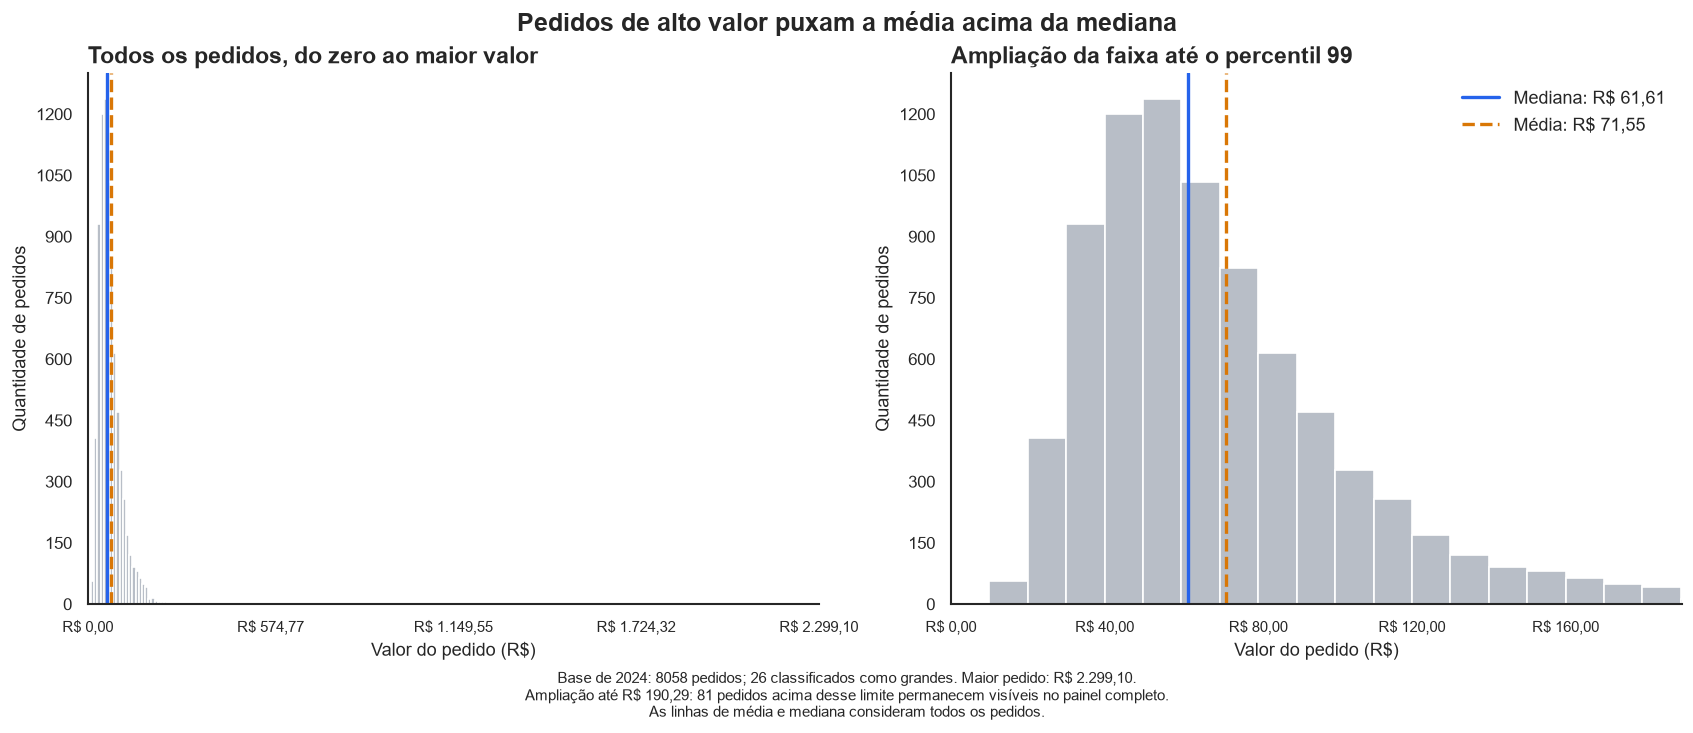

In [138]:
# Sua solução aqui
ticket = pedidos_2024["valor_pedido"].dropna()

media_ticket = ticket.mean()
mediana_ticket = ticket.median()
maior_ticket = ticket.max()

# Limite usado somente para ampliar a visualização
limite_zoom = ticket.quantile(0.99)
quantidade_fora_zoom = ticket.gt(limite_zoom).sum()
quantidade_grandes = pedidos_2024["pedido_grande"].sum()

# Usar as mesmas faixas nos dois painéis
faixas = np.arange(0, maior_ticket + 10, 10)

fig, eixos = plt.subplots(
    1, 2,
    figsize=(14, 6),
    layout="constrained"
)

# Ambos os histogramas recebem todos os pedidos
for eixo in eixos:
    eixo.hist(
        ticket,
        bins=faixas,
        color=CORES["neutro"],
        edgecolor="white"
    )

    eixo.axvline(
        mediana_ticket,
        color=CORES["destaque"],
        linewidth=2,
        label=f"Mediana: {formatar_reais(mediana_ticket, None)}"
    )

    eixo.axvline(
        media_ticket,
        color=CORES["alerta"],
        linestyle="--",
        linewidth=2,
        label=f"Média: {formatar_reais(media_ticket, None)}"
    )

    eixo.set_xlabel("Valor do pedido (R$)")
    eixo.set_ylabel("Quantidade de pedidos")
    eixo.xaxis.set_major_formatter(FORMATADOR_REAIS)
    eixo.yaxis.set_major_locator(MaxNLocator(integer=True))
    eixo.tick_params(axis="x", labelsize=9)

# Primeiro painel: escala completa
eixos[0].set_xlim(0, maior_ticket)
eixos[0].set_xticks(np.linspace(0, maior_ticket, 5))
eixos[0].set_title("Todos os pedidos, do zero ao maior valor")

# Segundo painel: ampliação da mesma distribuição
eixos[1].set_xlim(0, limite_zoom)
eixos[1].xaxis.set_major_locator(MaxNLocator(nbins=5))
eixos[1].set_title("Ampliação da faixa até o percentil 99")
eixos[1].legend(frameon=False, loc="upper right")

fig.suptitle(
    "Pedidos de alto valor puxam a média acima da mediana",
    fontsize=15,
    fontweight="bold"
)

fig.supxlabel(
    f"Base de 2024: {len(ticket)} pedidos; "
    f"{quantidade_grandes} classificados como grandes. "
    f"Maior pedido: {formatar_reais(maior_ticket, None)}.\n"
    f"Ampliação até {formatar_reais(limite_zoom, None)}: "
    f"{quantidade_fora_zoom} pedidos acima desse limite "
    "permanecem visíveis no painel completo.\n"
    "As linhas de média e mediana consideram todos os pedidos.",
    fontsize=9
)

plt.show()

Foram criados dois histogramas da mesma distribuição, com
intervalos de R$ 10.

O primeiro mostra todos os pedidos, com o eixo horizontal
começando em zero e terminando no maior valor registrado.
Ele permite observar a cauda à direita, formada pelos
pedidos de valores elevados.

O segundo amplia a faixa até o percentil 99 para facilitar
a leitura dos valores mais comuns. O limite da ampliação
e a quantidade de pedidos acima dele foram informados na figura.
Esses pedidos aparecem no primeiro painel.

A média e a mediana foram calculadas com todos os pedidos
e marcadas nos dois gráficos. A média foi de R$ 71,55 e
a mediana de R$ 61,61.

Os pedidos de alto valor puxam a média para a direita.
Na ampliação, fica mais fácil perceber que a linha da média
está acima da mediana. A comparação realizada na Tarefa 4.5,
com e sem os pedidos grandes, também mostrou esse efeito.

Por sofrer menos influência dos pedidos grandes, a mediana
foi escolhida para representar o ticket típico.

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

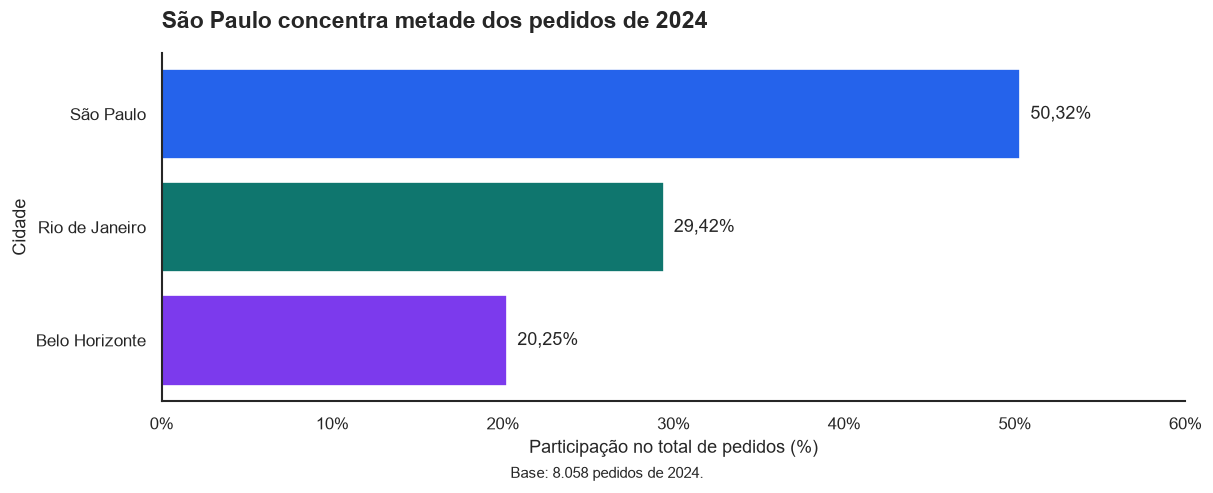

In [139]:
# Sua solução aqui
participacao_cidades = (
    pedidos_2024["cidade"].value_counts(normalize=True) * 100
).sort_values(ascending=False)

# Aplicar a cor definida para cada cidade na Tarefa 7.0
cores_barras = [
    CORES_CIDADES[cidade]
    for cidade in participacao_cidades.index
]

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")

barras = ax.barh(
    participacao_cidades.index,
    participacao_cidades.values,
    color=cores_barras
)

ax.invert_yaxis()

rotulos = [
    f"{valor:.2f}%".replace(".", ",")
    for valor in participacao_cidades.values
]

ax.bar_label(barras, labels=rotulos, padding=6, fontsize=11)

ax.set_title("São Paulo concentra metade dos pedidos de 2024", pad=15)
ax.set_xlabel("Participação no total de pedidos (%)")
ax.set_ylabel("Cidade")
ax.set_xlim(0, 60)
ax.xaxis.set_major_formatter(FORMATADOR_PERCENTUAL)

fig.supxlabel(
    f"Base: {len(pedidos_2024):,} pedidos de 2024.".replace(",", "."),
    fontsize=9
)

plt.show()

Foi criado um gráfico de barras horizontais com a participação
de cada cidade no total de pedidos de 2024. As barras foram
ordenadas da maior para a menor, com os percentuais escritos
ao lado e as cores fixas definidas para cada cidade.

São Paulo concentrou 50,32% dos pedidos, seguido do Rio de Janeiro,
com 29,42%, e de Belo Horizonte, com 20,25%.

Assim, aproximadamente metade dos 8.058 pedidos foi realizada
em São Paulo. Os percentuais somam 99,99% por causa do
arredondamento para duas casas decimais.

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

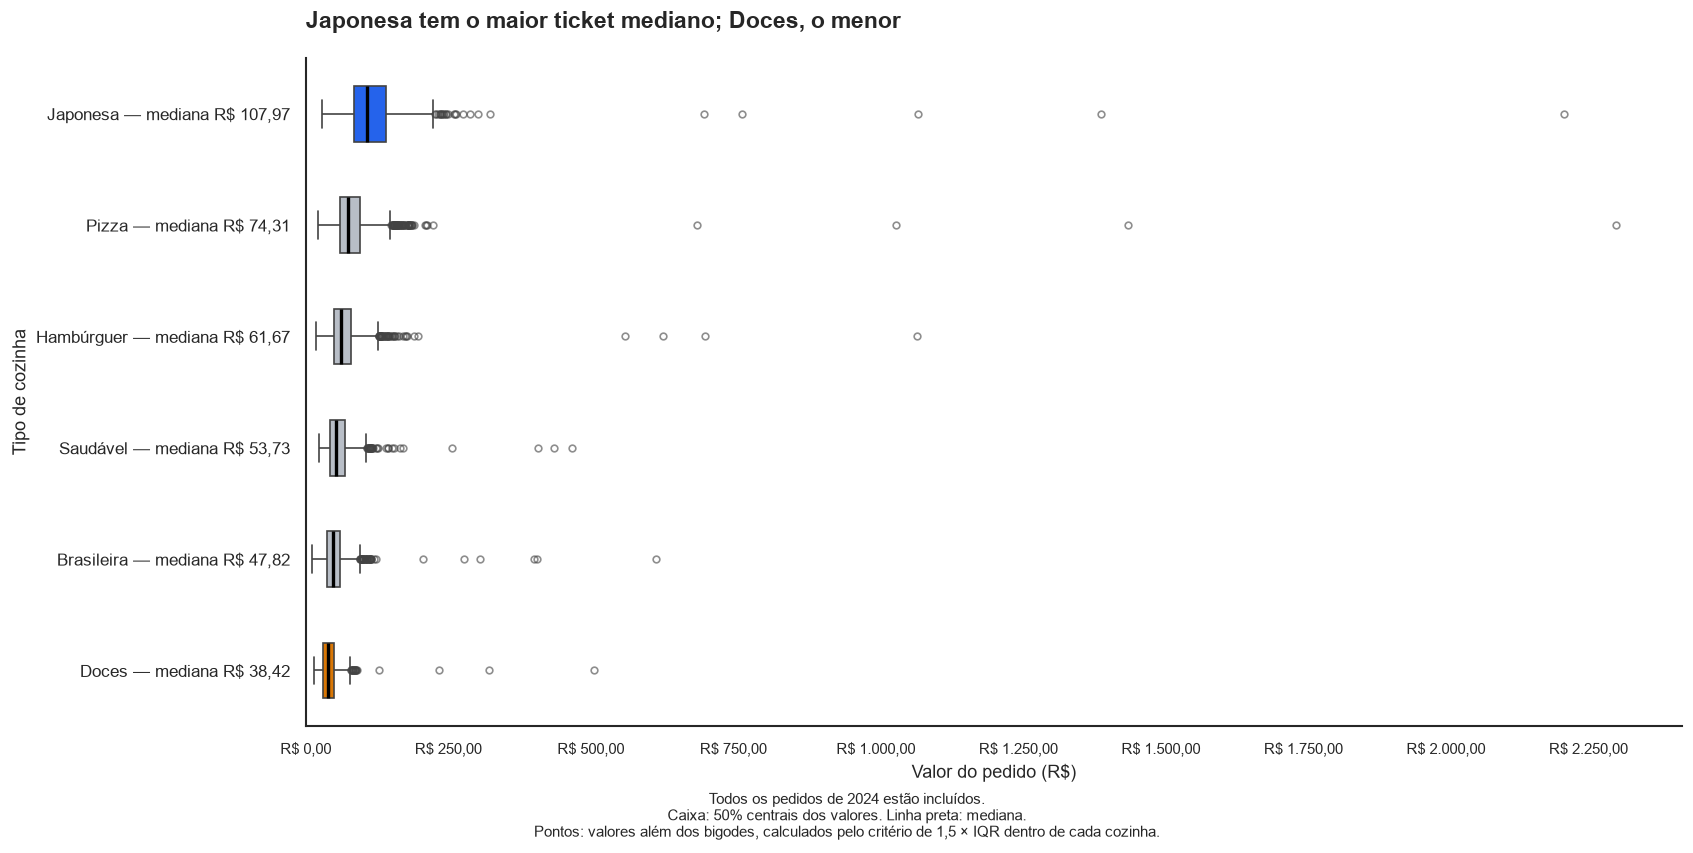

In [140]:
# Sua solução aqui
from matplotlib.ticker import MultipleLocator

# Ordenar as cozinhas pelo ticket mediano, da maior para a menor
medianas_cozinhas = (
    pedidos_2024.groupby("tipo_cozinha")["valor_pedido"]
    .median()
    .sort_values(ascending=False)
)

ordem_cozinhas = medianas_cozinhas.index.tolist()

# Manter as cores definidas anteriormente
cores_cozinhas = {
    cozinha: CORES["neutro"]
    for cozinha in ordem_cozinhas
}

cores_cozinhas[medianas_cozinhas.idxmax()] = CORES["destaque"]
cores_cozinhas[medianas_cozinhas.idxmin()] = CORES["alerta"]

fig, ax = plt.subplots(
    figsize=(14, 7),
    layout="constrained"
)

sns.boxplot(
    data=pedidos_2024,
    x="valor_pedido",
    y="tipo_cozinha",
    order=ordem_cozinhas,
    hue="tipo_cozinha",
    hue_order=ordem_cozinhas,
    palette=cores_cozinhas,
    dodge=False,
    legend=False,
    saturation=1,
    width=0.5,
    showfliers=True,
    medianprops={
        "color": "black",
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markersize": 4,
        "alpha": 0.6
    },
    ax=ax
)

# Mostrar todos os valores, incluindo os outliers
maior_valor = pedidos_2024["valor_pedido"].max()
ax.set_xlim(0, maior_valor * 1.05)

# Marcar o eixo de R$ 250 em R$ 250
ax.xaxis.set_major_locator(MultipleLocator(250))
ax.xaxis.set_major_formatter(FORMATADOR_REAIS)
ax.tick_params(axis="x", labelsize=9)

ax.set_title(
    "Japonesa tem o maior ticket mediano; Doces, o menor",
    pad=18
)
ax.set_xlabel("Valor do pedido (R$)")
ax.set_ylabel("Tipo de cozinha")

# Apresentar a mediana junto ao nome de cada cozinha
rotulos = [
    f"{cozinha} — mediana {formatar_reais(valor, None)}"
    for cozinha, valor in medianas_cozinhas.items()
]

ax.set_yticks(range(len(ordem_cozinhas)))
ax.set_yticklabels(rotulos)

fig.supxlabel(
    "Todos os pedidos de 2024 estão incluídos.\n"
    "Caixa: 50% centrais dos valores. Linha preta: mediana.\n"
    "Pontos: valores além dos bigodes, calculados pelo critério "
    "de 1,5 × IQR dentro de cada cozinha.",
    fontsize=9
)

plt.show()

Foi criado um boxplot para comparar a distribuição do valor
dos pedidos entre as cozinhas. Elas foram ordenadas pelo
ticket mediano, da maior para a menor.

A caixa reúne os 50% centrais dos valores, e a linha preta
dentro dela mostra a mediana. Os bigodes são as linhas externas
que se estendem até os valores observados dentro dos limites
de 1,5 × IQR. Os pontos além dessas linhas representam os
outliers de cada cozinha.

Todos os pedidos foram incluídos, com o eixo em reais e
marcações de R$ 250 em R$ 250. A escala completa permite
visualizar os pedidos de maior valor, embora deixe as caixas
mais concentradas no início do eixo.

Japonesa apresentou o maior ticket mediano, de R$ 107,97,
e foi destacada em azul. Doces apresentou o menor, de R$ 38,42,
e foi destacada em laranja. As demais cozinhas ficaram em cinza.

A ordem dos tickets medianos foi:
Japonesa (R$ 107,97), Pizza (R$ 74,31), Hambúrguer (R$ 61,67),
Saudável (R$ 53,74), Brasileira (R$ 47,82) e Doces (R$ 38,42).

O ticket mediano da cozinha Japonesa foi aproximadamente
2,81 vezes o de Doces. Os pontos de valores elevados mostram
que há pedidos grandes nas distribuições. Estar além dos
bigodes, por si só, não significa que o pedido seja um erro.

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

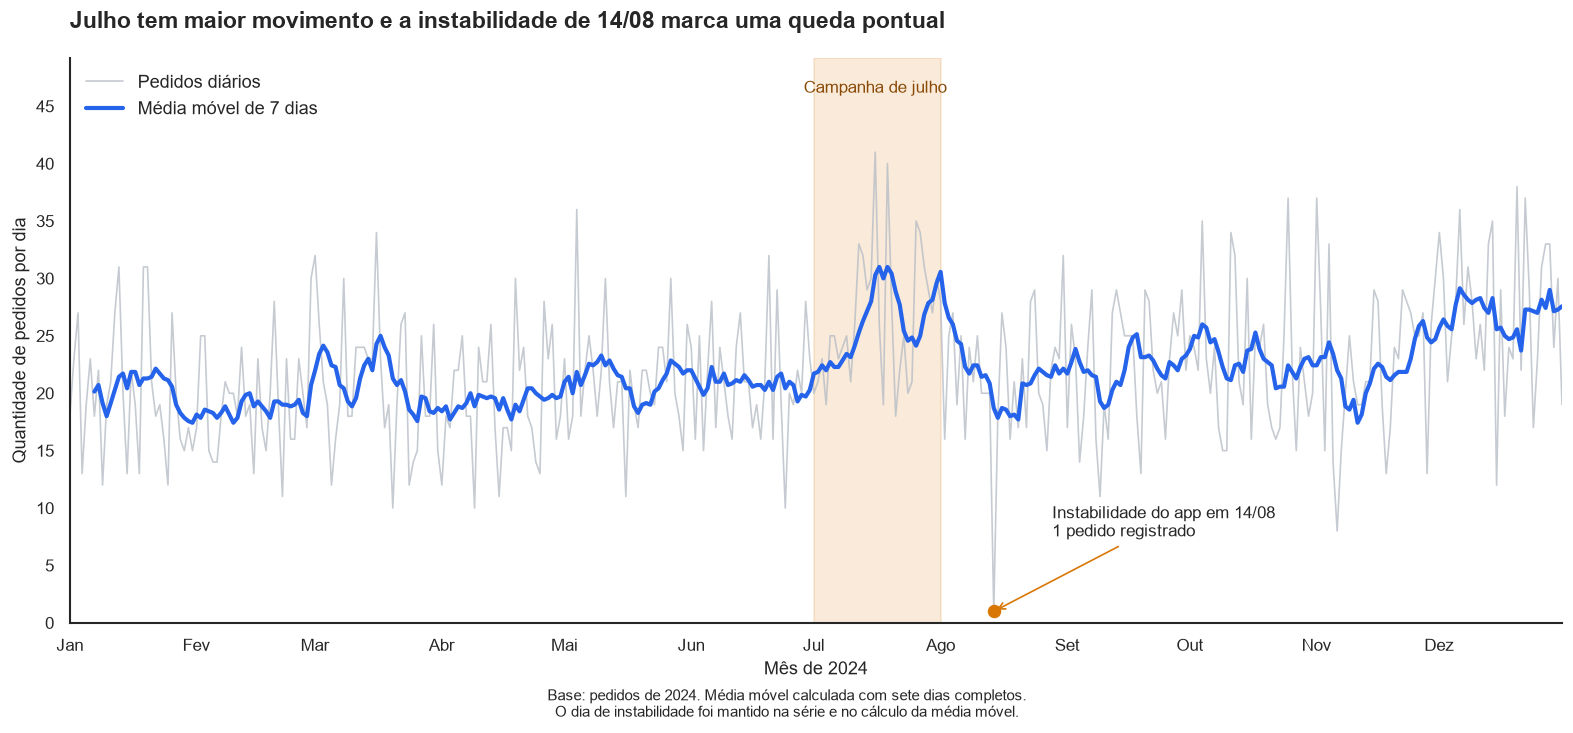

In [141]:
# Sua solução aqui
# Contar os pedidos em cada dia de 2024
calendario = pd.date_range("2024-01-01", "2024-12-31", freq="D")

pedidos_diarios = (
    pedidos_2024.set_index("data_hora")
    .resample("D")
    .size()
    .reindex(calendario, fill_value=0)
)

# Média do dia atual e dos seis anteriores
media_movel_7dias = pedidos_diarios.rolling(
    window=7,
    min_periods=7
).mean()

fig, ax = plt.subplots(
    figsize=(13, 6),
    layout="constrained"
)

# Série diária
ax.plot(
    pedidos_diarios.index,
    pedidos_diarios.values,
    color=CORES["neutro"],
    linewidth=1,
    alpha=0.8,
    label="Pedidos diários"
)

# Média móvel
ax.plot(
    media_movel_7dias.index,
    media_movel_7dias.values,
    color=CORES["destaque"],
    linewidth=2.5,
    label="Média móvel de 7 dias"
)

# Destacar o período da campanha
inicio_campanha = pd.Timestamp("2024-07-01")
fim_campanha = pd.Timestamp("2024-08-01")

ax.axvspan(
    inicio_campanha,
    fim_campanha,
    color=CORES["alerta"],
    alpha=0.15
)

ax.text(
    pd.Timestamp("2024-07-16"),
    0.96,
    "Campanha de julho",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=10,
    color="#8A4B08"
)

# Anotar o dia de instabilidade
dia_instabilidade = pd.Timestamp("2024-08-14")
pedidos_instabilidade = pedidos_diarios.loc[dia_instabilidade]

ax.scatter(
    dia_instabilidade,
    pedidos_instabilidade,
    color=CORES["alerta"],
    s=50,
    zorder=4
)

ax.annotate(
    f"Instabilidade do app em 14/08\n"
    f"{pedidos_instabilidade} pedido registrado",
    xy=(dia_instabilidade, pedidos_instabilidade),
    xytext=(35, 45),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": CORES["alerta"]
    },
    fontsize=10
)

# Meses no eixo horizontal
meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]
marcas_meses = pd.date_range("2024-01-01", periods=12, freq="MS")

ax.set_xticks(marcas_meses)
ax.set_xticklabels(meses)
ax.set_xlim(calendario[0], calendario[-1])

ax.set_ylim(0, pedidos_diarios.max() * 1.2)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_title(
    "Julho tem maior movimento e a instabilidade de 14/08 marca uma queda pontual",
    pad=18
)
ax.set_xlabel("Mês de 2024")
ax.set_ylabel("Quantidade de pedidos por dia")
ax.legend(frameon=False, loc="upper left")

fig.supxlabel(
    "Base: pedidos de 2024. Média móvel calculada com sete dias completos.\n"
    "O dia de instabilidade foi mantido na série e no cálculo da média móvel.",
    fontsize=9
)

plt.show()

Foi criada a série diária de pedidos de 2024 e calculada uma
média móvel de 7 dias. A linha cinza mostra os pedidos de cada
dia, enquanto a azul apresenta a média do dia e dos seis anteriores.
A média móvel começa no sétimo dia, quando há uma janela completa.

A campanha foi destacada considerando todo o mês de julho.
Nesse mês, foram registrados 822 pedidos, com média de 26,52
por dia, acima dos 21 pedidos diários de junho e dos 21,35
de agosto. O aumento coincide com a campanha, mas o gráfico
sozinho não permite atribuir todo o crescimento a ela.

O dia de instabilidade do aplicativo, 14/08/2024, foi anotado
no gráfico e apresentou apenas 1 pedido. Ele foi mantido na
série e no cálculo da média móvel, permitindo visualizar
a queda e seu efeito nos dias seguintes.

A média móvel facilita a leitura da evolução do movimento,
enquanto a série diária preserva os picos e as quedas pontuais.

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

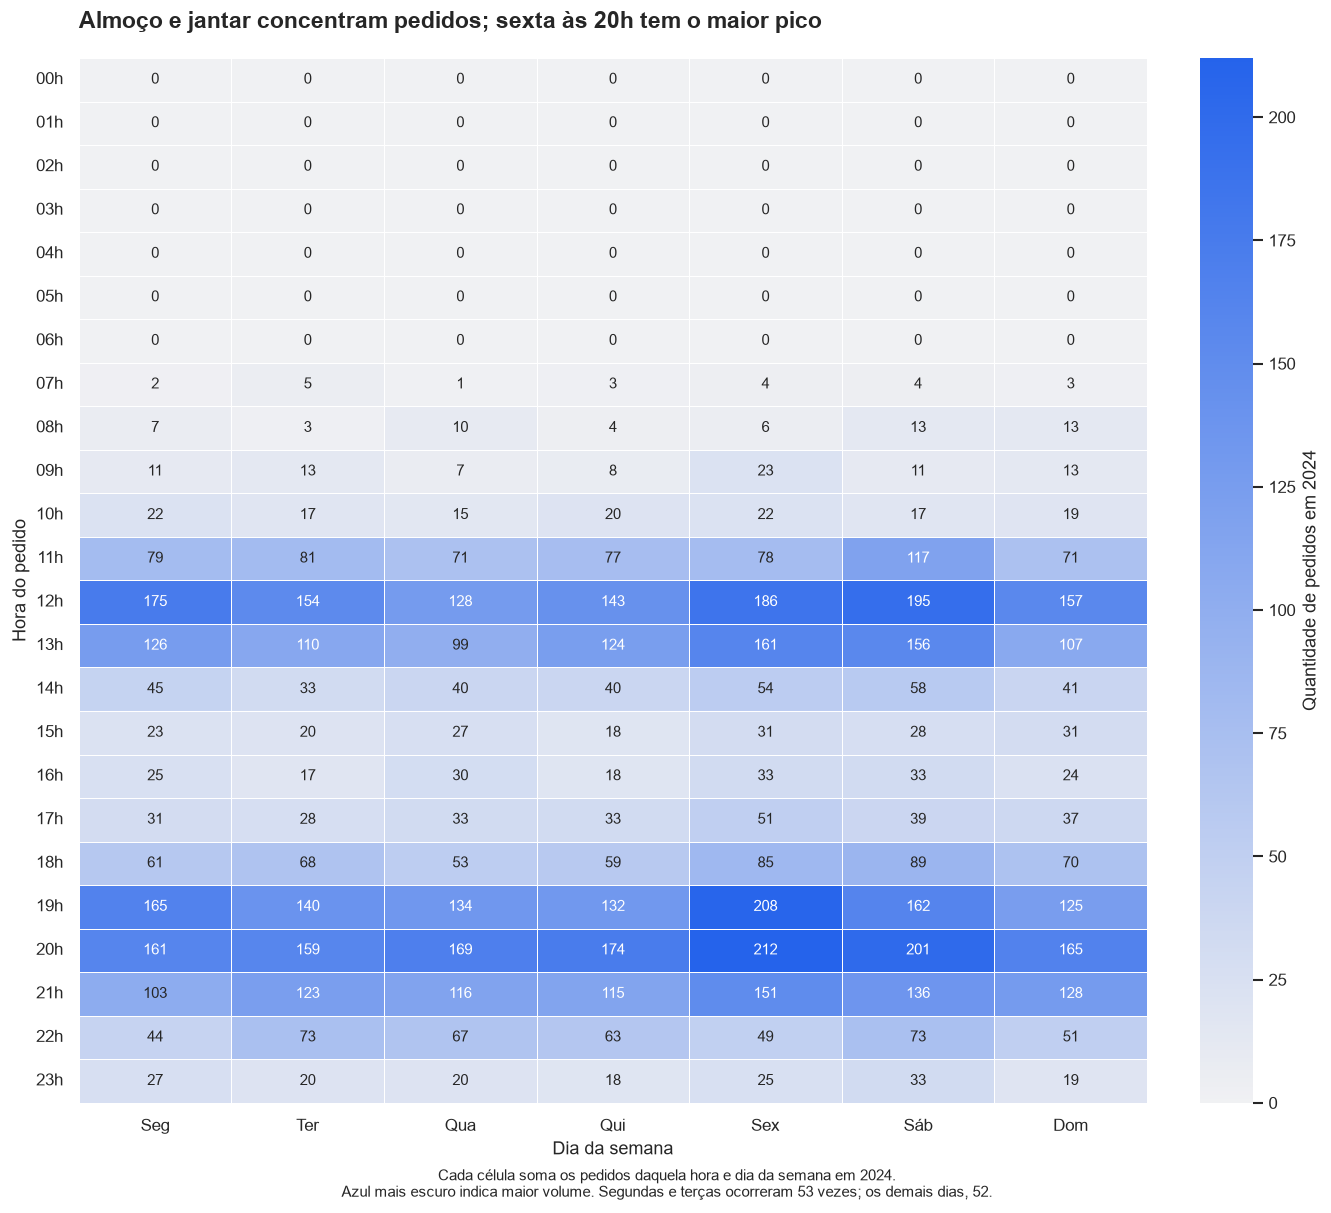

In [142]:
# Sua solução aqui
dias_semana = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

# Quantidade de pedidos por hora e dia da semana
tabela_hora_dia = pedidos_2024.pivot_table(
    index="hora",
    columns="dia_semana",
    values="pedido_id",
    aggfunc="count",
    fill_value=0,
    observed=True
).reindex(
    index=range(24),
    columns=dias_semana,
    fill_value=0
)

# Graduação do cinza claro ao azul definido na Tarefa 7.0
paleta_calor = sns.light_palette(
    CORES["destaque"],
    as_cmap=True
)

fig, ax = plt.subplots(
    figsize=(11, 10),
    layout="constrained"
)

sns.heatmap(
    tabela_hora_dia,
    cmap=paleta_calor,
    vmin=0,
    annot=True,
    fmt="d",
    linewidths=0.5,
    linecolor="white",
    annot_kws={"fontsize": 9},
    cbar_kws={"label": "Quantidade de pedidos em 2024"},
    ax=ax
)

ax.set_title(
    "Almoço e jantar concentram pedidos; sexta às 20h tem o maior pico",
    pad=18
)
ax.set_xlabel("Dia da semana")
ax.set_ylabel("Hora do pedido")
ax.set_yticklabels(
    [f"{hora:02d}h" for hora in range(24)],
    rotation=0
)
ax.tick_params(axis="x", rotation=0)

fig.supxlabel(
    "Cada célula soma os pedidos daquela hora e dia da semana em 2024.\n"
    "Azul mais escuro indica maior volume. "
    "Segundas e terças ocorreram 53 vezes; os demais dias, 52.",
    fontsize=9
)

plt.show()

Foi criado um mapa de calor com as horas nas linhas e os dias
da semana nas colunas. Os números mostram o total de pedidos
de cada combinação em 2024. Quanto mais escuro o azul, maior
o volume de pedidos.

As regiões mais escuras aparecem no almoço e no jantar.
O maior pico ocorreu às sextas-feiras, entre 20h e 20h59,
com 212 pedidos. Na sexta, a faixa das 19h também apresentou
volume elevado, com 208 pedidos.

No sábado, destacaram-se as 20h, com 201 pedidos, e as 12h,
com 195. Esses resultados ajudam a identificar os horários
de maior demanda para o planejamento da operação.

O mapa apresenta totais acumulados no ano. Segundas e terças
ocorreram 53 vezes em 2024, enquanto os outros dias ocorreram
52 vezes. Essa diferença deve ser considerada na comparação
entre as colunas.

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

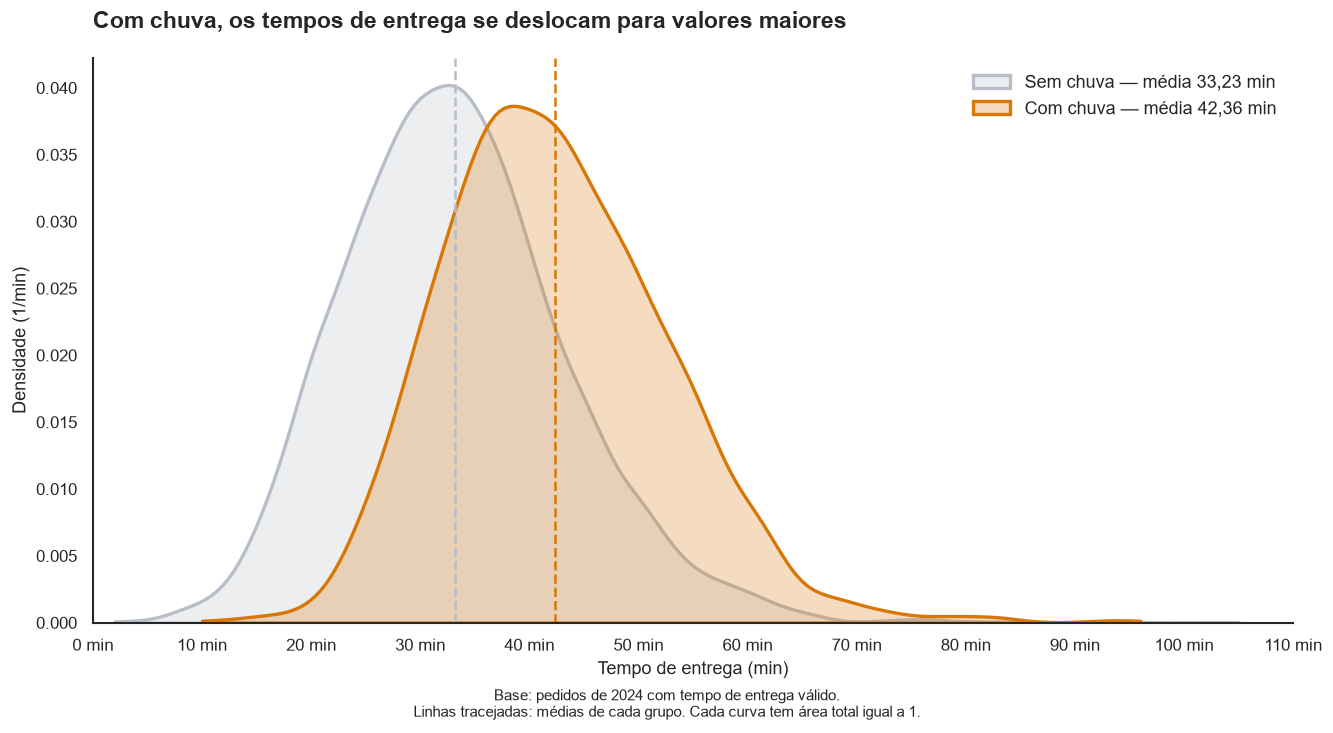

In [143]:
# Sua solução aqui
from matplotlib.ticker import MultipleLocator

# Selecionar os pedidos com tempo de entrega válido
dados_chuva = pedidos_2024.dropna(
    subset=["tempo_entrega_min", "chuva"]
)

fig, ax = plt.subplots(
    figsize=(11, 6),
    layout="constrained"
)

for choveu, nome in [(False, "Sem chuva"), (True, "Com chuva")]:
    tempos = dados_chuva.loc[
        dados_chuva["chuva"].eq(choveu),
        "tempo_entrega_min"
    ]

    cor = CORES_CHUVA[choveu]
    media = tempos.mean()

    # Cada curva é normalizada separadamente
    sns.kdeplot(
        x=tempos,
        fill=True,
        alpha=0.25,
        linewidth=2,
        color=cor,
        cut=0,
        label=f"{nome} — média {media:.2f} min".replace(".", ","),
        ax=ax
    )

    ax.axvline(
        media,
        color=cor,
        linestyle="--",
        linewidth=1.5
    )

ax.set_title(
    "Com chuva, os tempos de entrega se deslocam para valores maiores",
    pad=18
)
ax.set_xlabel("Tempo de entrega (min)")
ax.set_ylabel("Densidade (1/min)")

ax.set_xlim(
    0,
    dados_chuva["tempo_entrega_min"].max() + 5
)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_major_formatter(FORMATADOR_MINUTOS)

ax.legend(frameon=False)

fig.supxlabel(
    "Base: pedidos de 2024 com tempo de entrega válido.\n"
    "Linhas tracejadas: médias de cada grupo. "
    "Cada curva tem área total igual a 1.",
    fontsize=9
)

plt.show()

Foram criadas duas curvas de densidade para comparar a distribuição
do tempo de entrega com e sem chuva. Foram usados somente os tempos
válidos, e cada curva foi normalizada separadamente.

A curva laranja representa os pedidos com chuva, e a cinza,
os pedidos sem chuva. As linhas tracejadas mostram as médias
de cada grupo.

Com chuva, o tempo médio foi de 42,36 minutos. Sem chuva,
foi de 33,23 minutos, uma diferença de 9,13 minutos.

O deslocamento da curva com chuva para a direita mostra que
os tempos de entrega se concentram em valores maiores nesse
grupo. Existe sobreposição entre as distribuições, indicando
que os tempos também variam dentro de cada situação.

O resultado mostra uma associação entre chuva e entregas
mais demoradas. A comparação, sozinha, não isola a influência
de outros fatores, como distância, horário e volume de pedidos.

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

,pedidos_avaliados,avaliacao_media
faixa_tempo,,
Até 5,3,4.00
5–10,20,4.50
10–15,106,4.53
15–20,352,4.50
20–25,673,4.49
25–30,1023,4.48
30–35,1249,4.49
35–40,1154,4.41
40–45,857,4.27


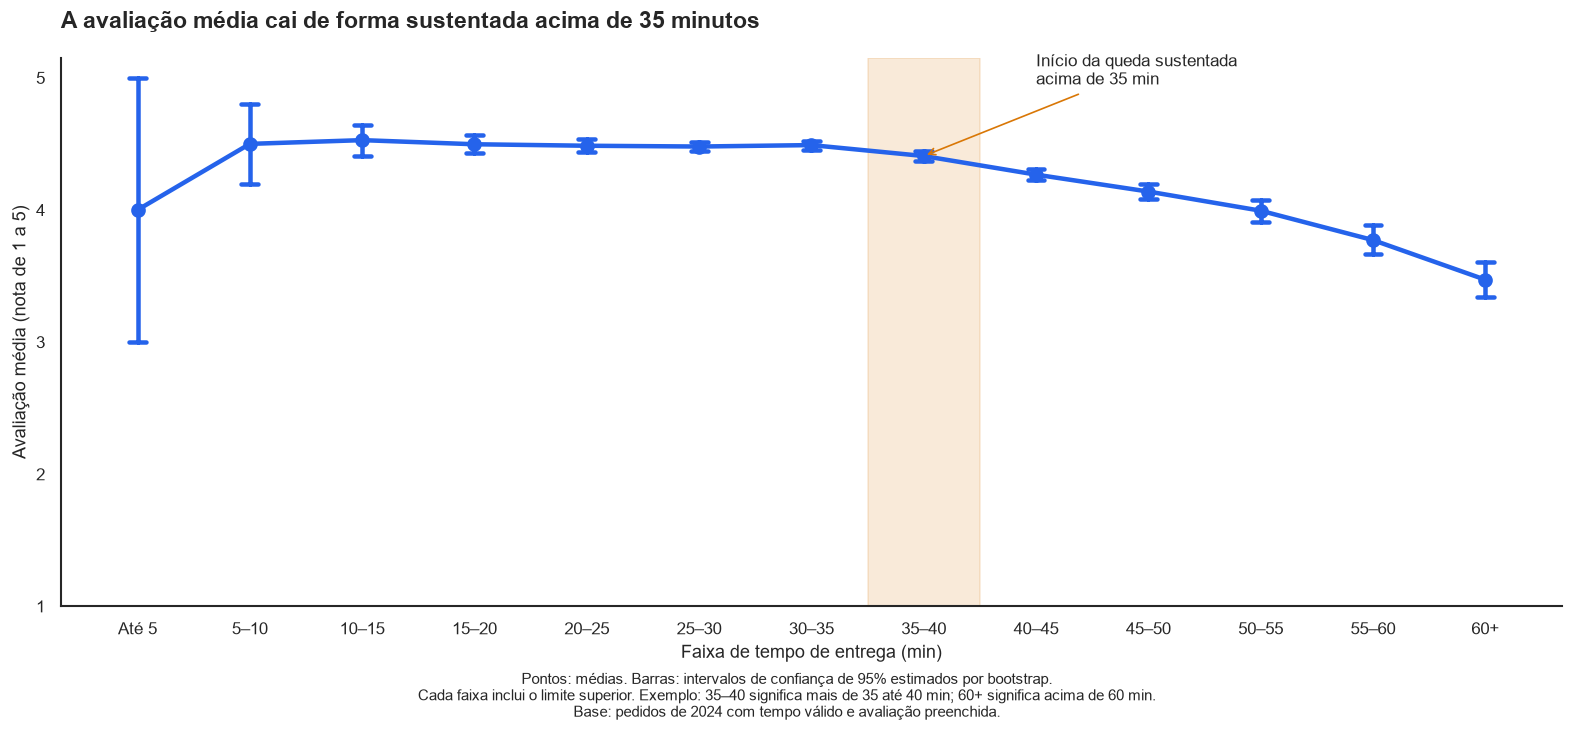

In [144]:
# Sua solução aqui
# Selecionar pedidos com tempo válido e avaliação preenchida
dados_avaliacao = pedidos_2024.dropna(
    subset=["tempo_entrega_min", "avaliacao"]
).copy()

# Faixas de 5 minutos, incluindo tempos acima de 60 minutos
limites = list(range(0, 61, 5)) + [float("inf")]

rotulos = [
    "Até 5", "5–10", "10–15", "15–20",
    "20–25", "25–30", "30–35", "35–40",
    "40–45", "45–50", "50–55", "55–60", "60+"
]

dados_avaliacao["faixa_tempo"] = pd.cut(
    dados_avaliacao["tempo_entrega_min"],
    bins=limites,
    labels=rotulos,
    include_lowest=True,
    right=True
)

# Conferir as médias e o tamanho de cada grupo
resumo_faixas = dados_avaliacao.groupby(
    "faixa_tempo",
    observed=False
).agg(
    pedidos_avaliados=("avaliacao", "count"),
    avaliacao_media=("avaliacao", "mean")
)

display(resumo_faixas.round(2))

fig, ax = plt.subplots(
    figsize=(13, 6),
    layout="constrained"
)

# Intervalos de confiança estimados por reamostragem (bootstrap)
sns.pointplot(
    data=dados_avaliacao,
    x="faixa_tempo",
    y="avaliacao",
    order=rotulos,
    estimator="mean",
    errorbar=("ci", 95),
    n_boot=2000,
    seed=42,
    color=CORES["destaque"],
    capsize=0.15,
    ax=ax
)

# Destacar o início da queda sustentada
posicao_queda = rotulos.index("35–40")
media_faixa = resumo_faixas.loc["35–40", "avaliacao_media"]

ax.axvspan(
    posicao_queda - 0.5,
    posicao_queda + 0.5,
    color=CORES["alerta"],
    alpha=0.15
)

ax.annotate(
    "Início da queda sustentada\nacima de 35 min",
    xy=(posicao_queda, media_faixa),
    xytext=(posicao_queda + 1, 4.95),
    arrowprops={
        "arrowstyle": "->",
        "color": CORES["alerta"]
    },
    fontsize=10,
    ha="left"
)

ax.set_title(
    "A avaliação média cai de forma sustentada acima de 35 minutos",
    pad=18
)
ax.set_xlabel("Faixa de tempo de entrega (min)")
ax.set_ylabel("Avaliação média (nota de 1 a 5)")
ax.set_ylim(1, 5.15)
ax.set_yticks([1, 2, 3, 4, 5])

fig.supxlabel(
    "Pontos: médias. Barras: intervalos de confiança de 95% "
    "estimados por bootstrap.\n"
    "Cada faixa inclui o limite superior. "
    "Exemplo: 35–40 significa mais de 35 até 40 min; 60+ significa acima de 60 min.\n"
    "Base: pedidos de 2024 com tempo válido e avaliação preenchida.",
    fontsize=9
)

plt.show()

Os tempos de entrega foram agrupados em faixas de 5 minutos
até 60 minutos, além de uma categoria para tempos acima de 60.
Cada faixa inclui o limite superior. Por exemplo, 35–40 reúne
tempos maiores que 35 e menores ou iguais a 40 minutos.

Foram considerados somente os pedidos com tempo válido e
avaliação preenchida. Para cada faixa, foi calculada a avaliação
média e apresentado um intervalo de confiança de 95%,
estimado por bootstrap.

A queda sustentada começa na faixa acima de 35 até 40 minutos,
destacada no gráfico. A média passa de 4,49 na faixa de 30–35
para 4,41 na faixa de 35–40 e continua diminuindo nas seguintes.

Na faixa de 40–45 minutos, a média foi de 4,27. Entre 55 e
60 minutos, foi de 3,77. Acima de 60 minutos, chegou a 3,47.

As primeiras faixas têm poucos pedidos avaliados. A faixa até
5 minutos, por exemplo, possui apenas 3 avaliações, por isso
sua média apresenta maior incerteza.

A faixa destacada foi escolhida pela sequência de queda
observada nas médias. Ela representa um ponto de atenção
operacional, e não um limite exato comprovado por teste.

O gráfico mostra uma associação entre maior tempo de entrega
e menor avaliação entre os pedidos avaliados.

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

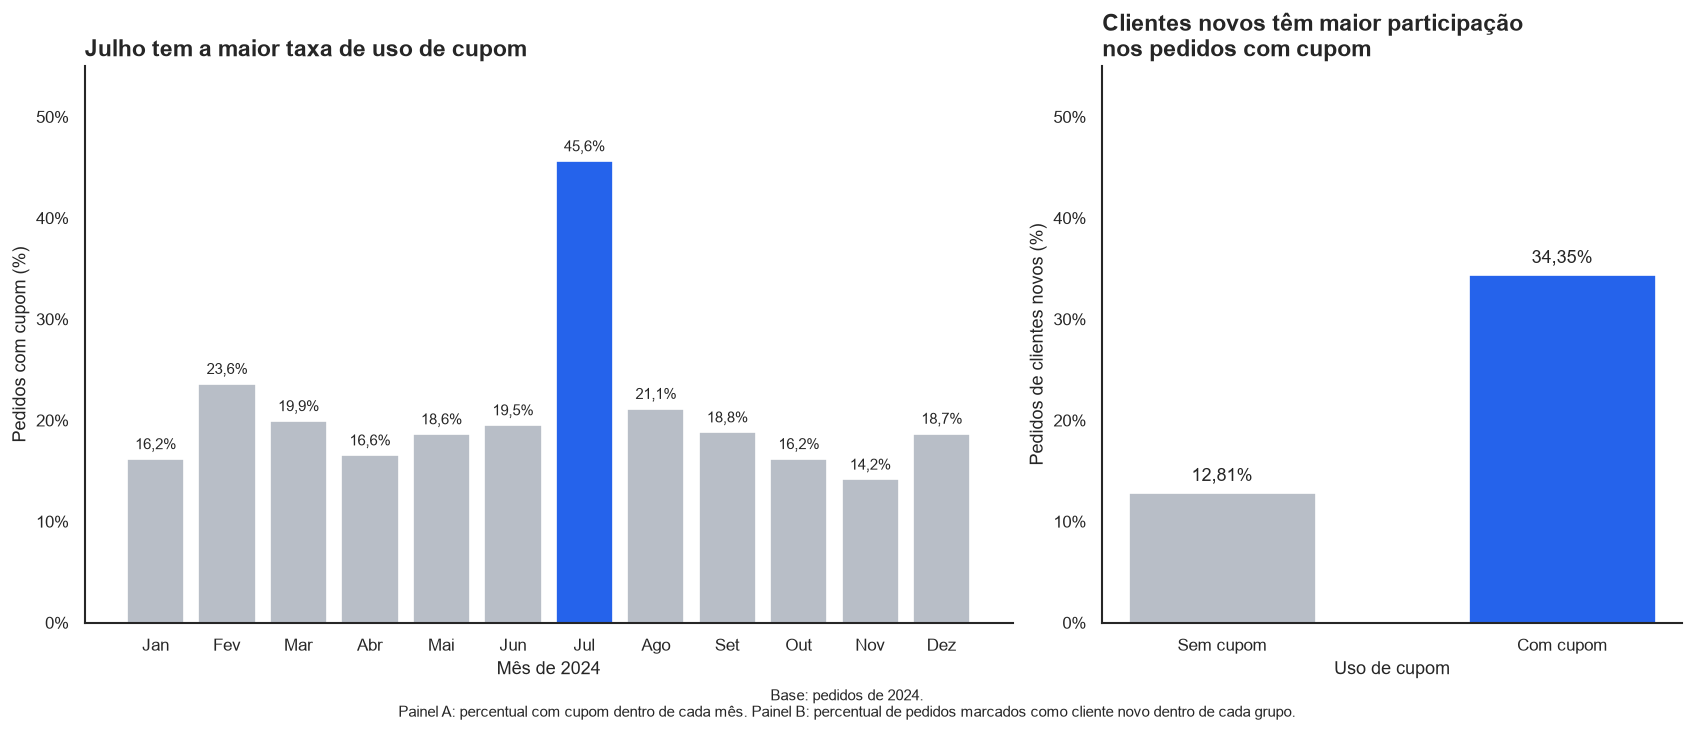

In [145]:
# Sua solução aqui
# (a) Taxa de uso de cupom por mês
taxa_cupom_mensal = (
    pedidos_2024.groupby("mes")["cupom"]
    .mean()
    .reindex(range(1, 13))
    * 100
)

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

cores_meses = [
    CORES["destaque"] if mes == 7 else CORES["neutro"]
    for mes in taxa_cupom_mensal.index
]

# (b) Percentual de pedidos de clientes novos em cada grupo
clientes_novos_cupom = (
    pedidos_2024.groupby("cupom")["cliente_novo"]
    .mean()
    .reindex([False, True])
    * 100
)

fig, eixos = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.6, 1]},
    layout="constrained"
)

# Painel A
barras_meses = eixos[0].bar(
    meses,
    taxa_cupom_mensal.values,
    color=cores_meses
)

eixos[0].bar_label(
    barras_meses,
    labels=[
        f"{valor:.1f}%".replace(".", ",")
        for valor in taxa_cupom_mensal.values
    ],
    padding=4,
    fontsize=9
)

eixos[0].set_title("Julho tem a maior taxa de uso de cupom")
eixos[0].set_xlabel("Mês de 2024")
eixos[0].set_ylabel("Pedidos com cupom (%)")

# Painel B
barras_clientes = eixos[1].bar(
    ["Sem cupom", "Com cupom"],
    clientes_novos_cupom.values,
    color=[CORES_CUPOM[False], CORES_CUPOM[True]],
    width=0.55
)

eixos[1].bar_label(
    barras_clientes,
    labels=[
        f"{valor:.2f}%".replace(".", ",")
        for valor in clientes_novos_cupom.values
    ],
    padding=5,
    fontsize=11
)

eixos[1].set_title(
    "Clientes novos têm maior participação\nnos pedidos com cupom"
)
eixos[1].set_xlabel("Uso de cupom")
eixos[1].set_ylabel("Pedidos de clientes novos (%)")

# Usar a mesma escala percentual nos dois painéis
for eixo in eixos:
    eixo.set_ylim(0, 55)
    eixo.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)

fig.supxlabel(
    "Base: pedidos de 2024.\n"
    "Painel A: percentual com cupom dentro de cada mês. "
    "Painel B: percentual de pedidos marcados como cliente novo "
    "dentro de cada grupo.",
    fontsize=9
)

plt.show()

Foi criada uma figura com dois painéis. O primeiro mostra
o percentual de pedidos com cupom em cada mês, com julho
destacado. O segundo compara a participação de clientes novos
nos pedidos com e sem cupom.

Julho apresentou a maior taxa de uso de cupom, de 45,62%.
Nos demais meses, as taxas ficaram entre 14,16% e 23,61%.
Esse aumento coincide com o período da campanha de julho.

Entre os pedidos com cupom, 34,35% foram marcados como de
clientes novos. Entre os pedidos sem cupom, essa participação
foi de 12,81%, uma diferença de 21,54 pontos percentuais.

Os resultados mostram que o uso de cupom foi mais intenso
em julho e que os pedidos com cupom tiveram maior participação
de clientes novos.

Essa comparação mostra uma associação. Para avaliar se
o cupom trouxe novos clientes e gerou fidelização, seriam
necessárias informações adicionais sobre os clientes e
suas compras posteriores.

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

*Sua resposta aqui*

**7.1 — Histograma:** mostra a frequência e a distribuição dos valores, enquanto um gráfico de médias esconderia a assimetria e os pedidos grandes.

**7.2 — Barras horizontais:** facilitam comparar e ordenar os percentuais das cidades com mais precisão do que um gráfico de pizza.

**7.3 — Boxplot:** mostra mediana, dispersão e outliers por cozinha, enquanto barras de médias esconderiam essas diferenças na distribuição.

**7.4 — Linhas com média móvel:** mostram a continuidade e a tendência ao longo do tempo, enquanto centenas de barras diárias dificultariam a leitura.

**7.5 — Mapa de calor:** destaca os picos no cruzamento entre hora e dia da semana, enquanto várias linhas sobrepostas dificultariam identificar essas combinações.

**7.6 — Curvas de densidade:** mostram o deslocamento e a sobreposição das distribuições, enquanto barras de médias resumiriam cada grupo em apenas um valor.

**7.7 — Pontos com intervalos de confiança:** mostram a média e sua incerteza por faixa, enquanto uma linha simples esconderia a precisão das estimativas.

**7.8 — Barras em dois painéis:** comparam percentuais entre meses e grupos, enquanto misturar as duas comparações no mesmo eixo dificultaria entender suas bases de cálculo.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

Correlação de Pearson


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.70,0.58,-0.01,-0.23
tempo_entrega_min,0.70,1.00,0.42,-0.01,-0.29
taxa_entrega,0.58,0.42,1.00,0.01,-0.10
valor_pedido,-0.01,-0.01,0.01,1.00,-0.01
avaliacao,-0.23,-0.29,-0.10,-0.01,1.00



Correlação de Spearman


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.65,0.79,-0.02,-0.17
tempo_entrega_min,0.65,1.00,0.52,-0.01,-0.24
taxa_entrega,0.79,0.52,1.00,0.01,-0.11
valor_pedido,-0.02,-0.01,0.01,1.00,0.01
avaliacao,-0.17,-0.24,-0.11,0.01,1.00


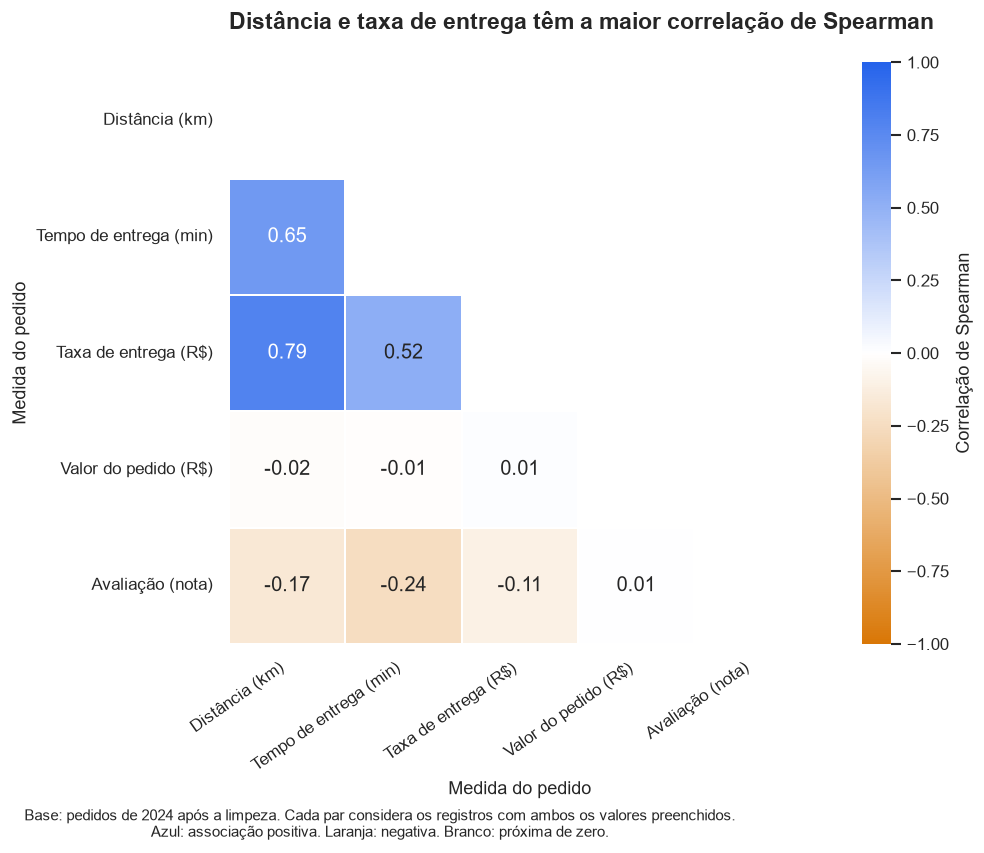

In [146]:
# Sua solução aqui
colunas_correlacao = [
    "distancia_km",
    "tempo_entrega_min",
    "taxa_entrega",
    "valor_pedido",
    "avaliacao"
]

dados_correlacao = pedidos_2024[colunas_correlacao]

# Calcular com os valores completos, arredondando só na exibição
corr_pearson = dados_correlacao.corr(method="pearson")
corr_spearman = dados_correlacao.corr(method="spearman")

print("Correlação de Pearson")
display(corr_pearson.round(2))

print("\nCorrelação de Spearman")
display(corr_spearman.round(2))

# Esconder a diagonal e o triângulo superior
mascara = np.triu(
    np.ones_like(corr_spearman, dtype=bool)
)

rotulos = [
    "Distância (km)",
    "Tempo de entrega (min)",
    "Taxa de entrega (R$)",
    "Valor do pedido (R$)",
    "Avaliação (nota)"
]

# Laranja para valores negativos e azul para positivos
paleta_correlacao = sns.blend_palette(
    [CORES["alerta"], "#FFFFFF", CORES["destaque"]],
    as_cmap=True
)

fig, ax = plt.subplots(
    figsize=(10, 7),
    layout="constrained"
)

sns.heatmap(
    corr_spearman,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap=paleta_correlacao,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    linecolor="white",
    xticklabels=rotulos,
    yticklabels=rotulos,
    cbar_kws={"label": "Correlação de Spearman"},
    ax=ax
)

ax.set_title(
    "Distância e taxa de entrega têm a maior correlação de Spearman",
    pad=20
)
ax.set_xlabel("Medida do pedido")
ax.set_ylabel("Medida do pedido")
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)

for rotulo in ax.get_xticklabels():
    rotulo.set_horizontalalignment("right")

fig.supxlabel(
    "Base: pedidos de 2024 após a limpeza. "
    "Cada par considera os registros com ambos os valores preenchidos.\n"
    "Azul: associação positiva. Laranja: negativa. Branco: próxima de zero.",
    fontsize=9
)

plt.show()

*Sua resposta aqui*

Foram calculadas as matrizes de Pearson e Spearman entre
distância, tempo de entrega, taxa de entrega, valor do pedido
e avaliação, utilizando os dados tratados.

Pearson mede a associação linear entre os valores. Spearman
compara suas posições na ordenação e identifica relações
crescentes ou decrescentes, mesmo quando não seguem uma reta.

A matriz de Spearman foi apresentada em um mapa de calor,
mostrando somente o triângulo inferior para evitar informações
repetidas. A escala foi fixada entre −1 e +1, centrada em zero.
Azul representa associação positiva e laranja, negativa.

A maior correlação de Spearman foi entre distância e taxa
de entrega, com 0,79. Pedidos mais distantes tendem a apresentar
taxas maiores. Em Pearson, essa correlação foi de 0,58.

Distância e tempo de entrega também apresentaram associação
positiva, com Spearman de 0,65 e Pearson de 0,70. Assim,
distâncias maiores tendem a acompanhar entregas mais demoradas.

Tempo de entrega e avaliação apresentaram associação negativa,
com Spearman de −0,24 e Pearson de −0,29. Tempos maiores
tendem a acompanhar notas menores.

O valor do pedido apresentou correlações próximas de zero
com as demais variáveis pelos dois métodos.

Cada correlação foi calculada com os registros que tinham
os dois valores preenchidos. Os resultados mostram associações
e precisam ser interpretados junto dos gráficos e do contexto
do negócio.

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

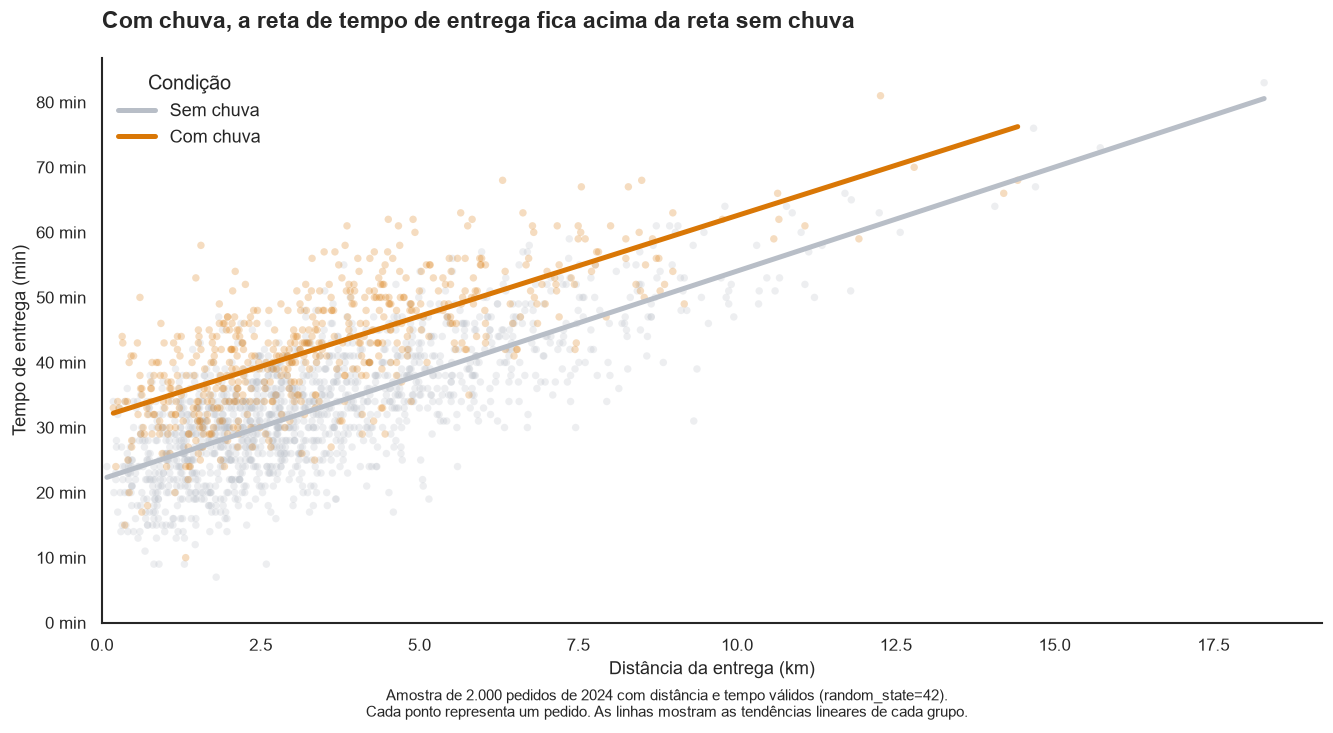

,Grupo,Pedidos na amostra,Inclinação (min/km),Intercepto (min),Tempo estimado a 5 km (min)
0,Sem chuva,1438,3.20,22.09,38.07
1,Com chuva,562,3.09,31.65,47.11


In [147]:
# Sua solução aqui
# Selecionar pedidos com os dados necessários preenchidos
dados_dispersao = pedidos_2024.dropna(
    subset=["distancia_km", "tempo_entrega_min", "chuva"]
)

# Amostra reproduzível de 2.000 pedidos
amostra = dados_dispersao.sample(
    n=2000,
    random_state=42
)

fig, ax = plt.subplots(
    figsize=(11, 6),
    layout="constrained"
)

resultados_retas = []

for choveu, nome in [(False, "Sem chuva"), (True, "Com chuva")]:
    grupo = amostra.loc[amostra["chuva"].eq(choveu)]
    cor = CORES_CHUVA[choveu]

    ax.scatter(
        grupo["distancia_km"],
        grupo["tempo_entrega_min"],
        color=cor,
        alpha=0.25,
        s=20,
        edgecolors="none"
    )

    # Ajustar uma reta para cada grupo
    inclinacao, intercepto = np.polyfit(
        grupo["distancia_km"],
        grupo["tempo_entrega_min"],
        1
    )

    distancias_reta = np.linspace(
        grupo["distancia_km"].min(),
        grupo["distancia_km"].max(),
        100
    )

    tempos_reta = inclinacao * distancias_reta + intercepto

    ax.plot(
        distancias_reta,
        tempos_reta,
        color=cor,
        linewidth=3,
        label=nome
    )

    resultados_retas.append({
        "Grupo": nome,
        "Pedidos na amostra": len(grupo),
        "Inclinação (min/km)": inclinacao,
        "Intercepto (min)": intercepto,
        "Tempo estimado a 5 km (min)": inclinacao * 5 + intercepto
    })

ax.set_title(
    "Com chuva, a reta de tempo de entrega fica acima da reta sem chuva",
    pad=18
)
ax.set_xlabel("Distância da entrega (km)")
ax.set_ylabel("Tempo de entrega (min)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(FORMATADOR_MINUTOS)
ax.legend(title="Condição", frameon=False)

fig.supxlabel(
    "Amostra de 2.000 pedidos de 2024 com distância e tempo válidos "
    "(random_state=42).\n"
    "Cada ponto representa um pedido. As linhas mostram "
    "as tendências lineares de cada grupo.",
    fontsize=9
)

plt.show()

display(pd.DataFrame(resultados_retas).round(2))

*Sua resposta aqui*

Foi criado um gráfico de dispersão com distância no eixo horizontal
e tempo de entrega no vertical. Foram selecionados 2.000 pedidos
com os dados necessários preenchidos, usando random_state=42
para reproduzir a mesma amostra.

Os pontos receberam transparência para facilitar a visualização
das sobreposições. Cinza representa sem chuva e laranja, com chuva.
Foi ajustada uma reta de tendência para cada grupo.

As duas retas são crescentes, mostrando que distâncias maiores
tendem a acompanhar tempos maiores de entrega.

A reta com chuva fica acima da reta sem chuva e apresenta
inclinação semelhante. Na amostra, as inclinações foram de
3,09 min/km com chuva e 3,20 min/km sem chuva.

Para uma distância de 5 km, o tempo estimado pela reta foi
de 47,11 minutos com chuva e 38,07 sem chuva, uma diferença
de aproximadamente 9,05 minutos.

Portanto, a chuva está associada principalmente a um deslocamento
da reta para cima. Para uma mesma distância, os pedidos com chuva
apresentam maior tempo estimado de entrega. A comparação considera
a distância, mas outros fatores também podem influenciar o tempo.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

,Grupo,Pearson
0,Todos os pedidos,0.577991
1,Taxa positiva,0.999998
2,Taxa zero,NaN


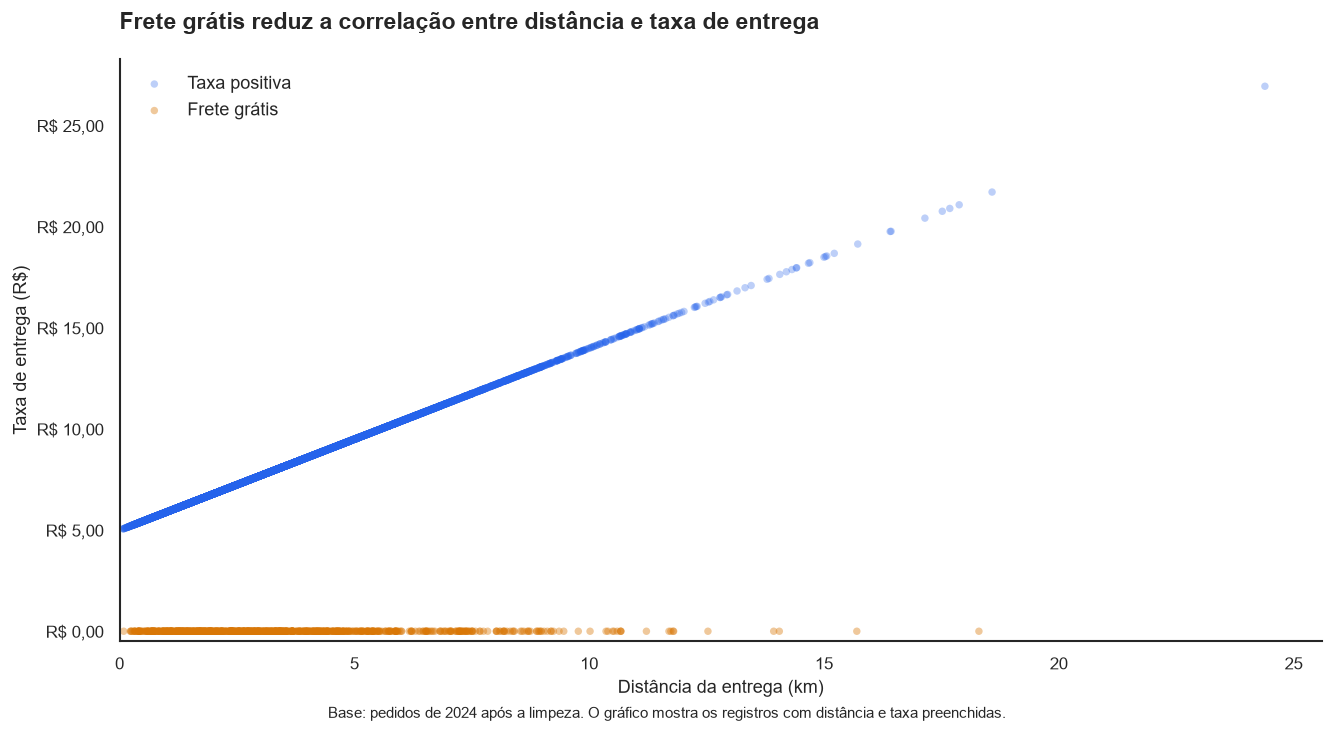

Relação estimada: distância = 1.1111 × taxa -5.5446
Distâncias ausentes em pedidos com taxa positiva: 297
Distâncias ausentes em pedidos com frete grátis: 25


In [148]:
# Sua solução aqui
# Separar os grupos na base tratada
com_taxa = pedidos_2024.loc[pedidos_2024["taxa_entrega"] > 0]
frete_gratis = pedidos_2024.loc[pedidos_2024["taxa_entrega"] == 0]

# Recalcular Pearson usando os pares preenchidos
correlacao_geral = pedidos_2024["distancia_km"].corr(
    pedidos_2024["taxa_entrega"]
)

correlacao_com_taxa = com_taxa["distancia_km"].corr(
    com_taxa["taxa_entrega"]
)

# No grupo de taxa zero, a correlação é indefinida:
# a taxa não varia.
resumo_correlacao = pd.DataFrame({
    "Grupo": ["Todos os pedidos", "Taxa positiva", "Taxa zero"],
    "Pearson": [
        correlacao_geral,
        correlacao_com_taxa,
        np.nan
    ]
})

display(resumo_correlacao.round(6))

# Gráfico com os dois grupos
fig, ax = plt.subplots(
    figsize=(11, 6),
    layout="constrained"
)

ax.scatter(
    com_taxa["distancia_km"],
    com_taxa["taxa_entrega"],
    color=CORES["destaque"],
    alpha=0.3,
    s=20,
    edgecolors="none",
    label="Taxa positiva"
)

ax.scatter(
    frete_gratis["distancia_km"],
    frete_gratis["taxa_entrega"],
    color=CORES["alerta"],
    alpha=0.4,
    s=20,
    edgecolors="none",
    label="Frete grátis"
)

ax.set_title(
    "Frete grátis reduz a correlação entre distância e taxa de entrega",
    pad=18
)
ax.set_xlabel("Distância da entrega (km)")
ax.set_ylabel("Taxa de entrega (R$)")
ax.yaxis.set_major_formatter(FORMATADOR_REAIS)
ax.set_xlim(left=0)
ax.set_ylim(bottom=-0.5)
ax.legend(frameon=False)

fig.supxlabel(
    "Base: pedidos de 2024 após a limpeza. "
    "O gráfico mostra os registros com distância e taxa preenchidas.",
    fontsize=9
)

plt.show()

# Investigar a possibilidade de estimar distâncias ausentes
pares_validos = com_taxa.dropna(
    subset=["distancia_km", "taxa_entrega"]
)

coeficiente, intercepto = np.polyfit(
    pares_validos["taxa_entrega"],
    pares_validos["distancia_km"],
    1
)

print(
    f"Relação estimada: distância = "
    f"{coeficiente:.4f} × taxa {intercepto:+.4f}"
)

print(
    "Distâncias ausentes em pedidos com taxa positiva:",
    com_taxa["distancia_km"].isna().sum()
)

print(
    "Distâncias ausentes em pedidos com frete grátis:",
    frete_gratis["distancia_km"].isna().sum()
)

Foi criado um gráfico de dispersão entre distância e taxa
de entrega, separando os pedidos com taxa positiva daqueles
com frete grátis.

Na base completa, a correlação de Pearson foi de aproximadamente
0,58. Considerando somente os pedidos com taxa positiva,
ela passou para aproximadamente 1,00, mostrando uma relação
linear quase perfeita.

Os pedidos com frete grátis apresentam taxa zero em diferentes
distâncias. Ao misturar esses pedidos com os que seguem
a cobrança por distância, a correlação geral diminui.

No grupo com taxa zero, a correlação é indefinida, pois
a taxa é constante. O NaN desse resultado significa que
o coeficiente não pode ser calculado nesse grupo.

A relação quase perfeita nos pedidos com taxa positiva permitiria
estimar distâncias ausentes a partir da taxa de entrega.
A fórmula ajustada foi aproximadamente:

distância estimada = 1,1111 × taxa de entrega − 5,5446.

Após a limpeza, há 297 distâncias ausentes em pedidos com taxa
positiva e 25 em pedidos com frete grátis. A fórmula poderia
ser avaliada para preencher os 297 casos com taxa positiva,
registrando quais valores foram estimados.

Para os pedidos com frete grátis, a taxa zero não permite
recuperar a distância. Seria necessário outro critério.

Nesta tarefa, foi investigada a possibilidade de preenchimento.
As distâncias da base foram mantidas como estavam.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

*Sua resposta aqui*

**1. Tempo de entrega × avaliação**

A correlação de Spearman foi de −0,24, indicando que entregas
mais demoradas tendem a receber avaliações menores.

É razoável pensar que a espera possa prejudicar a satisfação.
Porém, a correlação sozinha não permite afirmar que o tempo
causou a redução da nota.

Uma possível variável confundidora é a sobrecarga do restaurante.
Ela pode aumentar o tempo de entrega e também provocar erros
no pedido ou problemas na qualidade da comida, reduzindo a nota.

**2. Uso de cupom × participação de clientes novos**

Entre os pedidos com cupom, 34,35% foram de clientes novos.
Nos pedidos sem cupom, essa participação foi de 12,81%.

Essa associação não permite concluir que oferecer cupom causou
a chegada de novos clientes.

Uma possível variável confundidora é a campanha de aquisição.
A empresa pode direcionar publicidade e cupons especialmente
para quem está fazendo o primeiro pedido. Assim, a campanha
pode explicar tanto a maior presença de clientes novos quanto
o maior uso de cupons.

Para avaliar o efeito do cupom, seria necessário comparar
grupos semelhantes, preferencialmente com uma oferta de
cupons distribuída por sorteio.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [149]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [150]:
# Sua solução aqui
from scipy import stats

# Separar os tempos válidos dos dois grupos
com_chuva = pedidos_2024.loc[
    pedidos_2024["chuva"].eq(True),
    "tempo_entrega_min"
].dropna()

sem_chuva = pedidos_2024.loc[
    pedidos_2024["chuva"].eq(False),
    "tempo_entrega_min"
].dropna()

# Resumo para interpretar o resultado em minutos
resumo_h1 = pd.DataFrame({
    "Grupo": ["Sem chuva", "Com chuva"],
    "Pedidos com tempo válido": [len(sem_chuva), len(com_chuva)],
    "Tempo médio (min)": [sem_chuva.mean(), com_chuva.mean()],
    "Tempo mediano (min)": [sem_chuva.median(), com_chuva.median()]
})

display(resumo_h1.round(2))

# Teste unilateral: os tempos com chuva tendem a ser maiores?
estatistica, p_valor = stats.mannwhitneyu(
    com_chuva,
    sem_chuva,
    alternative="greater"
)

# Tamanho de efeito em minutos
diferenca_medias = com_chuva.mean() - sem_chuva.mean()
diferenca_medianas = com_chuva.median() - sem_chuva.median()

decisao = (
    "Rejeitar H0"
    if p_valor < ALFA
    else "Não rejeitar H0"
)

print(f"Estatística U: {estatistica:,.0f}")
print(f"P-valor: {p_valor:.3e}")
print(f"Diferença entre médias: {diferenca_medias:.2f} min")
print(f"Diferença entre medianas: {diferenca_medianas:.2f} min")
print(f"Decisão com alfa = {ALFA}: {decisao}")

# Guardar o resultado, substituindo uma execução anterior de H1
resultados = [
    resultado for resultado in resultados
    if resultado["hipotese"] != "H1"
]

resultados.append({
    "hipotese": "H1",
    "teste": "Mann–Whitney unilateral",
    "estatistica": estatistica,
    "p_valor": p_valor,
    "efeito": (
        f"+{diferenca_medias:.2f} min na média; "
        f"+{diferenca_medianas:.2f} min na mediana"
    ),
    "decisao": decisao
})

,Grupo,Pedidos com tempo válido,Tempo médio (min),Tempo mediano (min)
0,Sem chuva,5667,33.23,33.0
1,Com chuva,2358,42.36,42.0


Estatística U: 9,908,765
P-valor: 6.212e-256
Diferença entre médias: 9.13 min
Diferença entre medianas: 9.00 min
Decisão com alfa = 0.05: Rejeitar H0


*Sua resposta aqui*

**Hipótese de negócio**

Em dias de chuva, as entregas demoram mais.

**Hipóteses estatísticas**

- H0: a distribuição dos tempos de entrega é igual nos grupos
  com e sem chuva.
- H1: os tempos de entrega tendem a ser maiores nos pedidos
  com chuva.

**Teste escolhido**

Foi utilizado o Mann–Whitney unilateral, conforme o planejamento
da Tarefa 1.2. Ele compara uma variável numérica entre dois
grupos pela ordem dos valores. O teste é unilateral porque
a hipótese prevê tempos maiores com chuva.

Foram considerados somente os pedidos com tempo válido.

**Resultados**

| Indicador | Sem chuva | Com chuva |
|---|---:|---:|
| Pedidos com tempo válido | 5.667 | 2.358 |
| Tempo médio | 33,23 min | 42,36 min |
| Tempo mediano | 33 min | 42 min |

A estatística U foi de 9.908.765 e o p-valor foi de
aproximadamente 6,21 × 10⁻²⁵⁶, abaixo de 0,05.
Portanto, rejeitamos H0 ao nível de significância de 5%.

**Tamanho de efeito e interpretação**

Os pedidos com chuva demoraram, em média, 9,13 minutos a mais.
A diferença entre as medianas foi de 9 minutos.

O resultado indica tempos maiores nos pedidos com chuva,
com uma diferença relevante para o planejamento das entregas.

**Limitação**

O teste foi aplicado por pedido, mas a chuva é compartilhada
pelos pedidos da mesma cidade no mesmo dia. Esses registros
podem apresentar dependência, o que limita a interpretação
do p-valor. Uma análise por cidade-dia permitiria avaliar
essa dependência com mais cuidado.

**Frase de negócio**

Nos pedidos registrados com chuva, o tempo médio de entrega
foi aproximadamente 9 minutos maior. Esse resultado deve ser
considerado na definição dos prazos e na organização da operação.

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [151]:
# Sua solução aqui
# Separar os valores dos pedidos
com_cupom = pedidos_2024.loc[
    pedidos_2024["cupom"].eq(True),
    "valor_pedido"
].dropna()

sem_cupom = pedidos_2024.loc[
    pedidos_2024["cupom"].eq(False),
    "valor_pedido"
].dropna()

resumo_h2 = pd.DataFrame({
    "Grupo": ["Sem cupom", "Com cupom"],
    "Pedidos": [len(sem_cupom), len(com_cupom)],
    "Ticket médio (R$)": [sem_cupom.mean(), com_cupom.mean()],
    "Ticket mediano (R$)": [sem_cupom.median(), com_cupom.median()]
})

display(resumo_h2.round(2))

# Teste bilateral: investigar diferenças nos dois sentidos
estatistica, p_valor = stats.mannwhitneyu(
    com_cupom,
    sem_cupom,
    alternative="two-sided"
)

# Diferença descritiva entre os tickets medianos
diferenca_medianas = com_cupom.median() - sem_cupom.median()

diferenca_percentual = (
    com_cupom.median() / sem_cupom.median() - 1
) * 100

decisao = (
    "Rejeitar H0"
    if p_valor < ALFA
    else "Não rejeitar H0"
)

print(f"Estatística U: {estatistica:.1f}")
print(f"P-valor: {p_valor:.3e}")
print(f"Diferença entre medianas: R$ {diferenca_medianas:.2f}")
print(f"Diferença percentual: {diferenca_percentual:.2f}%")
print(f"Decisão com alfa = {ALFA}: {decisao}")

# Guardar o resultado sem duplicar H2 ao executar novamente
resultados = [
    resultado for resultado in resultados
    if resultado["hipotese"] != "H2"
]

resultados.append({
    "hipotese": "H2",
    "teste": "Mann–Whitney bilateral",
    "estatistica": estatistica,
    "p_valor": p_valor,
    "efeito": (
        f"R$ {diferenca_medianas:.2f} no ticket mediano "
        f"({diferenca_percentual:.2f}%)"
    ),
    "decisao": decisao
})

,Grupo,Pedidos,Ticket médio (R$),Ticket mediano (R$)
0,Sem cupom,6349,72.61,62.82
1,Com cupom,1709,67.64,57.22


Estatística U: 4777274.5
P-valor: 3.189e-14
Diferença entre medianas: R$ -5.60
Diferença percentual: -8.91%
Decisão com alfa = 0.05: Rejeitar H0


*Sua resposta aqui*

**Hipótese de negócio**

Pedidos com cupom têm ticket diferente dos pedidos sem cupom.

**Hipóteses estatísticas**

- H0: a distribuição dos valores dos pedidos é igual nos
  grupos com e sem cupom.
- H1: os valores dos pedidos tendem a ser maiores em um
  dos grupos.

**Teste escolhido**

Foi utilizado o Mann–Whitney bilateral. Ele compara os valores
pela ordem dos pedidos entre dois grupos e permite investigar
diferenças nos dois sentidos.

O teste avalia diferenças entre as distribuições. A diferença
entre medianas foi apresentada como medida descritiva do efeito
em reais.

**Resultados**

| Indicador | Sem cupom | Com cupom |
|---|---:|---:|
| Pedidos | 6.349 | 1.709 |
| Ticket médio | R$ 72,61 | R$ 67,64 |
| Ticket mediano | R$ 62,82 | R$ 57,22 |

A estatística U foi de 4.777.274,5 e o p-valor foi de
aproximadamente 3,19 × 10⁻¹⁴, abaixo de 0,05.
Portanto, rejeitamos H0 ao nível de significância de 5%.

O ticket mediano dos pedidos com cupom foi R$ 5,60 menor,
uma diferença de 8,91% em relação aos pedidos sem cupom.

**Por que Student/Welch sobre o valor bruto exige cuidado?**

O valor dos pedidos apresenta assimetria à direita e pedidos
grandes que influenciam a média e o desvio padrão. Assim,
uma comparação de médias pode ser bastante afetada por
esses pedidos.

O teste de Welch permite variâncias diferentes entre os grupos,
mas continua comparando médias e sendo sensível aos valores
extremos. A grande quantidade de pedidos ajuda na estabilidade
do teste, porém não elimina essa influência.

Como o interesse é comparar o ticket típico, foram utilizados
Mann–Whitney e medianas. Os pedidos grandes foram mantidos
por terem sido considerados legítimos. Uma análise de
sensibilidade com e sem eles pode complementar a comparação.

**Frase de negócio**

Os pedidos com cupom apresentaram ticket mediano R$ 5,60 menor.
Nesta base, o uso de cupom não esteve associado a um ticket
típico maior.

Essa diferença não permite concluir que o cupom reduziu
o valor comprado. Os grupos podem ter composições diferentes
de clientes, cozinhas e períodos de compra.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [152]:
# Sua solução aqui
# Usar somente pedidos com tempo válido e avaliação preenchida
dados_h3 = pedidos_2024.dropna(
    subset=["tempo_entrega_min", "avaliacao"]
)

# Correlação unilateral: maior tempo acompanha menor avaliação?
rho, p_valor = stats.spearmanr(
    dados_h3["tempo_entrega_min"],
    dados_h3["avaliacao"],
    alternative="less"
)

decisao = (
    "Rejeitar H0"
    if p_valor < ALFA
    else "Não rejeitar H0"
)

print("Correlação de Spearman")
print(f"Pedidos analisados: {len(dados_h3)}")
print(f"Rho: {rho:.4f}")
print(f"P-valor: {p_valor:.3e}")
print(f"Decisão: {decisao}")

# Comparar as avaliações nas duas faixas
ate_35 = dados_h3.loc[
    dados_h3["tempo_entrega_min"] <= 35,
    "avaliacao"
]

acima_35 = dados_h3.loc[
    dados_h3["tempo_entrega_min"] > 35,
    "avaliacao"
]

resumo_h3 = pd.DataFrame({
    "Tempo de entrega": ["Até 35 min", "Acima de 35 min"],
    "Pedidos avaliados": [len(ate_35), len(acima_35)],
    "Avaliação média": [ate_35.mean(), acima_35.mean()],
    "Avaliação mediana": [ate_35.median(), acima_35.median()]
})

display(resumo_h3.round(2))

diferenca_notas = acima_35.mean() - ate_35.mean()

# Comparação complementar das distribuições das notas
estatistica_u, p_valor_grupos = stats.mannwhitneyu(
    acima_35,
    ate_35,
    alternative="less"
)

print(f"\nDiferença entre médias: {diferenca_notas:.2f} ponto")
print(f"Mann–Whitney U: {estatistica_u:.1f}")
print(f"P-valor da comparação entre grupos: {p_valor_grupos:.3e}")

# Guardar o teste principal de H3
resultados = [
    resultado for resultado in resultados
    if resultado["hipotese"] != "H3"
]

resultados.append({
    "hipotese": "H3",
    "teste": "Spearman unilateral",
    "estatistica": rho,
    "p_valor": p_valor,
    "efeito": (
        f"Rho = {rho:.3f}; "
        f"{diferenca_notas:.2f} ponto na média acima de 35 min"
    ),
    "decisao": decisao
})

Correlação de Spearman
Pedidos analisados: 6685
Rho: -0.2444
P-valor: 7.751e-92
Decisão: Rejeitar H0


,Tempo de entrega,Pedidos avaliados,Avaliação média,Avaliação mediana
0,Até 35 min,3426,4.49,5.0
1,Acima de 35 min,3259,4.20,4.0



Diferença entre médias: -0.28 ponto
Mann–Whitney U: 4398918.5
P-valor da comparação entre grupos: 6.316e-62


*Sua resposta aqui*

**Hipótese de negócio**

Quanto mais demorada a entrega, pior a avaliação.

**Hipóteses estatísticas**

- H0: a correlação de Spearman entre tempo de entrega
  e avaliação é zero.
- H1: a correlação é negativa, indicando que tempos maiores
  tendem a acompanhar avaliações menores.

**Teste escolhido**

Foi utilizado Spearman unilateral, conforme o planejamento.
A avaliação é ordinal, pois suas notas têm uma ordem.
Spearman trabalha com a ordenação dos valores e permite
investigar uma associação decrescente.

Foram analisados 6.685 pedidos com tempo válido e avaliação
preenchida.

**Resultado da correlação**

O coeficiente de Spearman foi de −0,2444, com p-valor de
aproximadamente 7,75 × 10⁻⁹².

Como o p-valor foi menor que 0,05, rejeitamos H0.
A associação foi negativa e de magnitude modesta. Tempos
maiores tendem a acompanhar notas menores, mas o tempo
não explica sozinho as avaliações.

**Comparação até e acima de 35 minutos**

| Indicador | Até 35 min | Acima de 35 min |
|---|---:|---:|
| Pedidos avaliados | 3.426 | 3.259 |
| Avaliação média | 4,49 | 4,20 |
| Avaliação mediana | 5 | 4 |

A avaliação média dos pedidos acima de 35 minutos foi
aproximadamente 0,28 ponto menor. A diferença foi calculada
antes do arredondamento das médias.

Como comparação complementar, foi aplicado Mann–Whitney
unilateral, investigando notas menores no grupo acima de
35 minutos. A estatística U foi de 4.398.918,5 e o p-valor
foi de aproximadamente 6,32 × 10⁻⁶², indicando diferença
nessa direção.

O corte de 35 minutos foi usado para a comparação solicitada.
Ele não representa um limite exato comprovado pelo teste.

**Frase de negócio**

Entre os pedidos avaliados, entregas acima de 35 minutos
receberam nota média de 4,20, contra 4,49 nas entregas até
35 minutos. Reduzir as demoras merece atenção operacional,
considerando também outros fatores que afetam a satisfação.

Os resultados mostram associação e consideram somente
os pedidos que receberam avaliação.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [153]:
# Sua solução aqui
# Selecionar os dados necessários
dados_h4 = pedidos_2024.dropna(
    subset=["tipo_cozinha", "valor_pedido"]
)

# Resumo por cozinha
resumo_h4 = dados_h4.groupby("tipo_cozinha").agg(
    pedidos=("valor_pedido", "size"),
    ticket_medio=("valor_pedido", "mean"),
    ticket_mediano=("valor_pedido", "median")
).sort_values("ticket_mediano", ascending=False)

display(resumo_h4.round(2))

# Separar os valores de cada cozinha
grupos = [
    grupo["valor_pedido"].to_numpy()
    for _, grupo in dados_h4.groupby("tipo_cozinha")
]

# Teste principal
estatistica_h, p_kruskal = stats.kruskal(*grupos)

# ANOVA de uma via, como comparação complementar
estatistica_f, p_anova = stats.f_oneway(*grupos)

# Eta-quadrado: variação entre grupos / variação total
media_geral = dados_h4["valor_pedido"].mean()

variacao_entre_grupos = sum(
    len(grupo) * (grupo.mean() - media_geral) ** 2
    for grupo in grupos
)

variacao_total = (
    (dados_h4["valor_pedido"] - media_geral) ** 2
).sum()

eta_quadrado = variacao_entre_grupos / variacao_total

# Diferença descritiva entre a maior e a menor mediana
diferenca_medianas = (
    resumo_h4["ticket_mediano"].max()
    - resumo_h4["ticket_mediano"].min()
)

decisao = (
    "Rejeitar H0"
    if p_kruskal < ALFA
    else "Não rejeitar H0"
)

print(f"Kruskal–Wallis H: {estatistica_h:.2f}")

if p_kruskal == 0:
    print("P-valor de Kruskal–Wallis: abaixo da precisão numérica")
else:
    print(f"P-valor de Kruskal–Wallis: {p_kruskal:.3e}")

print(f"\nANOVA F: {estatistica_f:.2f}")
print(f"P-valor da ANOVA: {p_anova:.3e}")
print(f"Eta-quadrado: {eta_quadrado:.4f}")
print(f"Variação associada às cozinhas: {eta_quadrado * 100:.2f}%")
print(f"Diferença entre medianas extremas: R$ {diferenca_medianas:.2f}")
print(f"Decisão pelo teste principal: {decisao}")

# Guardar o resultado sem duplicar H4
resultados = [
    resultado for resultado in resultados
    if resultado["hipotese"] != "H4"
]

resultados.append({
    "hipotese": "H4",
    "teste": "Kruskal–Wallis",
    "estatistica": estatistica_h,
    "p_valor": p_kruskal,
    "efeito": (
        f"Eta² da ANOVA = {eta_quadrado:.3f}; "
        f"R$ {diferenca_medianas:.2f} entre medianas extremas"
    ),
    "decisao": decisao
})

,pedidos,ticket_medio,ticket_mediano
tipo_cozinha,,,
Japonesa,1116,120.37,107.97
Pizza,1786,82.79,74.31
Hambúrguer,1921,67.65,61.67
Saudável,860,58.77,53.74
Brasileira,1561,51.17,47.82
Doces,814,41.79,38.42


Kruskal–Wallis H: 3272.58
P-valor de Kruskal–Wallis: abaixo da precisão numérica

ANOVA F: 286.82
P-valor da ANOVA: 2.936e-283
Eta-quadrado: 0.1512
Variação associada às cozinhas: 15.12%
Diferença entre medianas extremas: R$ 69.55
Decisão pelo teste principal: Rejeitar H0


*Sua resposta aqui*

**Hipótese de negócio**

O ticket varia conforme o tipo de cozinha.

**Hipóteses estatísticas**

- H0 de Kruskal–Wallis: a distribuição dos valores dos pedidos
  é igual entre os tipos de cozinha.
- H1: pelo menos uma cozinha apresenta valores que tendem
  a ser maiores ou menores que os de outra.

**Teste escolhido**

Foi utilizado Kruskal–Wallis, conforme o planejamento.
O teste compara uma variável numérica entre mais de dois
grupos pela ordenação dos valores. Essa escolha considera
a assimetria do ticket e a presença de pedidos grandes.

Também foi calculada a ANOVA de uma via. Sua hipótese nula
é que as médias sejam iguais entre todas as cozinhas.
A alternativa é que pelo menos uma média seja diferente.

**Resultados**

Kruskal–Wallis apresentou estatística H de 3.272,58.
O p-valor foi tão pequeno que apareceu como zero por
limitação da precisão numérica. Portanto, rejeitamos H0
ao nível de significância de 5%.

A ANOVA apresentou estatística F de 286,82 e p-valor de
aproximadamente 2,94 × 10⁻²⁸³, também abaixo de 0,05.

A interpretação da ANOVA exige cuidado porque os valores
apresentam assimetria e pedidos grandes, que influenciam
as médias e as variâncias dos grupos. Kruskal–Wallis foi
mantido como teste principal.

**Tamanho de efeito**

O eta-quadrado da ANOVA foi de 0,1512. Isso significa que
aproximadamente 15,12% da variação observada no valor dos
pedidos está associada às diferenças entre as médias das
cozinhas nesta base.

A maior mediana foi da cozinha Japonesa, com R$ 107,97,
e a menor foi de Doces, com R$ 38,42. A diferença foi
de R$ 69,55.

Os testes indicam uma diferença global entre os grupos.
Para afirmar quais pares de cozinhas diferem estatisticamente,
seria necessário um teste posterior de comparações múltiplas.

**Frase de negócio**

Os tipos de cozinha apresentam tickets diferentes.
Por isso, o acompanhamento do ticket típico deve considerar
a categoria, evitando usar uma única referência para todas
as cozinhas.

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [154]:
# Sua solução aqui
# H5: cidade × forma de pagamento
observadas_h5 = pd.crosstab(
    pedidos_2024["cidade"],
    pedidos_2024["forma_pagamento"]
)

# Sem correção de continuidade nos dois testes
qui2_h5, p_h5, gl_h5, esperadas_h5 = stats.chi2_contingency(
    observadas_h5,
    correction=False
)

esperadas_h5 = pd.DataFrame(
    esperadas_h5,
    index=observadas_h5.index,
    columns=observadas_h5.columns
)

n_h5 = observadas_h5.to_numpy().sum()
menor_dimensao_h5 = min(
    observadas_h5.shape[0] - 1,
    observadas_h5.shape[1] - 1
)

v_h5 = np.sqrt(qui2_h5 / (n_h5 * menor_dimensao_h5))

decisao_h5 = (
    "Rejeitar H0" if p_h5 < ALFA else "Não rejeitar H0"
)

print("Cidade × forma de pagamento — frequências observadas")
display(observadas_h5)

print("\nFrequências esperadas sob independência")
display(esperadas_h5.round(2))

print(f"\nQui-quadrado: {qui2_h5:.4f}")
print(f"Graus de liberdade: {gl_h5}")
print(f"P-valor: {p_h5:.4f}")
print(f"V de Cramér: {v_h5:.4f}")
print(f"Menor frequência esperada: {esperadas_h5.min().min():.2f}")
print(f"Decisão: {decisao_h5}")

# Contraste: cupom × cliente novo
observadas_contraste = pd.crosstab(
    pedidos_2024["cupom"],
    pedidos_2024["cliente_novo"]
)

qui2_contraste, p_contraste, gl_contraste, esperadas_contraste = (
    stats.chi2_contingency(
        observadas_contraste,
        correction=False
    )
)

esperadas_contraste = pd.DataFrame(
    esperadas_contraste,
    index=observadas_contraste.index,
    columns=observadas_contraste.columns
)

n_contraste = observadas_contraste.to_numpy().sum()
menor_dimensao_contraste = min(
    observadas_contraste.shape[0] - 1,
    observadas_contraste.shape[1] - 1
)

v_contraste = np.sqrt(
    qui2_contraste / (n_contraste * menor_dimensao_contraste)
)

decisao_contraste = (
    "Rejeitar H0" if p_contraste < ALFA else "Não rejeitar H0"
)

print("\nCupom × cliente novo — frequências observadas")
display(observadas_contraste)

print("\nFrequências esperadas sob independência")
display(esperadas_contraste.round(2))

print(f"\nQui-quadrado: {qui2_contraste:.4f}")
print(f"Graus de liberdade: {gl_contraste}")
print(f"P-valor: {p_contraste:.3e}")
print(f"V de Cramér: {v_contraste:.4f}")
print(
    "Menor frequência esperada:",
    round(esperadas_contraste.min().min(), 2)
)
print(f"Decisão: {decisao_contraste}")

# Registrar H5 e a comparação complementar
resultados = [
    resultado for resultado in resultados
    if resultado["hipotese"] not in ["H5", "Contraste — cupom × cliente novo"]
]

resultados.extend([
    {
        "hipotese": "H5",
        "teste": "Qui-quadrado de independência",
        "estatistica": qui2_h5,
        "p_valor": p_h5,
        "efeito": f"V de Cramér = {v_h5:.4f}",
        "decisao": decisao_h5
    },
    {
        "hipotese": "Contraste — cupom × cliente novo",
        "teste": "Qui-quadrado de independência",
        "estatistica": qui2_contraste,
        "p_valor": p_contraste,
        "efeito": f"V de Cramér = {v_contraste:.4f}",
        "decisao": decisao_contraste
    }
])

Cidade × forma de pagamento — frequências observadas


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,755,112,532,233
Rio de Janeiro,1078,163,785,345
São Paulo,1809,286,1316,644



Frequências esperadas sob independência


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,737.62,113.62,533.27,247.49
Rio de Janeiro,1071.63,165.07,774.74,359.56
São Paulo,1832.75,282.31,1325.00,614.94



Qui-quadrado: 3.8641
Graus de liberdade: 6
P-valor: 0.6951
V de Cramér: 0.0155
Menor frequência esperada: 113.62
Decisão: Não rejeitar H0

Cupom × cliente novo — frequências observadas


cliente_novo,False,True
cupom,,
False,5536,813
True,1122,587



Frequências esperadas sob independência


cliente_novo,False,True
cupom,,
False,5245.92,1103.08
True,1412.08,296.92



Qui-quadrado: 435.3026
Graus de liberdade: 1
P-valor: 1.140e-96
V de Cramér: 0.2324
Menor frequência esperada: 296.92
Decisão: Rejeitar H0


*Sua resposta aqui*

**Hipótese de negócio**

A forma de pagamento depende da cidade.

**Hipóteses estatísticas**

- H0: cidade e forma de pagamento são independentes.
- H1: existe associação entre cidade e forma de pagamento.

**Teste escolhido**

Foi utilizado o qui-quadrado de independência porque as duas
variáveis são categóricas. O teste compara as frequências
observadas com as esperadas sob a hipótese de independência.

As frequências esperadas foram calculadas considerando os
totais das linhas e colunas. Por exemplo, em Belo Horizonte,
foram observados 755 pagamentos com cartão de crédito,
enquanto a frequência esperada foi de 737,62.

Todas as frequências esperadas ficaram acima de 5, atendendo
ao critério usual para a aproximação do teste.

**Resultado de cidade × forma de pagamento**

A estatística qui-quadrado foi de 3,8641, com 6 graus de
liberdade e p-valor de 0,6951.

Como o p-valor foi maior que 0,05, não rejeitamos H0.
Não foi encontrada evidência suficiente de associação
entre cidade e forma de pagamento.

O V de Cramér foi de 0,0155, próximo de zero, indicando
uma associação muito pequena na base.

**Contraste — cupom × cliente novo**

- H0: uso de cupom e condição de cliente novo são independentes.
- H1: existe associação entre as duas variáveis.

Foi aplicado o mesmo teste, sem correção de continuidade.
Todas as frequências esperadas também ficaram acima de 5.

A estatística qui-quadrado foi de 435,3026, com 1 grau
de liberdade e p-valor de aproximadamente 1,14 × 10⁻⁹⁶.
Portanto, rejeitamos H0.

O V de Cramér foi de 0,2324, mostrando uma associação
mais expressiva que a observada entre cidade e pagamento.

Entre os pedidos com cupom, 34,35% foram de clientes novos,
contra 12,81% entre os pedidos sem cupom, uma diferença
de 21,54 pontos percentuais.

**Frase de negócio**

As pequenas diferenças nas formas de pagamento entre cidades
não apresentaram evidência estatística de associação.
Já o uso de cupom esteve associado à condição de cliente novo.

Essa associação pode refletir o direcionamento das campanhas
para primeiras compras e não comprova, sozinha, que o cupom
causou a aquisição de clientes.

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [155]:
# Sua solução aqui
from scipy import stats

# 1. Selecionar pedidos com taxa e avaliação preenchidas
dados_h6 = pedidos_2024.dropna(
    subset=["taxa_entrega", "avaliacao"]
)

# 2. Teste principal: taxas maiores acompanham notas menores?
rho_h6, p_h6 = stats.spearmanr(
    dados_h6["taxa_entrega"],
    dados_h6["avaliacao"],
    alternative="less"
)

decisao_h6 = (
    "Rejeitar H0"
    if p_h6 < ALFA
    else "Não rejeitar H0"
)

print("Resultado geral — taxa de entrega × avaliação")
print(f"Pedidos analisados: {len(dados_h6)}")
print(f"Spearman rho: {rho_h6:.4f}")
print(f"P-valor: {p_h6:.3e}")
print(f"Decisão: {decisao_h6}")

# 3. Considerar o tempo de entrega na análise complementar
dados_controle = dados_h6.dropna(
    subset=["tempo_entrega_min"]
).copy()

rotulos_tempo = [
    "Até 35 min",
    "Acima de 35 até 45 min",
    "Acima de 45 min"
]

dados_controle["faixa_tempo"] = pd.cut(
    dados_controle["tempo_entrega_min"],
    bins=[0, 35, 45, float("inf")],
    labels=rotulos_tempo,
    include_lowest=True,
    right=True
)

# 4. Calcular a correlação dentro de cada faixa
comparacao_tempo = []

for faixa, grupo in dados_controle.groupby(
    "faixa_tempo",
    observed=True
):
    rho_grupo, p_grupo = stats.spearmanr(
        grupo["taxa_entrega"],
        grupo["avaliacao"],
        alternative="less"
    )

    comparacao_tempo.append({
        "Faixa de tempo": faixa,
        "Pedidos avaliados": len(grupo),
        "Spearman": rho_grupo,
        "P-valor": p_grupo,
        "Decisão": (
            "Rejeitar H0"
            if p_grupo < ALFA
            else "Não rejeitar H0"
        )
    })

resumo_h6 = pd.DataFrame(comparacao_tempo)

# 5. Formatar uma cópia da tabela para exibição
tabela_exibicao = resumo_h6.copy()

tabela_exibicao["Spearman"] = tabela_exibicao["Spearman"].map(
    lambda valor: f"{valor:.4f}"
)

tabela_exibicao["P-valor"] = tabela_exibicao["P-valor"].map(
    lambda valor: f"{valor:.3e}"
)

print("\nCorrelação dentro de cada faixa de tempo")
display(tabela_exibicao)

# 6. Registrar H6, substituindo uma execução anterior
resultados = [
    resultado for resultado in resultados
    if resultado["hipotese"] != "H6"
]

resultados.append({
    "hipotese": "H6",
    "teste": "Spearman unilateral",
    "estatistica": rho_h6,
    "p_valor": p_h6,
    "efeito": f"Rho geral = {rho_h6:.4f}",
    "decisao": decisao_h6
})

print("\nH6 registrada na lista de resultados.")

Resultado geral — taxa de entrega × avaliação
Pedidos analisados: 6716
Spearman rho: -0.1088
P-valor: 1.920e-19
Decisão: Rejeitar H0

Correlação dentro de cada faixa de tempo


,Faixa de tempo,Pedidos avaliados,Spearman,P-valor,Decisão
0,Até 35 min,3426,0.0309,9.649e-01,Não rejeitar H0
1,Acima de 35 até 45 min,2011,0.0079,6.391e-01,Não rejeitar H0
2,Acima de 45 min,1248,-0.0740,4.442e-03,Rejeitar H0



H6 registrada na lista de resultados.


**1. Hipóteses**

A hipótese ESCOLHIDA POR MIM foi que pedidos com taxas de entrega
maiores tendem a receber avaliações menores.

- H0: a correlação de Spearman entre taxa de entrega
  e avaliação é zero.
- H1: a correlação é negativa.

**2. Teste escolhido e justificativa**

Foi utilizado Spearman unilateral, conforme o planejamento
da Tarefa 1.2. A taxa é numérica e a avaliação é ordinal.
O teste investiga se taxas maiores tendem a acompanhar
avaliações menores.

Também foi realizada uma análise por faixas de tempo
de entrega para considerar essa possível variável confundidora.
Pedidos mais distantes podem apresentar taxas maiores
e demorar mais, e a demora também está associada à avaliação.

**3. Estatística e p-valor**

Na análise geral, foram considerados 6.716 pedidos com taxa
e avaliação preenchidas.

O coeficiente de Spearman foi de −0,1088, com p-valor
de aproximadamente 1,92 × 10⁻¹⁹.

**4. Tamanho de efeito e análise por tempo de entrega**

O coeficiente de −0,1088 indica uma associação negativa fraca.

A correlação foi recalculada dentro de três faixas de tempo,
considerando os 6.685 pedidos que também tinham tempo válido.

| Tempo de entrega | Pedidos avaliados | Spearman | P-valor |
|---|---:|---:|---:|
| Até 35 min | 3.426 | 0,0309 | 0,9649 |
| Acima de 35 até 45 min | 2.011 | 0,0079 | 0,6391 |
| Acima de 45 min | 1.248 | −0,0740 | 0,0044 |

Nas duas primeiras faixas, não foi encontrada evidência
da associação negativa prevista na hipótese.

Acima de 45 minutos, a associação foi negativa e significativa
ao nível de 5%, mas sua magnitude foi muito pequena.

Os p-valores são unilaterais e investigam especificamente
uma associação negativa. Os testes por faixa são exploratórios
e foram apresentados sem ajuste para comparações múltiplas.

A separação por faixas considera parcialmente o tempo,
pois ainda existem diferenças de duração dentro de cada grupo.
O padrão observado é compatível com a possibilidade de que
a demora explique parte da associação geral, mas não comprova
essa explicação.

**5. Decisão e frase de negócio**

No teste geral, rejeitamos H0 porque o p-valor foi menor
que 0,05. Porém, o tamanho da associação foi pequeno e
a relação negativa ficou menos evidente dentro das faixas
de tempo.

Taxas maiores estiveram associadas a notas ligeiramente
menores na análise geral. Ao comparar pedidos com tempos
semelhantes, essa associação foi próxima de zero ou muito fraca.

Assim, os resultados não sustentam, sozinhos, uma decisão
de reduzir a taxa para aumentar a satisfação. Outros fatores,
como demora, distância e uso de cupons, também precisam
ser considerados.

A análise inclui somente pedidos avaliados e não permite
concluir que a taxa causou a diferença nas notas.

*Sua resposta aqui*

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [156]:
# Sua solução aqui
# Transformar a lista em DataFrame
tabela_resultados = pd.DataFrame(resultados)

# Selecionar as seis hipóteses principais
ordem_hipoteses = ["H1", "H2", "H3", "H4", "H5", "H6"]

tabela_hipoteses = (
    tabela_resultados.loc[
        tabela_resultados["hipotese"].isin(ordem_hipoteses)
    ]
    .drop_duplicates(subset="hipotese", keep="last")
    .set_index("hipotese")
)

# Conferir se todos os testes foram registrados
faltantes = [
    hipotese for hipotese in ordem_hipoteses
    if hipotese not in tabela_hipoteses.index
]

if faltantes:
    raise ValueError(
        f"Execute as tarefas destas hipóteses antes de continuar: {faltantes}"
    )

tabela_hipoteses = tabela_hipoteses.loc[ordem_hipoteses]

# Acrescentar interpretações de negócio
interpretacoes = {
    "H1": (
        "Com chuva, o tempo médio foi 9,13 min maior. "
        "O teste por pedido tem limitação de dependência por cidade-dia."
    ),
    "H2": (
        "Com cupom, o ticket mediano foi R$ 5,60 menor."
    ),
    "H3": (
        "Maior tempo acompanha menor nota; acima de 35 min, "
        "a avaliação média foi 0,28 ponto menor."
    ),
    "H4": (
        "O ticket varia entre cozinhas; Japonesa teve a maior "
        "mediana e Doces, a menor."
    ),
    "H5": (
        "Não houve evidência de associação entre cidade "
        "e forma de pagamento."
    ),
    "H6": (
        "A associação negativa entre taxa e nota foi fraca "
        "e ficou menos evidente dentro das faixas de tempo."
    )
}

tabela_hipoteses["linguagem_negocio"] = (
    tabela_hipoteses.index.map(interpretacoes)
)

# Formatar uma cópia para apresentação
tabela_readme = tabela_hipoteses.reset_index().copy()

tabela_readme["estatistica"] = tabela_readme["estatistica"].map(
    lambda valor: f"{valor:.4f}"
)

def formatar_p_valor(valor):
    if valor == 0:
        return "Abaixo da precisão numérica"
    return f"{valor:.3e}"

tabela_readme["p_valor"] = tabela_readme["p_valor"].map(
    formatar_p_valor
)

tabela_readme = tabela_readme.rename(columns={
    "hipotese": "Hipótese",
    "teste": "Teste",
    "estatistica": "Estatística",
    "p_valor": "P-valor",
    "efeito": "Efeito",
    "decisao": "Decisão",
    "linguagem_negocio": "Em linguagem de negócio"
})

# Exibir sem cortar os textos
with pd.option_context(
    "display.max_colwidth", None,
    "display.max_columns", None
):
    display(tabela_readme)

# Gerar o texto da tabela para copiar e colar no README
# A montagem manual evita depender da biblioteca tabulate.
print("\nTabela em Markdown para o README:\n")

cabecalhos = tabela_readme.columns.tolist()
print("| " + " | ".join(cabecalhos) + " |")
print("| " + " | ".join(["---"] * len(cabecalhos)) + " |")

for linha in tabela_readme.itertuples(index=False, name=None):
    print("| " + " | ".join(str(valor) for valor in linha) + " |")

# Mostrar separadamente o contraste complementar da Tarefa 9.5
contrastes = tabela_resultados.loc[
    ~tabela_resultados["hipotese"].isin(ordem_hipoteses)
].copy()

if not contrastes.empty:
    contrastes["p_valor"] = contrastes["p_valor"].map(formatar_p_valor)
    print("\nTestes complementares")
    display(contrastes)

,Hipótese,Teste,Estatística,P-valor,Efeito,Decisão,Em linguagem de negócio
0,H1,Mann–Whitney unilateral,9908765.0000,6.212e-256,+9.13 min na média; +9.00 min na mediana,Rejeitar H0,"Com chuva, o tempo médio foi 9,13 min maior. O teste por pedido tem limitação de dependência por cidade-dia."
1,H2,Mann–Whitney bilateral,4777274.5000,3.189e-14,R$ -5.60 no ticket mediano (-8.91%),Rejeitar H0,"Com cupom, o ticket mediano foi R$ 5,60 menor."
2,H3,Spearman unilateral,-0.2444,7.751e-92,Rho = -0.244; -0.28 ponto na média acima de 35 min,Rejeitar H0,"Maior tempo acompanha menor nota; acima de 35 min, a avaliação média foi 0,28 ponto menor."
3,H4,Kruskal–Wallis,3272.5818,Abaixo da precisão numérica,Eta² da ANOVA = 0.151; R$ 69.55 entre medianas extremas,Rejeitar H0,"O ticket varia entre cozinhas; Japonesa teve a maior mediana e Doces, a menor."
4,H5,Qui-quadrado de independência,3.8641,6.951e-01,V de Cramér = 0.0155,Não rejeitar H0,Não houve evidência de associação entre cidade e forma de pagamento.
5,H6,Spearman unilateral,-0.1088,1.920e-19,Rho geral = -0.1088,Rejeitar H0,A associação negativa entre taxa e nota foi fraca e ficou menos evidente dentro das faixas de tempo.



Tabela em Markdown para o README:

| Hipótese | Teste | Estatística | P-valor | Efeito | Decisão | Em linguagem de negócio |
| --- | --- | --- | --- | --- | --- | --- |
| H1 | Mann–Whitney unilateral | 9908765.0000 | 6.212e-256 | +9.13 min na média; +9.00 min na mediana | Rejeitar H0 | Com chuva, o tempo médio foi 9,13 min maior. O teste por pedido tem limitação de dependência por cidade-dia. |
| H2 | Mann–Whitney bilateral | 4777274.5000 | 3.189e-14 | R$ -5.60 no ticket mediano (-8.91%) | Rejeitar H0 | Com cupom, o ticket mediano foi R$ 5,60 menor. |
| H3 | Spearman unilateral | -0.2444 | 7.751e-92 | Rho = -0.244; -0.28 ponto na média acima de 35 min | Rejeitar H0 | Maior tempo acompanha menor nota; acima de 35 min, a avaliação média foi 0,28 ponto menor. |
| H4 | Kruskal–Wallis | 3272.5818 | Abaixo da precisão numérica | Eta² da ANOVA = 0.151; R$ 69.55 entre medianas extremas | Rejeitar H0 | O ticket varia entre cozinhas; Japonesa teve a maior mediana e Doces, a menor. |
| H5 | Qui-

,hipotese,teste,estatistica,p_valor,efeito,decisao
5,Contraste — cupom × cliente novo,Qui-quadrado de independência,435.302559,1.140e-96,V de Cramér = 0.2324,Rejeitar H0


Os resultados das seis hipóteses principais foram reunidos
em uma tabela com teste, estatística, p-valor, tamanho de efeito,
decisão e interpretação de negócio.

Os p-valores foram apresentados em notação científica para
preservar os valores muito pequenos. Em H4, o resultado foi
identificado como abaixo da precisão numérica.

Ao nível de significância de 5%, foram rejeitadas as hipóteses
nulas de H1, H2, H3, H4 e H6. Em H5, não houve evidência
suficiente para rejeitar a independência entre cidade e
forma de pagamento.

Os tamanhos de efeito também foram considerados. H6, por
exemplo, apresentou p-valor pequeno, mas associação fraca.
Portanto, significância estatística não significa, por si só,
grande importância para o negócio.

As decisões usam os p-valores individuais, sem ajuste para
múltiplos testes. As limitações de cada análise e a natureza
observacional dos dados devem acompanhar a interpretação.

O contraste entre cupom e cliente novo foi apresentado
separadamente das seis hipóteses principais.

---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

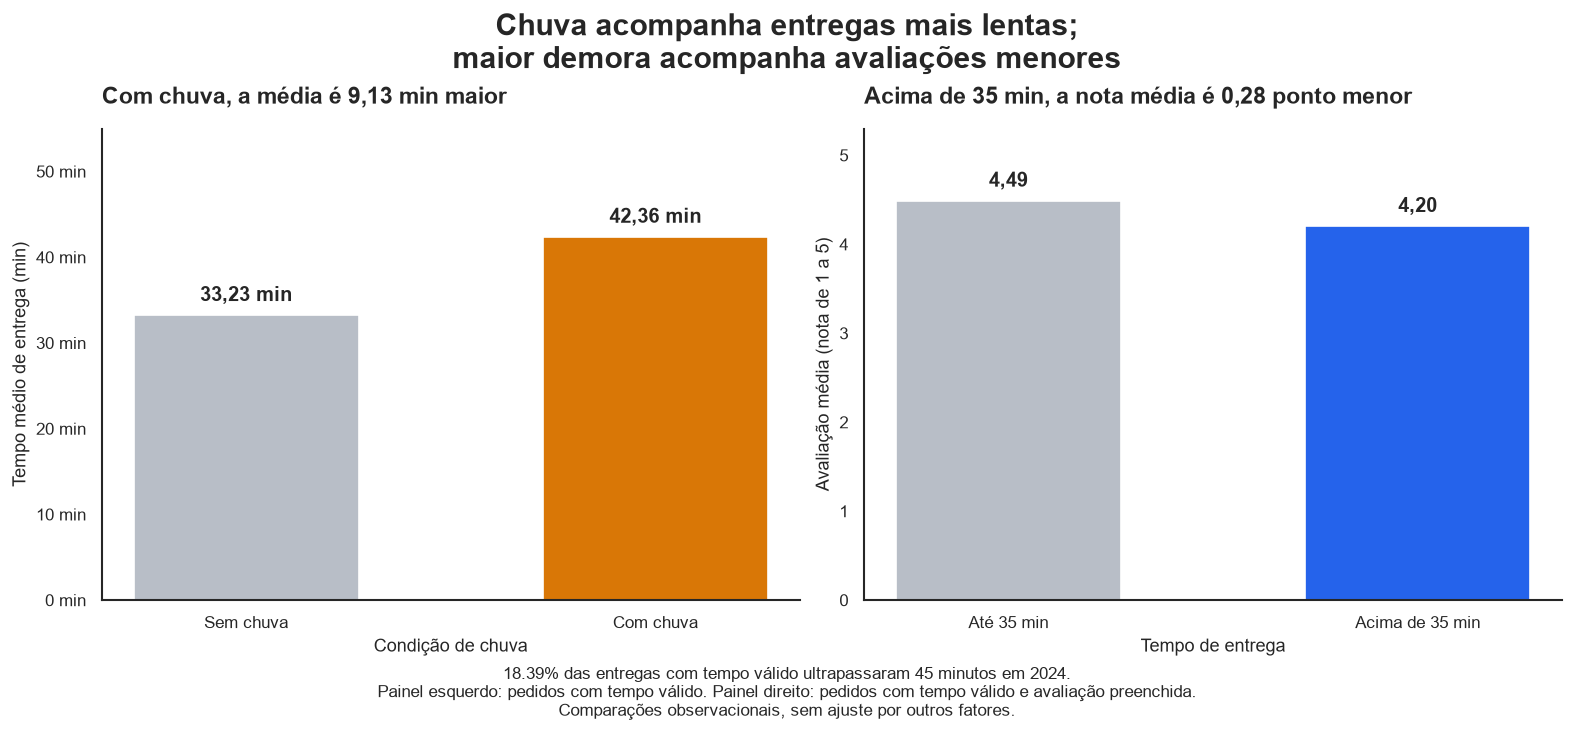

Figura salva em: C:\Users\debor\OneDrive\Área de Trabalho\ADA\projeto_delivery\saidas\figura_principal.png


In [159]:
# Sua solução aqui
from pathlib import Path

# Painel A: tempo médio com e sem chuva
tempos_chuva = (
    pedidos_2024.dropna(subset=["tempo_entrega_min", "chuva"])
    .groupby("chuva")["tempo_entrega_min"]
    .mean()
    .reindex([False, True])
)

diferenca_tempo = tempos_chuva.loc[True] - tempos_chuva.loc[False]

# Painel B: avaliação média por faixa de tempo
dados_notas = pedidos_2024.dropna(
    subset=["tempo_entrega_min", "avaliacao"]
)

nota_ate_35 = dados_notas.loc[
    dados_notas["tempo_entrega_min"] <= 35,
    "avaliacao"
].mean()

nota_acima_35 = dados_notas.loc[
    dados_notas["tempo_entrega_min"] > 35,
    "avaliacao"
].mean()

diferenca_nota = nota_ate_35 - nota_acima_35

# Indicador operacional
tempos_validos = pedidos_2024["tempo_entrega_min"].dropna()
percentual_acima_45 = tempos_validos.gt(45).mean() * 100

# Criar uma única figura com dois painéis
fig, eixos = plt.subplots(
    1, 2,
    figsize=(13, 6),
    layout="constrained"
)

# Painel A
barras_tempo = eixos[0].bar(
    ["Sem chuva", "Com chuva"],
    tempos_chuva.values,
    color=[CORES_CHUVA[False], CORES_CHUVA[True]],
    width=0.55
)

eixos[0].bar_label(
    barras_tempo,
    labels=[
        f"{valor:.2f} min".replace(".", ",")
        for valor in tempos_chuva.values
    ],
    padding=6,
    fontsize=12,
    fontweight="bold"
)

eixos[0].set_title(
    f"Com chuva, a média é {diferenca_tempo:.2f} min maior".replace(".", ","),
    pad=15
)
eixos[0].set_xlabel("Condição de chuva")
eixos[0].set_ylabel("Tempo médio de entrega (min)")
eixos[0].set_ylim(0, 55)
eixos[0].yaxis.set_major_formatter(FORMATADOR_MINUTOS)

# Painel B
barras_notas = eixos[1].bar(
    ["Até 35 min", "Acima de 35 min"],
    [nota_ate_35, nota_acima_35],
    color=[CORES["neutro"], CORES["destaque"]],
    width=0.55
)

eixos[1].bar_label(
    barras_notas,
    labels=[
        f"{valor:.2f}".replace(".", ",")
        for valor in [nota_ate_35, nota_acima_35]
    ],
    padding=6,
    fontsize=12,
    fontweight="bold"
)

eixos[1].set_title(
    f"Acima de 35 min, a nota média é {diferenca_nota:.2f} ponto menor"
    .replace(".", ","),
    pad=15
)
eixos[1].set_xlabel("Tempo de entrega")
eixos[1].set_ylabel("Avaliação média (nota de 1 a 5)")
eixos[1].set_ylim(0, 5.3)
eixos[1].set_yticks(range(6))

fig.suptitle(
    "Chuva acompanha entregas mais lentas;\n"
    "maior demora acompanha avaliações menores",
    fontsize=18,
    fontweight="bold"
)

fig.supxlabel(
    f"{percentual_acima_45:.2f}% das entregas com tempo válido "
    "ultrapassaram 45 minutos em 2024.\n"
    "Painel esquerdo: pedidos com tempo válido. "
    "Painel direito: pedidos com tempo válido e avaliação preenchida.\n"
    "Comparações observacionais, sem ajuste por outros fatores.",
    fontsize=10
)

# Salvar a figura na pasta solicitada
pasta_saidas = Path("saidas")
pasta_saidas.mkdir(parents=True, exist_ok=True)

caminho_figura = pasta_saidas / "figura_principal.png"

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figura salva em:", caminho_figura.resolve())

### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

*Sua resposta aqui*

1. **Com chuva, o tempo médio de entrega foi 9,13 minutos maior**, passando de 33,23 para 42,36 minutos. O resultado veio das Tarefas 6.8 e 9.1, com teste de Mann–Whitney. Essa diferença deve ser considerada no planejamento da operação e dos prazos em dias chuvosos.

2. **Entregas acima de 35 minutos receberam avaliação média de 4,20, contra 4,49 nas entregas até 35 minutos**, uma diferença de aproximadamente 0,28 ponto. A comparação veio das Tarefas 7.7 e 9.3, com Spearman e Mann–Whitney. A associação reforça a importância de acompanhar a demora como um fator relacionado à satisfação.

3. **Uma promessa de entrega em até 45 minutos teria sido descumprida em 1.476 pedidos, ou 18,39% das entregas com tempo válido.** O resultado veio da Tarefa 5.4. Esse percentual ajuda a diretoria a avaliar se o prazo prometido é compatível com a capacidade operacional.

4. **Em julho, o uso de cupons chegou a 45,62% e o movimento atingiu 26,52 pedidos por dia, contra 21 em junho.** O resultado veio das Tarefas 6.7 e 7.8. O aumento simultâneo merece atenção no planejamento das campanhas, mas é necessário avaliar custos e retorno antes de atribuir o crescimento aos cupons.

5. **O ticket mediano variou de R$ 38,42 em Doces a R$ 107,97 em Japonesa, uma diferença de R$ 69,55.** O resultado veio das Tarefas 6.3 e 9.4, com diferença global identificada por Kruskal–Wallis. Essa variação mostra que metas de ticket e análises de desempenho devem considerar o tipo de cozinha.

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

| Recomendação | Achados que sustentam | Métrica para acompanhar |
|---|---|---|
| **Planejar reforço de entregadores nos períodos de maior demanda e em dias de chuva**, começando com um piloto nas sextas e sábados, nos horários de almoço e jantar. | A chuva esteve associada a mais 9,13 minutos de entrega, e 18,39% das entregas válidas ultrapassaram 45 minutos. Os picos foram identificados nas Tarefas 6.6 e 7.5. | Percentual de entregas acima de 45 minutos e tempo mediano, separados por chuva, dia e horário. |
| **Criar um alerta para pedidos que se aproximem de 35 minutos**, permitindo verificar atrasos com o restaurante e atualizar a previsão para o cliente. Avaliar o resultado em um piloto. | Pedidos acima de 35 minutos receberam avaliação média aproximadamente 0,28 ponto menor. O corte funciona como referência operacional para o piloto. | Percentual de pedidos acima de 35 minutos, avaliação média e percentual de pedidos avaliados, comparando piloto e grupo de comparação. |
| **Testar a próxima campanha de cupons com grupos sorteados com e sem oferta**, definindo previamente o custo máximo da campanha e acompanhando compras posteriores. | Julho apresentou maior uso de cupons e aumento do movimento, mas a análise observacional não permite atribuir o crescimento à campanha. | Pedidos por cliente, margem após o custo do incentivo e taxa de recompra em 30 dias. Para isso, será necessário registrar o identificador do cliente e os custos. |

*Sua resposta aqui*

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

*Sua resposta aqui*

- Os dados mostram relações, mas não permitem afirmar que uma coisa causou a outra. Por exemplo, não podemos dizer que o cupom foi o responsável pelo aumento dos pedidos em julho.

- A base não tem um código para identificar cada cliente. Por isso, não conseguimos saber se ele voltou a comprar ou se ficou fidelizado depois de usar um cupom.

- Não temos os custos dos pedidos e dos descontos. Assim, não conseguimos dizer se a campanha trouxe lucro para a empresa.

- Nem todos os clientes avaliaram os pedidos. As notas analisadas podem não representar a opinião de quem não respondeu.

- Alguns pedidos ficaram sem distância ou com tempo de entrega inválido. Esses valores ficaram fora das análises que precisavam dessas informações.

- A base tem somente dados de 2024. Precisaríamos de outros anos para saber se os mesmos comportamentos se repetem.

- Pedidos da mesma cidade e do mesmo dia podem ter passado pelas mesmas condições. Isso pode influenciar os resultados dos testes, que trataram cada pedido como uma observação independente.

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [160]:
# Sua solução aqui
from pathlib import Path

# Colunas originais que permaneceram na base tratada
colunas_originais = [
    coluna for coluna in bruto.columns
    if coluna in df.columns
]

# Colunas criadas e solicitadas no projeto
colunas_criadas = [
    "data",
    "mes",
    "hora",
    "dia_semana",
    "tempo_invalido",
    "distancia_invalida",
    "pedido_grande"
]

# Selecionar as colunas que serão publicadas
colunas_publicacao = colunas_originais + colunas_criadas
base_limpa = df[colunas_publicacao].copy()

# Criar a pasta e salvar o CSV sem o índice
pasta_saidas = Path("saidas")
pasta_saidas.mkdir(parents=True, exist_ok=True)

caminho_base = pasta_saidas / "delivery_pedidos_limpo.csv"

base_limpa.to_csv(
    caminho_base,
    index=False,
    encoding="utf-8-sig"
)

# Gerar o dicionário automaticamente
dicionario_dados = pd.DataFrame({
    "Coluna": base_limpa.columns,
    "Tipo": [
        str(base_limpa[coluna].dtype)
        for coluna in base_limpa.columns
    ],
    "% de faltantes": [
        base_limpa[coluna].isna().mean() * 100
        for coluna in base_limpa.columns
    ],
    "Exemplo de valor": [
        str(next(
            iter(base_limpa[coluna].dropna()),
            "Sem valor preenchido"
        ))
        for coluna in base_limpa.columns
    ]
})

dicionario_dados["% de faltantes"] = (
    dicionario_dados["% de faltantes"].round(2)
)

print("Base limpa salva em:", caminho_base.resolve())
print("Linhas e colunas:", base_limpa.shape)

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(dicionario_dados)

Base limpa salva em: C:\Users\debor\OneDrive\Área de Trabalho\ADA\projeto_delivery\saidas\delivery_pedidos_limpo.csv
Linhas e colunas: (8058, 23)


,Coluna,Tipo,% de faltantes,Exemplo de valor
0,pedido_id,int64,0.00,500000
1,data_hora,datetime64[us],0.00,2024-01-01 11:21:00
2,cidade,str,0.00,São Paulo
3,bairro,str,0.00,Tatuapé
4,restaurante_id,str,0.00,R912
5,tipo_cozinha,str,0.00,Hambúrguer
6,plataforma,str,0.00,Android
7,forma_pagamento,str,0.00,Pix
8,cupom,bool,0.00,False
9,cliente_novo,bool,0.00,False


A base tratada foi salva em `saidas/delivery_pedidos_limpo.csv`,
sem o índice e sem as colunas auxiliares usadas nos cálculos.

Foram mantidas as colunas originais após a limpeza, as colunas
de data e as flags `tempo_invalido`, `distancia_invalida`
e `pedido_grande`.

Também foi gerado automaticamente um dicionário com o nome
de cada coluna, o tipo no notebook, o percentual de faltantes
e um exemplo de valor preenchido.

Os valores ausentes que decidimos manter continuam na base.
Os pedidos grandes também foram preservados.

Como o CSV não guarda os tipos do pandas, as conversões
necessárias devem ser feitas novamente ao carregar o arquivo.

### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

*Sua resposta aqui*

## 6. Principais achados

![Chuva, tempo de entrega e avaliação dos clientes](saidas/figura_principal.png)

*Pedidos de 2024. À esquerda, tempo médio de entrega com e sem chuva.
À direita, avaliação média dos pedidos entregues até e acima de
35 minutos. Os cálculos consideram tempos válidos e, no painel
de avaliação, somente pedidos com nota preenchida.*

1. **Com chuva, as entregas demoraram em média 9,13 minutos a mais.**
   O tempo médio foi de 42,36 minutos com chuva e 33,23 sem chuva.
   O resultado veio das Tarefas 6.8 e 9.1, com teste de Mann–Whitney.
   Essa diferença precisa ser considerada no planejamento das
   entregas e dos prazos em dias chuvosos.

2. **Pedidos entregues acima de 35 minutos tiveram avaliação média
   aproximadamente 0,28 ponto menor.**
   A média foi de 4,20, contra 4,49 nos pedidos entregues até
   35 minutos. A comparação veio das Tarefas 7.7 e 9.3, com
   Spearman e Mann–Whitney. O resultado mostra que a demora
   merece atenção no acompanhamento da satisfação dos clientes.

3. **Uma promessa de entrega em até 45 minutos teria sido
   descumprida em 1.476 pedidos.**
   Isso representa 18,39% dos 8.025 pedidos com tempo válido,
   conforme a Tarefa 5.4. Esse percentual ajuda a avaliar se
   o prazo prometido está de acordo com a capacidade da operação.

4. **Em julho, 45,62% dos pedidos usaram cupom e a média diária
   chegou a 26,52 pedidos, contra 21 em junho.**
   O resultado veio das Tarefas 6.7 e 7.8. O aumento coincidiu
   com a campanha, mas não permite afirmar que foi causado
   pelos cupons. É necessário acompanhar também os custos
   e o retorno das próximas campanhas.

5. **O ticket mediano variou de R$ 38,42 em Doces a R$ 107,97
   em Japonesa.**
   A diferença foi de R$ 69,55, conforme as Tarefas 6.3 e 9.4.
   O teste de Kruskal–Wallis identificou uma diferença global
   entre as cozinhas. Por isso, as metas de ticket devem
   considerar o tipo de cozinha.

As comparações mostram associações, sem comprovar causa e efeito.
Os testes e suas limitações estão detalhados no notebook.

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |